## Загрузка и описание данных

In [1]:
# pip install phik

In [2]:
# импортируем необходимые библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st
import numpy as np
import re
# import phik
# from phik.report import plot_correlation_matrix
# from phik import report

In [3]:
# отключаем предупреджения
import warnings
warnings.simplefilter('ignore')
pd.set_option('display.max_columns', None)

In [4]:
import hashlib
import io
import urllib.request
from pathlib import Path

DATA_URL = "https://datahub.io/core/speed-dating/_r/-/data/speed-dating.csv"
DATA_PATH = Path("speed-dating.csv")

if DATA_PATH.exists():  # есть локальная копия — берём её
    raw = DATA_PATH.read_bytes()
else:  # иначе скачиваем с сайта
    try:
        raw = urllib.request.urlopen(DATA_URL, timeout=60).read()
    except OSError as e:
        raise RuntimeError(f"Нет локальной копии {DATA_PATH.resolve()}, а скачать {DATA_URL} не удалось: {e}") from None
print("SHA-256 файла данных:", hashlib.sha256(raw).hexdigest())
df = pd.read_csv(io.BytesIO(raw))

SHA-256 файла данных: 5f16a947d24289d548b89cb38878ca01e93ce01070ecb76f30b3a98d85bcdcbf

In [6]:
df.head(5)

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,expected_num_matches,d_expected_happy_with_sd_people,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
0,0,1,female,21.0,27.0,6,[4-6],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,35.0,20.0,20.0,20.0,0.0,5.0,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],6.0,8.0,8.0,8.0,8.0,6.0,[6-8],[6-8],[6-8],[6-8],[6-8],[6-8],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],6.0,9.0,7.0,7.0,6.0,5.0,[6-8],[9-10],[6-8],[6-8],[6-8],[0-5],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.14,[0-0.33],3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,6.0,[6-8],[5-6],0.0,1,0,0
1,0,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,60.0,0.0,0.0,40.0,0.0,0.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7.0,8.0,10.0,7.0,7.0,5.0,[6-8],[6-8],[9-10],[6-8],[6-8],[0-5],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],7.0,8.0,7.0,8.0,5.0,6.0,[6-8],[6-8],[6-8],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.54,[0.33-1],3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,5.0,[6-8],[5-6],1.0,1,0,0
2,1,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american','asian/pacific islander/asian-american',1,2.0,4.0,[2-5],[2-5],law,19.0,18.0,19.0,18.0,14.0,12.0,[16-20],[16-20],[16-20],[16-20],[0-15],[0-15],10.0,10.0,10.0,10.0,10.0,10.0,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],5.0,8.0,9.0,8.0,5.0,7.0,[0-5],[6-8],[9-10],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.16,[0-0.33],3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,NaN,[6-8],[0-4],1.0,1,1,1
3,0,1,female,21.0,23.0,2,[2-3],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,30.0,5.0,15.0,40.0,5.0,5.0,[21-100

<table>
    <tbody>
        <tr><th>Переменная</th><th>Описание</th></tr>
        <tr><td>has_null</td><td>Служебный флаг: содержит ли строка пропуски (1 — есть, 0 — нет)</td></tr>
        <tr><td>wave</td><td>Номер волны (серии) эксперимента</td></tr>
        <tr><td>gender</td><td>Пол участника (female / male)</td></tr>
        <tr><td>age</td><td>Возраст участника</td></tr>
        <tr><td>age_o</td><td>Возраст партнёра</td></tr>
        <tr><td>d_age</td><td>Абсолютная разница в возрасте |age − age_o|, лет (единственная настоящая разность среди d_*; если один из возрастов пропущен, значение неверно — заменяем на NaN)</td></tr>
        <tr><td>d_d_age</td><td>Бин (категория) разницы в возрасте d_age</td></tr>
        <tr><td>race</td><td>Раса участника (текстовая категория)</td></tr>
        <tr><td>race_o</td><td>Раса партнёра (текстовая категория)</td></tr>
        <tr><td>samerace</td><td>Совпадает ли раса участников: 1 — да, 0 — нет</td></tr>
        <tr><td>importance_same_race</td><td>Важность того, чтобы партнёр был той же расы (шкала)</td></tr>
        <tr><td>importance_same_religion</td><td>Важность того, чтобы партнёр исповедовал ту же религию (шкала)</td></tr>
        <tr><td>d_importance_same_race</td><td>Бин (категория) важности совпадения расы</td></tr>
        <tr><td>d_importance_same_religion</td><td>Бин (категория) важности совпадения религии</td></tr>
        <tr><td>field</td><td>Область обучения / специальность (категория)</td></tr>
        <tr><td>pref_o_attractive</td><td>Предпочтение партнёра: важность привлекательности (шкала)</td></tr>
        <tr><td>pref_o_sincere</td><td>Предпочтение партнёра: важность искренности (шкала)</td></tr>
        <tr><td>pref_o_intelligence</td><td>Предпочтение партнёра: важность интеллекта (шкала)</td></tr>
        <tr><td>pref_o_funny</td><td>Предпочтение партнёра: важность чувства юмора (шкала)</td></tr>
        <tr><td>pref_o_ambitious</td><td>Предпочтение партнёра: важность амбициозности (шкала)</td></tr>
        <tr><td>pref_o_shared_interests</td><td>Предпочтение партнёра: важность общих интересов (шкала)</td></tr>
        <tr><td>d_pref_o_attractive</td><td>Бин (категория) предпочтения партнёра (привлекательность)</td></tr>
        <tr><td>d_pref_o_sincere</td><td>Бин (категория) предпочтения партнёра (искренность)</td></tr>
        <tr><td>d_pref_o_intelligence</td><td>Бин (категория) предпочтения партнёра (интеллект)</td></tr>
        <tr><td>d_pref_o_funny</td><td>Бин (категория) предпочтения партнёра (юмор)</td></tr>
        <tr><td>d_pref_o_ambitious</td><td>Бин (категория) предпочтения партнёра (амбициозность)</td></tr>
        <tr><td>d_pref_o_shared_interests</td><td>Бин (категория) предпочтения партнёра (общие интересы)</td></tr>
        <tr><td>attractive_o</td><td>Оценка, которую партнёр дал моей привлекательности (вечер мероприятия)</td></tr>
        <tr><td>sinsere_o</td><td>Оценка, которую партнёр дал моей искренности (вечер мероприятия)</td></tr>
        <tr><td>intelligence_o</td><td>Оценка, которую партнёр дал моему интеллекту (вечер мероприятия)</td></tr>
        <tr><td>funny_o</td><td>Оценка, которую партнёр дал моему чувству юмора (вечер мероприятия)</td></tr>
        <tr><td>ambitous_o</td><td>Оценка, которую партнёр дал моей амбициозности (вечер мероприятия)</td></tr>
        <tr><td>shared_interests_o</td><td>Оценка, которую партнёр дал нашим общим интересам (вечер мероприятия)</td></tr>
        <tr><td>d_attractive_o</td><td>Бин (категория) оценки партнёром привлекательности</td></tr>
        <tr><td>d_sinsere_o</td><td>Бин (категория) оценки партнёром искренности</td></tr>
        <tr><td>d_intelligence_o</td><td>Бин (категория) оценки партнёром интеллекта</td></tr>
        <tr><td>d_funny_o</td><td>Бин (категория) оценки партнёром юмора</td></tr>
        <tr><td>d_ambitous_o</td><td>Бин (категория) оценки партнёром амбициозности</td></tr>
        <tr><td>d_shared_interests_o</td><td>Бин (категория) оценки партнёром общих интересов</td></tr>
        <tr><td>attractive_important</td><td>Важность привлекательности при моём выборе партнёра (шкала)</td></tr>
        <tr><td>sincere_important</td><td>Важность искренности при моём выборе партнёра (шкала)</td></tr>
        <tr><td>intellicence_important</td><td>Важность интеллекта при моём выборе партнёра (шкала)</td></tr>
        <tr><td>funny_important</td><td>Важность чувства юмора при моём выборе партнёра (шкала)</td></tr>
        <tr><td>ambtition_important</td><td>Важность амбициозности при моём выборе партнёра (шкала)</td></tr>
        <tr><td>shared_interests_important</td><td>Важность общих интересов при моём выборе партнёра (шкала)</td></tr>
        <tr><td>d_attractive_important</td><td>Бин (категория) важности привлекательности</td></tr>
        <tr><td>d_sincere_important</td><td>Бин (категория) важности искренности</td></tr>
        <tr><td>d_intellicence_important</td><td>Бин (категория) важности интеллекта</td></tr>
        <tr><td>d_funny_important</td><td>Бин (категория) важности юмора</td></tr>
        <tr><td>d_ambtition_important</td><td>Бин (категория) важности амбициозности</td></tr>
        <tr><td>d_shared_interests_important</td><td>Бин (категория) важности общих интересов</td></tr>
        <tr><td>attractive</td><td>Моя самооценка по привлекательности (до мероприятия)</td></tr>
        <tr><td>sincere</td><td>Моя самооценка по искренности</td></tr>
        <tr><td>intelligence</td><td>Моя самооценка по интеллекту</td></tr>
        <tr><td>funny</td><td>Моя самооценка по чувству юмора</td></tr>
        <tr><td>ambition</td><td>Моя самооценка по амбициозности</td></tr>
        <tr><td>d_attractive</td><td>Бин (категория) самооценки привлекательности</td></tr>
        <tr><td>d_sincere</td><td>Бин (категория) самооценки искренности</td></tr>
        <tr><td>d_intelligence</td><td>Бин (категория) самооценки интеллекта</td></tr>
        <tr><td>d_funny</td><td>Бин (категория) самооценки юмора</td></tr>
        <tr><td>d_ambition</td><td>Бин (категория) самооценки амбициозности</td></tr>
        <tr><td>attractive_partner</td><td>Моя оценка привлекательности партнёра</td></tr>
        <tr><td>sincere_partner</td><td>Моя оценка искренности партнёра</td></tr>
        <tr><td>intelligence_partner</td><td>Моя оценка интеллекта партнёра</td></tr>
        <tr><td>funny_partner</td><td>Моя оценка чувства юмора партнёра</td></tr>
        <tr><td>ambition_partner</td><td>Моя оценка амбициозности партнёра</td></tr>
        <tr><td>shared_interests_partner</td><td>Моя оценка общих интересов с партнёром</td></tr>
        <tr><td>d_attractive_partner</td><td>Бин (категория) моей оценки привлекательности партнёра</td></tr>
        <tr><td>d_sincere_partner</td><td>Бин (категория) моей оценки искренности партнёра</td></tr>
        <tr><td>d_intelligence_partner</td><td>Бин (категория) моей оценки интеллекта партнёра</td></tr>
        <tr><td>d_funny_partner</td><td>Бин (категория) моей оценки юмора партнёра</td></tr>
        <tr><td>d_ambition_partner</td><td>Бин (категория) моей оценки амбициозности партнёра</td></tr>
        <tr><td>d_shared_interests_partner</td><td>Бин (категория) моей оценки общих интересов партнёра</td></tr>
        <tr><td>sports</td><td>Мой интерес к спорту (шкала 1–10)</td></tr>
        <tr><td>tvsports</td><td>Мой интерес к спортивным трансляциям (шкала 1–10)</td></tr>
        <tr><td>exercise</td><td>Мой интерес к фитнесу/упражнениям (шкала 1–10)</td></tr>
        <tr><td>dining</td><td>Мой интерес к ресторанам/кулинарии (шкала 1–10)</td></tr>
        <tr><td>museums</td><td>Мой интерес к музеям (шкала 1–10)</td></tr>
        <tr><td>art</td><td>Мой интерес к искусству (шкала 1–10)</td></tr>
        <tr><td>hiking</td><td>Мой интерес к походам (шкала 1–10)</td></tr>
        <tr><td>gaming</td><td>Мой интерес к видеоиграм (шкала 1–10)</td></tr>
        <tr><td>clubbing</td><td>Мой интерес к клубам (шкала 1–10)</td></tr>
        <tr><td>reading</td><td>Мой интерес к чтению (шкала 1–10)</td></tr>
        <tr><td>tv</td><td>Мой интерес к телевидению (шкала 1–10)</td></tr>
        <tr><td>theater</td><td>Мой интерес к театру (шкала 1–10)</td></tr>
        <tr><td>movies</td><td>Мой интерес к кино (шкала 1–10)</td></tr>
        <tr><td>concerts</td><td>Мой интерес к концертам (шкала 1–10)</td></tr>
        <tr><td>music</td><td>Мой интерес к музыке (шкала 1–10)</td></tr>
        <tr><td>shopping</td><td>Мой интерес к шопингу (шкала 1–10)</td></tr>
        <tr><td>yoga</td><td>Мой интерес к йоге (шкала 1–10)</td></tr>
        <tr><td>d_sports</td><td>Бин (категория) интереса к спорту</td></tr>
        <tr><td>d_tvsports</td><td>Бин (категория) интереса к спортивным трансляциям</td></tr>
        <tr><td>d_exercise</td><td>Бин (категория) интереса к фитнесу</td></tr>
        <tr><td>d_dining</td><td>Бин (категория) интереса к ресторанам</td></tr>
        <tr><td>d_museums</td><td>Бин (категория) интереса к музеям</td></tr>
        <tr><td>d_art</td><td>Бин (категория) интереса к искусству</td></tr>
        <tr><td>d_hiking</td><td>Бин (категория) интереса к походам</td></tr>
        <tr><td>d_gaming</td><td>Бин (категория) интереса к видеоиграм</td></tr>
        <tr><td>d_clubbing</td><td>Бин (категория) интереса к клубам</td></tr>
        <tr><td>d_reading</td><td>Бин (категория) интереса к чтению</td></tr>
        <tr><td>d_tv</td><td>Бин (категория) интереса к телевидению</td></tr>
        <tr><td>d_theater</td><td>Бин (категория) интереса к театру</td></tr>
        <tr><td>d_movies</td><td>Бин (категория) интереса к кино</td></tr>
        <tr><td>d_concerts</td><td>Бин (категория) интереса к концертам</td></tr>
        <tr><td>d_music</td><td>Бин (категория) интереса к музыке</td></tr>
        <tr><td>d_shopping</td><td>Бин (категория) интереса к шопингу</td></tr>
        <tr><td>d_yoga</td><td>Бин (категория) интереса к йоге</td></tr>
        <tr><td>interests_correlate</td><td>Корреляция между моими интересами и интересами партнёра ([-1; 1])</td></tr>
        <tr><td>d_interests_correlate</td><td>Бин (категория) корреляции интересов</td></tr>
        <tr><td>expected_happy_with_sd_people</td><td>Ожидаемый уровень счастья от общения с участниками быстрых свиданий (шкала)</td></tr>
        <tr><td>expected_num_interested_in_me</td><td>Сколько из 20 участников, по моему мнению, будут заинтересованы во мне (анкета до мероприятия; вопрос задавали только в волнах 1–5)</td></tr>
        <tr><td>expected_num_matches</td><td>Сколько совпадений я ожидаю получить (оценка в конце вечера, после всех встреч)</td></tr>
        <tr><td>d_expected_happy_with_sd_people</td><td>Бин (категория) ожидаемого счастья</td></tr>
        <tr><td>d_expected_num_interested_in_me</td><td>Бин (категория) ожидаемого числа заинтересованных</td></tr>
        <tr><td>d_expected_num_matches</td><td>Бин (категория) ожидаемого числа совпадений</td></tr>
        <tr><td>like</td><td>Насколько мне понравился партнёр в целом (шкала 1–10)</td></tr>
        <tr><td>guess_prob_liked</td><td>Насколько вероятным я считаю, что партнёр скажет мне «да» (шкала 1–10, не вероятность)</td></tr>
        <tr><td>d_like</td><td>Бин (категория) признака «понравился»</td></tr>
        <tr><td>d_guess_prob_liked</td><td>Бин (категория) оценки вероятности</td></tr>
        <tr><td>met</td><td>Встречались ли мы с партнёром раньше (бинарный: 1 — да, 0 — нет)</td></tr>
        <tr><td>decision</td><td>Моё решение: 1 — пригласить на свидание, 0 — нет</td></tr>
        <tr><td>decision_o</td><td>Решение партнёра: 1 — пригласить, 0 — нет</td></tr>
        <tr><td>match</td><td>Совпадение (оба сказали «да»): 1 — да, 0 — нет</td></tr>
    </tbody>
</table>

Таким образом, показатели можно разделить на следующие группы:

## 1. Собственные показатели (обо мне)

**Демография:**
`age`, `gender`, `race`, `field`

**Самооценка:**
`attractive`, `sincere`, `intelligence`, `funny`, `ambition`

**Мои интересы:**
`sports`, `tvsports`, `exercise`, `dining`, `museums`, `art`, `hiking`, `gaming`, `clubbing`, `reading`, `tv`, `theater`, `movies`, `concerts`, `music`, `shopping`, `yoga`

**Мои предпочтения — что я ценю в партнёре:**
`attractive_important`, `sincere_important`, `intellicence_important`, `funny_important`, `ambtition_important`, `shared_interests_important`

**Мои установки:**
`importance_same_race`, `importance_same_religion`

**Мои ожидания:**
`expected_happy_with_sd_people`, `expected_num_interested_in_me` (анкета до мероприятия), `expected_num_matches` (оценка в конце вечера, после встреч)

**Моя оценка партнёра:**
`attractive_partner`, `sincere_partner`, `intelligence_partner`, `funny_partner`, `ambition_partner`, `shared_interests_partner`

## 2. Показатели партнёра

**Демография партнёра:**
`age_o`, `race_o`

**Предпочтения партнёра (что партнёр ценит во мне):**

`pref_o_attractive`, `pref_o_sincere`, `pref_o_intelligence`, `pref_o_funny`, `pref_o_ambitious`, `pref_o_shared_interests`

**Оценка партнёром меня:**

`attractive_o`, `sinsere_o`, `intelligence_o`, `funny_o`, `ambitous_o`, `shared_interests_o`

## 3. Бины исходных признаков (`d_*`)

Колонки `d_*` — не разности между участниками, а категории (бины) исходного признака того же человека: например, `d_art` — уровень собственного интереса к искусству (`[0-5]`, `[6-8]`, `[9-10]`). Пропуск исходного признака попадает в нижний бин. Настоящая разность одна — `d_age` = |`age` − `age_o`| (когда оба возраста известны), а `d_d_age` — её бин.

**Возраст:**
`d_age`, `d_d_age`

**Установки:**
`d_importance_same_race`, `d_importance_same_religion`

**Предпочтения партнёра:**
`d_pref_o_attractive`, `d_pref_o_sincere`, `d_pref_o_intelligence`, `d_pref_o_funny`, `d_pref_o_ambitious`, `d_pref_o_shared_interests`

**Оценка меня партнёром:**
`d_attractive_o`, `d_sinsere_o`, `d_intelligence_o`, `d_funny_o`, `d_ambitous_o`, `d_shared_interests_o`

**Мои предпочтения:**
`d_attractive_important`, `d_sincere_important`, `d_intellicence_important`, `d_funny_important`, `d_ambtition_important`, `d_shared_interests_important`

**Самооценка:**
`d_attractive`, `d_sincere`, `d_intelligence`, `d_funny`, `d_ambition`

**Моя оценка партнёра:**
`d_attractive_partner`, `d_sincere_partner`, `d_intelligence_partner`, `d_funny_partner`, `d_ambition_partner`, `d_shared_interests_partner`

**Интересы:**
`d_sports`, `d_tvsports`, `d_exercise`, `d_dining`, `d_museums`, `d_art`, `d_hiking`, `d_gaming`, `d_clubbing`, `d_reading`, `d_tv`, `d_theater`, `d_movies`, `d_concerts`, `d_music`, `d_shopping`, `d_yoga`

**Корреляция интересов:**
`d_interests_correlate`

**Ожидания:**
`d_expected_happy_with_sd_people`, `d_expected_num_interested_in_me`, `d_expected_num_matches`

**Отношение/исход:**
`d_like`, `d_guess_prob_liked`

## 4. Компоненты target и близкие к нему поля

**Компоненты target** (`match` = `decision` И `decision_o`):
`decision`, `decision_o`

**Late-proxy** — собираются после встречи в той же анкете, что и оценки партнёра, но ближе всего к собственному решению:
`like`, `guess_prob_liked`, а также их бины `d_like`, `d_guess_prob_liked`

**Характеристики пары** (не прокси):
`samerace`, `interests_correlate`, `met` (встречались ли раньше)
    
## 5. Служебные

`has_null`, `wave`

## 6. Итог

`match`

In [7]:
# Так как столбцов много, напишем ф-ю для поиска русского описания 
col_ru = {
    "has_null": "служебный флаг пропусков",
    "wave": "номер волны эксперимента",
    "gender": "пол участника",
    "age": "возраст участника",
    "age_o": "возраст партнёра",
    "d_age": "абсолютная разница в возрасте |age − age_o|, лет",
    "d_d_age": "бин разницы в возрасте (диапазон)",
    "race": "раса участника",
    "race_o": "раса партнёра",
    "samerace": "совпадение расы (1/0)",
    "importance_same_race": "важность совпадения расы",
    "importance_same_religion": "важность совпадения религии",
    "d_importance_same_race": "категория (бин): важность совпадения расы (диапазон)",
    "d_importance_same_religion": "категория (бин): важность совпадения религии (диапазон)",
    "field": "область обучения / специальность",
    "pref_o_attractive": "предпочтение партнёра: привлекательность",
    "pref_o_sincere": "предпочтение партнёра: искренность",
    "pref_o_intelligence": "предпочтение партнёра: интеллект",
    "pref_o_funny": "предпочтение партнёра: юмор",
    "pref_o_ambitious": "предпочтение партнёра: амбициозность",
    "pref_o_shared_interests": "предпочтение партнёра: общие интересы",
    "d_pref_o_attractive": "категория (бин): предпочтение партнёра: привлекательность (диапазон)",
    "d_pref_o_sincere": "категория (бин): предпочтение партнёра: искренность (диапазон)",
    "d_pref_o_intelligence": "категория (бин): предпочтение партнёра: интеллект (диапазон)",
    "d_pref_o_funny": "категория (бин): предпочтение партнёра: юмор (диапазон)",
    "d_pref_o_ambitious": "категория (бин): предпочтение партнёра: амбициозность (диапазон)",
    "d_pref_o_shared_interests": "категория (бин): предпочтение партнёра: общие интересы (диапазон)",
    "attractive_o": "оценка партнёром моей привлекательности",
    "sinsere_o": "оценка партнёром моей искренности",
    "intelligence_o": "оценка партнёром моего интеллекта",
    "funny_o": "оценка партнёром моего юмора",
    "ambitous_o": "оценка партнёром моей амбициозности",
    "shared_interests_o": "оценка партнёром общих интересов",
    "d_attractive_o": "категория (бин): оценка партнёром привлекательности (диапазон)",
    "d_sinsere_o": "категория (бин): оценка партнёром искренности (диапазон)",
    "d_intelligence_o": "категория (бин): оценка партнёром интеллекта (диапазон)",
    "d_funny_o": "категория (бин): оценка партнёром юмора (диапазон)",
    "d_ambitous_o": "категория (бин): оценка партнёром амбициозности (диапазон)",
    "d_shared_interests_o": "категория (бин): оценка партнёром общих интересов (диапазон)",
    "attractive_important": "важность привлекательности при моём выборе",
    "sincere_important": "важность искренности при моём выборе",
    "intellicence_important": "важность интеллекта при моём выборе",
    "funny_important": "важность юмора при моём выборе",
    "ambtition_important": "важность амбициозности при моём выборе",
    "shared_interests_important": "важность общих интересов при моём выборе",
    "d_attractive_important": "категория (бин): важность привлекательности (диапазон)",
    "d_sincere_important": "категория (бин): важность искренности (диапазон)",
    "d_intellicence_important": "категория (бин): важность интеллекта (диапазон)",
    "d_funny_important": "категория (бин): важность юмора (диапазон)",
    "d_ambtition_important": "категория (бин): важность амбициозности (диапазон)",
    "d_shared_interests_important": "категория (бин): важность общих интересов (диапазон)",
    "attractive": "моя самооценка: привлекательность",
    "sincere": "моя самооценка: искренность",
    "intelligence": "моя самооценка: интеллект",
    "funny": "моя самооценка: юмор",
    "ambition": "моя самооценка: амбициозность",
    "d_attractive": "категория (бин): самооценка привлекательности (диапазон)",
    "d_sincere": "категория (бин): самооценка искренности (диапазон)",
    "d_intelligence": "категория (бин): самооценка интеллекта (диапазон)",
    "d_funny": "категория (бин): самооценка юмора (диапазон)",
    "d_ambition": "категория (бин): самооценка амбициозности (диапазон)",
    "attractive_partner": "моя оценка привлекательности партнёра",
    "sincere_partner": "моя оценка искренности партнёра",
    "intelligence_partner": "моя оценка интеллекта партнёра",
    "funny_partner": "моя оценка юмора партнёра",
    "ambition_partner": "моя оценка амбициозности партнёра",
    "shared_interests_partner": "моя оценка общих интересов",
    "d_attractive_partner": "категория (бин): оценка привлекательности партнёра (диапазон)",
    "d_sincere_partner": "категория (бин): оценка искренности партнёра (диапазон)",
    "d_intelligence_partner": "категория (бин): оценка интеллекта партнёра (диапазон)",
    "d_funny_partner": "категория (бин): оценка юмора партнёра (диапазон)",
    "d_ambition_partner": "категория (бин): оценка амбициозности партнёра (диапазон)",
    "d_shared_interests_partner": "категория (бин): оценка общих интересов (диапазон)",
    "sports": "интерес к спорту",
    "tvsports": "интерес к спортивным трансляциям",
    "exercise": "интерес к фитнесу",
    "dining": "интерес к ресторанам",
    "museums": "интерес к музеям",
    "art": "интерес к искусству",
    "hiking": "интерес к походам",
    "gaming": "интерес к видеоиграм",
    "clubbing": "интерес к клубам",
    "reading": "интерес к чтению",
    "tv": "интерес к телевидению",
    "theater": "интерес к театру",
    "movies": "интерес к кино",
    "concerts": "интерес к концертам",
    "music": "интерес к музыке",
    "shopping": "интерес к шопингу",
    "yoga": "интерес к йоге",
    "d_sports": "категория (бин): интерес к спорту (диапазон)",
    "d_tvsports": "категория (бин): интерес к спортивным трансляциям (диапазон)",
    "d_exercise": "категория (бин): интерес к фитнесу (диапазон)",
    "d_dining": "категория (бин): интерес к ресторанам (диапазон)",
    "d_museums": "категория (бин): интерес к музеям (диапазон)",
    "d_art": "категория (бин): интерес к искусству (диапазон)",
    "d_hiking": "категория (бин): интерес к походам (диапазон)",
    "d_gaming": "категория (бин): интерес к видеоиграм (диапазон)",
    "d_clubbing": "категория (бин): интерес к клубам (диапазон)",
    "d_reading": "категория (бин): интерес к чтению (диапазон)",
    "d_tv": "категория (бин): интерес к телевидению (диапазон)",
    "d_theater": "категория (бин): интерес к театру (диапазон)",
    "d_movies": "категория (бин): интерес к кино (диапазон)",
    "d_concerts": "категория (бин): интерес к концертам (диапазон)",
    "d_music": "категория (бин): интерес к музыке (диапазон)",
    "d_shopping": "категория (бин): интерес к шопингу (диапазон)",
    "d_yoga": "категория (бин): интерес к йоге (диапазон)",
    "interests_correlate": "корреляция интересов",
    "d_interests_correlate": "категория (бин): корреляция интересов (диапазон)",
    "expected_happy_with_sd_people": "ожидаемое счастье от быстрых свиданий",
    "expected_num_interested_in_me": "ожидаемое число заинтересованных во мне",
    "expected_num_matches": "ожидаемое число совпадений",
    "d_expected_happy_with_sd_people": "категория (бин): ожидаемое счастье (диапазон)",
    "d_expected_num_interested_in_me": "категория (бин): ожидаемое число заинтересованных (диапазон)",
    "d_expected_num_matches": "категория (бин): ожидаемое число совпадений (диапазон)",
    "like": "насколько понравился партнёр (шкала 1–10)",
    "guess_prob_liked": "насколько вероятным я считаю «да» от партнёра (шкала 1–10)",
    "d_like": "категория (бин): признак «понравился» (диапазон)",
    "d_guess_prob_liked": "категория (бин): оценка вероятности (диапазон)",
    "met": "встречались ли раньше",
    "decision": "моё решение (1/0)",
    "decision_o": "решение партнёра (1/0)",
    "match": "совпадение (1/0)",
}

def ru(col):
    """Возвращает русское описание столбца по его английскому имени"""
    return col_ru.get(col, f"[нет описания для '{col}']")

In [5]:
def describe_cols(cols):
    """Печатает таблицу: английское имя → русское описание"""
    rows = [{"столбец": c, "описание": ru(c)} for c in cols]
    display(pd.DataFrame(rows).set_index("столбец"))

In [8]:
describe_cols(["age", "age_o", "match", "decision", "attractive"])

,описание
столбец,
age,возраст участника
age_o,возраст партнёра
match,совпадение (1/0)
decision,моё решение (1/0)
attractive,моя самооценка: привлекательность


In [9]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Data columns (total 123 columns):
 #    Column                           Dtype  
---   ------                           -----  
 0    has_null                         int64  
 1    wave                             int64  
 2    gender                           object 
 3    age                              float64
 4    age_o                            float64
 5    d_age                            int64  
 6    d_d_age                          object 
 7    race                             object 
 8    race_o                           object 
 9    samerace                         int64  
 10   importance_same_race             float64
 11   importance_same_religion         float64
 12   d_importance_same_race           object 
 13   d_importance_same_religion       object 
 14   field                            object 
 15   pref_o_attractive                float64
 16   pref_o_sincere                   float64

In [10]:
# так как в датасете достаточно много категориальных признаков, выведем статистику сразу по количественным и категориальным
df.describe(include='all')

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,expected_num_matches,d_expected_happy_with_sd_people,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
count,8378.00000,8378.000000,8378,8283.000000,8274.000000,8378.000000,8378,8315,8305,8378.000000,8299.000000,8299.000000,8378,8378,8315,8289.000000,8289.000000,8289.000000,8280.000000,8271.000000,8249.000000,8378,8378,8378,8378,8378,8378,8166.000000,8091.000000,8072.000000,8018.000000,7656.000000,7302.000000,8378,8378,8378,8378,8378,8378,8299.000000,8299.000000,8299.000000,8289.000000,8279.000000,8257.000000,8378,8378,8378,8378,8378,8378,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,8378,8378,8378,8378,8378,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000,8378,8378,8378,8378,8378,8378,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8220.000000,8378,8277.000000,1800.000000,7205.000000,8378,8378,8378,8138.000000,8069.000000,8378,8378,8003.000000,8378.000000,8378.000000,8378.000000
unique,NaN,NaN,2,NaN,NaN,NaN,4,5,5,NaN,NaN,NaN,3,3,219,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,NaN,3,NaN,NaN,NaN,3,3,3,NaN,NaN,3,3,NaN,NaN,NaN,NaN
top,NaN,NaN,male,NaN,NaN,NaN,[2-3],european/caucasian-american,european/caucasian-american,NaN,NaN,NaN,[2-5],[0-1],business,NaN,NaN,NaN,NaN,NaN,NaN,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],NaN,NaN,NaN,NaN,NaN,NaN,[6-8],[6-8],[6-8],[6-8],[6-8],[0-5],NaN,NaN,NaN,NaN,NaN,NaN,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],NaN,NaN,NaN,NaN,NaN,[6-8],[9-10],[6-8],[6-8],[6-8],NaN,NaN,NaN,NaN,NaN,NaN,[6-8],[6-8],[6-8],[6-8],[6-8],[0-5],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[6-8],[0-5],[6-8],[6-8],[6-8],[6-8],[0-5],[0-5],[6-8],[6-8],[0-5],[6-8],[6-8],[6-8],[6-8],[0-5],[0-5],NaN,[0-0.33],NaN,NaN,NaN,[5-6],[0-3],[0-2],NaN,NaN,[6-8],[5-6],NaN,NaN,NaN,NaN
freq,NaN,NaN,4194,NaN,NaN,NaN,2406,4727,4722,NaN,NaN,NaN,3104,3111,631,NaN,NaN,NaN,NaN,NaN,NaN,3010,3820,4272,3870,6680,6085,NaN,NaN,NaN

In [11]:
# Посмотрим сколько строк имеют пропуски и какая это доля
print(int(df['has_null'].sum()))
print(round(int(df['has_null'].sum())/len(df['has_null']),2))

7330
0.87

In [12]:
df.describe() # только количественные

,has_null,wave,age,age_o,d_age,samerace,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive,sincere,intelligence,funny,ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,expected_num_matches,like,guess_prob_liked,met,decision,decision_o,match
count,8378.00000,8378.000000,8283.000000,8274.000000,8378.000000,8378.000000,8299.000000,8299.000000,8289.000000,8289.000000,8289.000000,8280.000000,8271.000000,8249.000000,8166.000000,8091.000000,8072.000000,8018.000000,7656.000000,7302.000000,8299.000000,8299.000000,8299.000000,8289.000000,8279.000000,8257.000000,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8220.000000,8277.000000,1800.000000,7205.000000,8138.000000,8069.000000,8003.000000,8378.000000,8378.000000,8378.000000
mean,0.87491,11.350919,26.358928,26.364999,4.185605,0.395799,3.784793,3.651645,22.495347,17.396867,20.270759,17.459714,10.685375,11.845930,6.190411,7.175256,7.369301,6.400599,6.778409,5.474870,22.514632,17.396389,20.265613,17.457043,10.682539,11.845111,7.084733,8.294935,7.704460,8.403965,7.578388,6.189995,7.175164,7.368597,6.400598,6.777524,5.474559,6.425232,4.575491,6.245813,7.783829,6.985781,6.714544,5.737077,3.881191,5.745993,7.678515,5.304133,6.776118,7.919629,6.825401,7.851066,5.631281,4.339197,0.196010,5.534131,5.570556,3.207814,6.134087,5.207523,0.049856,0.419909,0.419551,0.164717
std,0.33084,5.995903,3.566763,3.563648,4.596171,0.489051,2.845708,2.805237,12.569802,7.044003,6.782895,6.085526,6.126544,6.362746,1.950305,1.740575,1.550501,1.954078,1.794080,2.156163,12.587674,7.046700,6.783003,6.085239,6.124888,6.362154,1.395783,1.407460,1.564321,1.076608,1.778315,1.950169,1.740315,1.550453,1.953702,1.794055,2.156363,2.619024,2.801874,2.418858,1.754868,2.052232,2.263407,2.570207,2.620507,2.502218,2.006565,2.529135,2.235152,1.700927,2.156283,1.791827,2.608913,2.717612,0.303539,1.734059,4.762569,2.444813,1.841285,2.129565,0.282168,0.493573,0.493515,0.370947
min,0.00000,1.000000,18.000000,18.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,-0.830000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.00000,7.000000,24.000000,24.000000,1.000000,0.000000,1.000000,1.000000,15.000000,15.000000,17.390000,15.000000,5.000000,9.520000,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000,15.000000,15.000000,17.390000,15.000000,5.000000,9.520000,6.000000,8.000000,7.000000,8.000000,7.000000,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000,4.000000,2.000000,5.000000,7.000000,6.000000,5.000000,4.000000,2.000000,4.000000,7.000000,3.000000,5.000000,7.000000,5.000000,7.000000,4.000000,2.000000,-0.020000,5.000000,2.000000,2.000000,5.000000,4.000000,0.000000,0.000000,0.000000,0.000000
50%,1.00000,11.000000,26.000000,26.000000,3.000000,

In [13]:
print(f'Сумма дубликатов в файле: {df.duplicated().sum()}') # посчитаем сумму дубликатов в данных

Сумма дубликатов в файле: 0

In [14]:
print(f'Сумма пропусков в файле: {df.isna().sum().sum()}') # посчитаем сумму пропусков в данных

Сумма пропусков в файле: 18372

In [15]:
print(f'Сумма значений без пропусков в файле: {df.notna().sum().sum()}') # посчитаем сумму пропусков в данных

Сумма значений без пропусков в файле: 1012122

**Вывод**: В таблице 8378 строк (анкет) и 123 столбца (признаков). При этом полностью без пропусков только около 1048 строк — флаг has_null показывает, что 7330 строк (≈87,5%) содержат хотя бы один пропуск. То есть датасет «грязный» по своей природе, и это нужно учитывать при любом анализе.

Типы столбцов: 57 столбцов float64, 7 — int64, 59 — object. Важно: почти все d_* столбцы (бины исходных переменных) хранятся как object, потому что значения записаны диапазонами ([6-8], [0-15], [21-100]). Для числового анализа их нужно либо преобразовывать в числа (например, брать середину интервала), либо не использовать.

## Предбработка данных

### Работа с пропусками

In [16]:
def missing(data):
    print(f'Сумма пропусков по столбцам')
    missing = data.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    return missing

In [17]:
missing(df)

Сумма пропусков по столбцам

expected_num_interested_in_me    6578
expected_num_matches             1173
shared_interests_o               1076
shared_interests_partner         1067
ambitous_o                        722
ambition_partner                  712
met                               375
funny_o                           360
funny_partner                     350
guess_prob_liked                  309
intelligence_o                    306
intelligence_partner              296
sinsere_o                         287
sincere_partner                   277
like                              240
attractive_o                      212
attractive_partner                202
interests_correlate               158
pref_o_shared_interests           129
shared_interests_important        121
pref_o_ambitious                  107
attractive                        105
sincere                           105
intelligence                      105
funny                             105
ambition                          105
age_o       

In [18]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
missing_cols = miss.index 

share = df[missing_cols].isna().sum() / len(df) * 100
print(f'Доля пропусков по столбцам')
display(share.sort_values(ascending=False))

Доля пропусков по столбцам

expected_num_interested_in_me    78.515159
expected_num_matches             14.000955
shared_interests_o               12.843161
shared_interests_partner         12.735736
ambitous_o                        8.617809
ambition_partner                  8.498448
met                               4.476009
funny_o                           4.296968
funny_partner                     4.177608
guess_prob_liked                  3.688231
intelligence_o                    3.652423
intelligence_partner              3.533063
sinsere_o                         3.425639
sincere_partner                   3.306278
like                              2.864646
attractive_o                      2.530437
attractive_partner                2.411077
interests_correlate               1.885892
pref_o_shared_interests           1.539747
shared_interests_important        1.444259
pref_o_ambitious                  1.277154
attractive                        1.253282
sincere                           1.253282
intelligenc

При анализе структуры пропусков видно, что они распределены неравномерно. Во-первых, есть столбцы с экстремально высокой долей пропусков: expected_num_interested_in_me (78,5%), expected_num_matches (14,0%), shared_interests_o (12,8%), shared_interests_partner (12,7%). Во-вторых, целый ряд переменных имеет одинаковое число пропусков: 105 (attractive, sincere, intelligence, funny, ambition), 89 (funny_important, pref_o_sincere, pref_o_attractive, pref_o_intelligence) и 79 (tv, importance_same_race, importance_same_religion, attractive_important, sincere_important и др.). Такое совпадение вряд ли случайно.

Пропуски в датасете не являются полностью случайными. Предположительно, они могут возникнуть следующим образом:

- Часть респондентов не заполнила целые блоки анкеты, например, блок самооценок, блок предпочтений или блок интересов. Тогда пропуски концентрируются в одних и тех же строках внутри смысловой группы переменных, а число пропусков в столбцах этой группы совпадает. Причина может быть и технической (анкета не сохранилась, вопросы не отобразились) или организационной (респонденту выдали неполную версию анкеты).

- В «чувствительных» вопросах, таких как ожиданиях, оценках партнёра, самооценках, респонденты чаще пропускали ответ, потому что не хотели его давать (неловко/нет мнения/не захотели раскрывать). Это могло бы объяснить, почему у expected_num_interested_in_me пропусков 78,5%, а у соседнего по смыслу expected_num_matches только 14% (проверка ниже показывает другую причину: этот вопрос задавали только в волнах 1–5).

Можно выдвинуть гипотезы для проверки:
- **H1** Блочная организация пропусков. Внутри каждой группы переменных с одинаковым числом пропусков пропуски приходятся на одни и те же строки. 

- **H2** Связь с чувствительностью вопроса. Доля пропусков выше в переменных, требующих самооценки, оценки партнёра или ожиданий и ниже в нейтральных демографических и фактических вопросах.

Наибольшая доля пропусков — в `expected_num_interested_in_me` (78,5%), `expected_num_matches` (14,0%), `shared_interests_o` и `shared_interests_partner` (~12,8%). По смыслу эти колонки разные, поэтому и решения по ним разные:
- `expected_num_matches` — оценка числа совпадений, которую участник даёт в конце вечера, после встреч. Она близка к исходу, поэтому исключаем её из рассмотрения вместе с её бином `d_expected_num_matches`;
- `expected_num_interested_in_me` — вопрос анкеты до мероприятия, но его задавали только в волнах 1–5 (структурный пропуск, проверка ниже). Исключаем её вместе с бином `d_expected_num_interested_in_me` (там пропуски записаны в нижний бин) из-за пропусков, а не как прокси;
- `shared_interests_o` и `shared_interests_partner` — шестая взаимная оценка (наряду с внешностью, искренностью, интеллектом, юмором и амбициозностью), а не прокси `match`. Оставляем их.

In [19]:
cols_proxy = ["expected_num_matches", "d_expected_num_matches"]  # оценка числа совпадений в конце вечера и её бин — близки к исходу
df_clean = df.copy()
df_clean = df_clean.drop(columns=cols_proxy)
print("было столбцов:", df.shape[1], " стало:", df_clean.shape[1])

было столбцов: 123  стало: 121

Перейдём к проверке гипотез

In [20]:
# Проверим пропуски в самом большом блоке
df_dirty = df[df['tv'].isna()]

In [21]:
missing(df_dirty)

Сумма пропусков по столбцам

funny                            79
concerts                         79
expected_happy_with_sd_people    79
interests_correlate              79
yoga                             79
shopping                         79
music                            79
sports                           79
tvsports                         79
exercise                         79
dining                           79
museums                          79
art                              79
hiking                           79
gaming                           79
clubbing                         79
reading                          79
tv                               79
theater                          79
ambition                         79
movies                           79
intelligence                     79
attractive                       79
shared_interests_important       79
ambtition_important              79
importance_same_race             79
funny_important                  79
intellicence_important      

In [22]:
missing(df[df['tv'].notna()])

Сумма пропусков по столбцам

expected_num_interested_in_me    6499
expected_num_matches             1163
shared_interests_o               1064
shared_interests_partner         1059
ambitous_o                        711
ambition_partner                  703
met                               366
funny_o                           351
funny_partner                     342
guess_prob_liked                  300
intelligence_o                    297
intelligence_partner              288
sinsere_o                         277
sincere_partner                   269
like                              232
attractive_o                      205
attractive_partner                194
pref_o_shared_interests           129
pref_o_ambitious                  107
age_o                             104
pref_o_funny                       98
pref_o_sincere                     89
pref_o_attractive                  89
pref_o_intelligence                89
interests_correlate                79
race_o                             73
shared_inter

In [23]:
# берём столбцы с одинаковым числом пропусков
cols_79 = ["funny", "concerts", "expected_happy_with_sd_people", "interests_correlate", "yoga", "shopping", "music", "sports", "tvsports", "exercise", "dining", "museums", "art", "hiking", "gaming", "clubbing", "reading", "tv", "theater", "ambition", "movies", "intelligence", "attractive", "shared_interests_important", "ambtition_important", "importance_same_race", "funny_important", "intellicence_important", "sincere_important", "attractive_important", "sincere", "importance_same_religion", "expected_num_interested_in_me"]  # для примера
def nan_cols(columns):
    mask = df[columns].isna()
    print(mask.sum())                    # по отдельности
    print((mask.sum(axis=1) > 0).sum())  # сколько строк затронуто хотя бы одним
    print((mask.all(axis=1)).sum())      # сколько строк, где пропуски во ВСЕХ этих столбцах
nan_cols(cols_79)

funny                             105
concerts                           79
expected_happy_with_sd_people     101
interests_correlate               158
yoga                               79
shopping                           79
music                              79
sports                             79
tvsports                           79
exercise                           79
dining                             79
museums                            79
art                                79
hiking                             79
gaming                             79
clubbing                           79
reading                            79
tv                                 79
theater                            79
ambition                          105
movies                             79
intelligence                      105
attractive                        105
shared_interests_important        121
ambtition_important                99
importance_same_race               79
funny_import

In [24]:
# у funny_important тоже 89 пропусков, но 79 из них — блок 79; проверим группу с ним и без него
nan_cols(['funny_important', 'pref_o_sincere', 'pref_o_attractive', 'pref_o_intelligence'])
cols_89 = ['pref_o_sincere', 'pref_o_attractive', 'pref_o_intelligence']
nan_cols(cols_89)

funny_important        89
pref_o_sincere         89
pref_o_attractive      89
pref_o_intelligence    89
dtype: int64
177
1
pref_o_sincere         89
pref_o_attractive      89
pref_o_intelligence    89
dtype: int64
89
89

In [25]:
cols_105 = ['attractive', 'sincere', 'intelligence', 'funny', 'ambition']
nan_cols(cols_105)

attractive      105
sincere         105
intelligence    105
funny           105
ambition        105
dtype: int64
105
105

In [26]:
# восстановление пар: одна встреча записана двумя строками — по одной от каждого участника.
# У строки партнёра «мои» поля и поля «о партнёре» переставлены местами, а общие поля встречи совпадают
mirror_cols = [('age', 'age_o'), ('race', 'race_o'), ('decision', 'decision_o'),
               ('attractive_partner', 'attractive_o'), ('sincere_partner', 'sinsere_o'),
               ('intelligence_partner', 'intelligence_o'), ('funny_partner', 'funny_o'),
               ('ambition_partner', 'ambitous_o'), ('shared_interests_partner', 'shared_interests_o'),
               ('attractive_important', 'pref_o_attractive'), ('sincere_important', 'pref_o_sincere'),
               ('intellicence_important', 'pref_o_intelligence'), ('funny_important', 'pref_o_funny'),
               ('ambtition_important', 'pref_o_ambitious'), ('shared_interests_important', 'pref_o_shared_interests')]
same_cols = ['wave', 'interests_correlate', 'samerace', 'd_age']

df_r = df.reset_index().rename(columns={'index': 'row_id'})

def same_as(col, value):
    # сравнение, при котором пропуск совпадает с пропуском
    return df_r[col].isna() if pd.isna(value) else df_r[col] == value

pairs = []
for i, row in df_r.iterrows():
    cond = df_r['row_id'] != row['row_id']
    for c in same_cols:
        cond &= same_as(c, row[c])
    for mine, theirs in mirror_cols:
        cond &= same_as(mine, row[theirs]) & same_as(theirs, row[mine])
    cand = df_r[cond]
    if len(cand) == 1:
        pairs.append((row['row_id'], cand.iloc[0]['row_id']))

In [27]:
pairs_df = pd.DataFrame(pairs, columns=['row_id', 'partner_row_id'])

# оставляем только взаимные сопоставления (A→B и B→A) и убираем дубли: row_id < partner_row_id
pair_set = set(pairs)
pairs_df = pairs_df[[(b, a) in pair_set for a, b in pairs]]
pairs_df = pairs_df[pairs_df['row_id'] < pairs_df['partner_row_id']].reset_index(drop=True)

print("восстановлено уникальных пар:", len(pairs_df))
print("каждая строка входит не больше чем в одну пару:",
      pd.concat([pairs_df['row_id'], pairs_df['partner_row_id']]).is_unique)

восстановлено уникальных пар: 4182
каждая строка входит не больше чем в одну пару: True

In [28]:
df.shape # размер датасета

(8378, 123)

In [29]:
matched_rows = set(pairs_df['row_id']) | set(pairs_df['partner_row_id'])
print("строк, для которых нашлась пара:", len(matched_rows), "из", len(df_r))

строк, для которых нашлась пара: 8364 из 8378

In [30]:

# строки, где пропуски во ВСЕХ столбцах этой группы
mask_all_79 = df_r[cols_79].isna().all(axis=1)

# аналогично для 105 (самооценки) и 89 (часть предпочтений)
mask_all_105 = df_r[cols_105].isna().all(axis=1)

mask_all_89 = df_r[cols_89].isna().all(axis=1)

print("строк с блочным пропуском 79:", mask_all_79.sum())
print("строк с блочным пропуском 105:", mask_all_105.sum())
print("строк с блочным пропуском 89:", mask_all_89.sum())

строк с блочным пропуском 79: 79
строк с блочным пропуском 105: 105
строк с блочным пропуском 89: 89

In [31]:
# словарь: row_id partner_row_id (и наоборот)
partner_map = {}
for a, b in pairs_df[['row_id', 'partner_row_id']].itertuples(index=False):
    partner_map[a] = b
    partner_map[b] = a

# поля, которые партнёр заполняет обо мне
partner_fields = ['attractive_o', 'sinsere_o', 'intelligence_o',
                  'funny_o', 'ambitous_o', 'shared_interests_o',
                  'age_o', 'race_o']

def partner_filled_share(row_id):
    """Доля заполненных партнёрских полей в строке партнёра."""
    if row_id not in partner_map:
        return None
    p = partner_map[row_id]
    vals = df_r.loc[df_r['row_id'] == p, partner_fields]
    if vals.empty:
        return None
    return vals.notna().mean().mean()

# для людей с блочным пропуском 79
ids_79 = df_r.loc[mask_all_79, 'row_id'].tolist()
shares_79 = [partner_filled_share(i) for i in ids_79]
shares_79 = [s for s in shares_79 if s is not None]
print("пропуск 79: найдено пар у", len(shares_79), "из", len(ids_79))
print("средняя доля заполненных партнёрских полей:", round(sum(shares_79)/len(shares_79), 3) if shares_79 else "—")

пропуск 79: найдено пар у 79 из 79
средняя доля заполненных партнёрских полей: 0.723

In [32]:
for name, mask in [('105', mask_all_105), ('89', mask_all_89)]:
    ids = df_r.loc[mask, 'row_id'].tolist()
    shares = [partner_filled_share(i) for i in ids]
    shares = [s for s in shares if s is not None]
    print(f"пропуск {name}: найдено пар у {len(shares)} из {len(ids)}, "
          f"средняя доля заполненных: {round(sum(shares)/len(shares), 3) if shares else '—'}")

# pref_o_* — предпочтения партнёра: проверим, не из блока 79 ли эти партнёры
ids_89 = df_r.loc[mask_all_89, 'row_id']
print("пропуск 89: партнёр из блока 79 у", sum(partner_map.get(i) in set(ids_79) for i in ids_89), "из", len(ids_89))

пропуск 105: найдено пар у 105 из 105, средняя доля заполненных: 0.792
пропуск 89: найдено пар у 79 из 89, средняя доля заполненных: 0.908
пропуск 89: партнёр из блока 79 у 79 из 89

In [33]:
mask_control = ~(mask_all_79 | mask_all_105 | mask_all_89)
ids_ctrl = df_r.loc[mask_control, 'row_id'].tolist()

shares_ctrl = [partner_filled_share(i) for i in ids_ctrl]
shares_ctrl = [s for s in shares_ctrl if s is not None]
print("контроль: найдено пар у", len(shares_ctrl), "из", len(ids_ctrl))
print("средняя доля заполненных партнёрских полей:",
      round(sum(shares_ctrl)/len(shares_ctrl), 3) if shares_ctrl else "—")

контроль: найдено пар у 8180 из 8184
средняя доля заполненных партнёрских полей: 0.957

In [34]:
ids_79 = df_r.loc[mask_all_79, 'row_id']
sub = df_r[df_r['row_id'].isin(ids_79)]
print("из 79 человек с пропуском 79:")
print("  age пропущен:", sub['age'].isna().sum())
print("  age_o пропущен:", sub['age_o'].isna().sum())
print("  race пропущен:", sub['race'].isna().sum())
print("  race_o пропущен:", sub['race_o'].isna().sum())
print("  decision пропущен:", sub['decision'].isna().sum())
print("  decision_o пропущен:", sub['decision_o'].isna().sum())

из 79 человек с пропуском 79:
  age пропущен: 63
  age_o пропущен: 0
  race пропущен: 63
  race_o пропущен: 0
  decision пропущен: 0
  decision_o пропущен: 0

Гипотеза о блочной структуре пропусков подтвердилась для всех трёх групп, но состав группы «89» оказался другим. 79 строк имеют пропуски одновременно во всех переменных группы интересов, 105 — во всех самооценках. Три колонки предпочтений партнёра (`pref_o_attractive`, `pref_o_sincere`, `pref_o_intelligence`) пропущены в одних и тех же 89 строках: в 79 из них партнёр — человек из блока 79 (`pref_o_*` — это его предпочтения, которых нет), у остальных 10 строки партнёра в данных нет. `funny_important` попал в эту группу случайно: у него тоже 89 пропусков, но 79 из них — сам блок 79, поэтому вместе четыре колонки затрагивают 177 строк. У людей с пропуском 79 отсутствуют собственные age и race (63 из 79), тогда как поля о партнёре заполнены. Прежний критерий сопоставления требовал совпадения age и race и поэтому находил пары лишь у 6 из 79; после сопоставления по всем зеркальным полям пары нашлись у всех 79 — это было ограничение метода, а не отсутствие пар. Строки с блочным пропуском не удаляем: решения, match и оценки партнёра в них есть, а пропуски в интересах и самооценках pandas и seaborn пропускают сами в каждом расчёте. Столбцы age и race тоже не удаляем: они заполнены у ≈99% строк.

In [35]:
df_clean.columns

Index(['has_null', 'wave', 'gender', 'age', 'age_o', 'd_age', 'd_d_age',
       'race', 'race_o', 'samerace',
       ...
       'd_expected_happy_with_sd_people', 'd_expected_num_interested_in_me',
       'like', 'guess_prob_liked', 'd_like', 'd_guess_prob_liked', 'met',
       'decision', 'decision_o', 'match'],
      dtype='object', length=121)

In [36]:
df_clean.shape

(8378, 121)

In [37]:
# строки с блочным пропуском 79 не удаляем: решения, match и оценки партнёра в них есть,
# а пропуски в интересах pandas и seaborn пропускают сами в каждом расчёте
print("строк с блочным пропуском 79 оставлено:", df_clean['concerts'].isna().sum(), "из", df_clean.shape[0])

строк с блочным пропуском 79 оставлено: 79 из 8378

In [38]:
# expected_num_interested_in_me задавали только в волнах 1–5: в волнах 6–21 колонка пуста
print(df.groupby(np.where(df['wave'] <= 5, 'волны 1–5', 'волны 6–21'))['expected_num_interested_in_me']
        .apply(lambda s: s.isna().mean()).round(3).rename('доля пропусков'))
df_clean = df_clean.drop(columns=['expected_num_interested_in_me', 'd_expected_num_interested_in_me']).reset_index(drop=True)
print("было столбцов:", df.shape[1], "→ стало:", df_clean.shape[1])

волны 1–5     0.025
волны 6–21    1.000
Name: доля пропусков, dtype: float64
было столбцов: 123 → стало: 119

Рассмотрим распределение оставшихся пропусков

In [39]:
missing(df_clean)

Сумма пропусков по столбцам

shared_interests_o               1076
shared_interests_partner         1067
ambitous_o                        722
ambition_partner                  712
met                               375
funny_o                           360
funny_partner                     350
guess_prob_liked                  309
intelligence_o                    306
intelligence_partner              296
sinsere_o                         287
sincere_partner                   277
like                              240
attractive_o                      212
attractive_partner                202
interests_correlate               158
pref_o_shared_interests           129
shared_interests_important        121
pref_o_ambitious                  107
funny                             105
intelligence                      105
sincere                           105
attractive                        105
ambition                          105
age_o                             104
expected_happy_with_sd_people     101
ambtition_im

In [40]:
miss = df_clean.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
missing_cols = miss.index 

share = df_clean[missing_cols].isna().sum() / len(df) * 100
print(f'Доля пропусков по столбцам')
display(share.sort_values(ascending=False))

Доля пропусков по столбцам

shared_interests_o               12.843161
shared_interests_partner         12.735736
ambitous_o                        8.617809
ambition_partner                  8.498448
met                               4.476009
funny_o                           4.296968
funny_partner                     4.177608
guess_prob_liked                  3.688231
intelligence_o                    3.652423
intelligence_partner              3.533063
sinsere_o                         3.425639
sincere_partner                   3.306278
like                              2.864646
attractive_o                      2.530437
attractive_partner                2.411077
interests_correlate               1.885892
pref_o_shared_interests           1.539747
shared_interests_important        1.444259
pref_o_ambitious                  1.277154
funny                             1.253282
intelligence                      1.253282
sincere                           1.253282
attractive                        1.253282
ambition   

In [41]:
missing(df_clean[df_clean['funny_partner'].isna()])

Сумма пропусков по столбцам

funny_partner                    350
shared_interests_partner         304
ambition_partner                 292
sincere_partner                  231
intelligence_partner             230
guess_prob_liked                 203
like                             202
met                              196
attractive_partner               192
shared_interests_o               155
ambitous_o                       146
sinsere_o                        134
intelligence_o                   134
funny_o                          134
attractive_o                     133
interests_correlate               17
age_o                             15
expected_happy_with_sd_people     12
pref_o_shared_interests           12
age                               11
pref_o_ambitious                  10
pref_o_funny                       9
race_o                             9
pref_o_attractive                  9
pref_o_sincere                     9
pref_o_intelligence                9
gaming                             8
c

In [42]:
ru('funny_o')

'оценка партнёром моего юмора'

In [43]:
ru('funny_partner')

'моя оценка юмора партнёра'

In [44]:
ru('met')

'встречались ли раньше'

In [45]:
cols_na = [
    "ambitous_o",
    "ambition_partner",
    "met",
    "funny_o",
    "funny_partner",
    "guess_prob_liked",
    "intelligence_o",
    "intelligence_partner",
    "sinsere_o",
    "sincere_partner",
    "like",
    "attractive_o",
    "attractive_partner",
    "pref_o_shared_interests",
    "pref_o_ambitious",
    "age_o",
    "pref_o_funny",
    "pref_o_intelligence",
    "pref_o_sincere",
    "pref_o_attractive",
    "interests_correlate",
    "race_o",
    "shared_interests_important",
    "age",
    "ambition",
    "funny",
    "intelligence",
    "sincere",
    "attractive",
    "expected_happy_with_sd_people",
    "ambtition_important",
    "funny_important",
]

In [46]:
df_clean[cols_na].describe(include='all')

,ambitous_o,ambition_partner,met,funny_o,funny_partner,guess_prob_liked,intelligence_o,intelligence_partner,sinsere_o,sincere_partner,like,attractive_o,attractive_partner,pref_o_shared_interests,pref_o_ambitious,age_o,pref_o_funny,pref_o_intelligence,pref_o_sincere,pref_o_attractive,interests_correlate,race_o,shared_interests_important,age,ambition,funny,intelligence,sincere,attractive,expected_happy_with_sd_people,ambtition_important,funny_important
count,7656.000000,7666.000000,8003.000000,8018.000000,8028.000000,8069.000000,8072.000000,8082.000000,8091.000000,8101.000000,8138.000000,8166.000000,8176.000000,8249.000000,8271.000000,8274.000000,8280.000000,8289.000000,8289.000000,8289.000000,8220.000000,8305,8257.000000,8283.000000,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,8277.000000,8279.000000,8289.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,european/caucasian-american,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4722,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,6.778409,6.777524,0.049856,6.400599,6.400598,5.207523,7.369301,7.368597,7.175256,7.175164,6.134087,6.190411,6.189995,11.845930,10.685375,26.364999,17.459714,20.270759,17.396867,22.495347,0.196010,NaN,11.845111,26.358928,7.578388,8.403965,7.704460,8.294935,7.084733,5.534131,10.682539,17.457043
std,1.794080,1.794055,0.282168,1.954078,1.953702,2.129565,1.550501,1.550453,1.740575,1.740315,1.841285,1.950305,1.950169,6.362746,6.126544,3.563648,6.085526,6.782895,7.044003,12.569802,0.303539,NaN,6.362154,3.566763,1.778315,1.076608,1.564321,1.407460,1.395783,1.734059,6.124888,6.085239
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000,0.000000,0.000000,0.000000,0.000000,-0.830000,NaN,0.000000,18.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000
25%,6.000000,6.000000,0.000000,5.000000,5.000000,4.000000,6.000000,6.000000,6.000000,6.000000,5.000000,5.000000,5.000000,9.520000,5.000000,24.000000,15.000000,17.390000,15.000000,15.000000,-0.020000,NaN,9.520000,24.000000,7.000000,8.000000,7.000000,8.000000,6.000000,5.000000,5.000000,15.000000
50%,7.000000,7.000000,0.000000,7.000000,7.000000,5.000000,7.000000,7.000000,7.000000,7.000000,6.000000,6.000000,6.000000,10.640000,10.000000,26.000000,18.000000,20.000000,18.370000,20.000000,0.210000,NaN,10.640000,26.000000,8.000000,8.000000,8.000000,8.000000,7.000000,6.000000,10.000000,18.000000
75%,8.000000,8.000000,0.000000,8.000000,8.000000,7.000000,8.000000,8.000000,8.000000,8.000000,7.000000,8.000000,8.000000,16.000000,15.000000,28.000000,20.000000,23.810000,20.000000,25.000000,0.430000,NaN,16.000000,28.000000,9.000000,9.000000,9.000000,9.000000,8.000000,7.000000,15.000000,20.000000


In [47]:
df_clean[cols_na][df_clean['funny_partner'].isna()] # посмотрим структуру пропусков по конкретным людям на примере пропусков в колонке funny_partner

,ambitous_o,ambition_partner,met,funny_o,funny_partner,guess_prob_liked,intelligence_o,intelligence_partner,sinsere_o,sincere_partner,like,attractive_o,attractive_partner,pref_o_shared_interests,pref_o_ambitious,age_o,pref_o_funny,pref_o_intelligence,pref_o_sincere,pref_o_attractive,interests_correlate,race_o,shared_interests_important,age,ambition,funny,intelligence,sincere,attractive,expected_happy_with_sd_people,ambtition_important,funny_important
245,8.0,NaN,NaN,7.0,NaN,NaN,8.0,NaN,8.0,NaN,NaN,7.0,NaN,10.0,5.0,28.0,10.0,20.0,15.0,40.0,0.49,european/caucasian-american,10.0,21.0,8.0,7.0,6.0,8.0,5.0,5.0,10.0,10.0
249,5.0,8.0,0.0,5.0,NaN,4.0,5.0,NaN,5.0,8.0,8.0,5.0,7.0,10.0,0.0,30.0,30.0,10.0,20.0,30.0,-0.07,'asian/pacific islander/asian-american',15.0,27.0,8.0,8.0,9.0,9.0,7.0,5.0,20.0,15.0
252,8.0,8.0,0.0,7.0,NaN,7.0,8.0,8.0,7.0,8.0,7.0,5.0,5.0,15.0,15.0,24.0,25.0,25.0,15.0,25.0,0.54,european/caucasian-american,15.0,27.0,8.0,8.0,9.0,9.0,7.0,5.0,20.0,15.0
253,5.0,8.0,0.0,6.0,NaN,6.0,6.0,8.0,6.0,7.0,8.0,6.0,7.0,20.0,0.0,28.0,15.0,25.0,15.0,25.0,-0.19,european/caucasian-american,15.0,27.0,8.0,8.0,9.0,9.0,7.0,5.0,20.0,15.0
263,8.0,NaN,0.0,8.0,NaN,4.0,9.0,7.0,9.0,7.0,6.0,8.0,8.0,10.0,10.0,23.0,10.0,25.0,25.0,20.0,-0.22,'black/african american',15.0,27.0,8.0,8.0,9.0,9.0,7.0,5.0,20.0,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8235,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,10.0,28.0,15.0,25.0,15.0,25.0,-0.11,other,5.0,30.0,7.0,8.0,10.0,8.0,9.0,8.0,5.0,25.0
8271,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,5.0,NaN,20.0,20.0,20.0,20.0,-0.19,european/caucasian-american,20.0,30.0,10.0,10.0,10.0,10.0,10.0,7.0,0.0,10.0
8337,8.0,NaN,NaN,5.0,NaN,NaN,9.0,NaN,8.0,NaN,NaN,5.0,NaN,15.0,5.0,NaN,20.0,20.0,20.0,20.0,0.37,european/caucasian-american,0.0,27.0,5.0,8.0,3.0,8.0,7.0,3.0,0.0,20.0
8344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,5.0,26.0,15.0,30.0,5.0,40.0,0.42,european/caucasian-american,0.0,27.0,5.0,8.0,3.0,8.0,7.0,3.0,0.0,20.0


Часть респондентов не заполнила отдельные оценки. Заполнять эти пропуски медианой не будем: они информативны. Например, если респондент не поставил партнёру оценку привлекательности, он почти никогда не говорит «да» (расчёт ниже), а медиана приписала бы ему типичную оценку и стёрла бы этот сигнал. Поэтому оставляем NaN: pandas и seaborn пропускают их в расчётах и на графиках, а при моделировании пропуски обработаем внутри пайплайна (индикатор пропуска + импутация).

In [48]:
# Пропуски не заполняем: у строк без оценки доля «да» и match резко отличается
for c in ['attractive_partner', 'funny_partner', 'ambition_partner', 'shared_interests_partner']:
    na = df_clean[c].isna()
    print(f"{c}: без оценки (n={na.sum()}) — decision {df_clean.loc[na, 'decision'].mean():.3f}, "
          f"match {df_clean.loc[na, 'match'].mean():.3f}; с оценкой — decision {df_clean.loc[~na, 'decision'].mean():.3f}, "
          f"match {df_clean.loc[~na, 'match'].mean():.3f}")

attractive_partner: без оценки (n=202) — decision 0.054, match 0.015; с оценкой — decision 0.429, match 0.168
funny_partner: без оценки (n=350) — decision 0.197, match 0.043; с оценкой — decision 0.430, match 0.170
ambition_partner: без оценки (n=712) — decision 0.347, match 0.110; с оценкой — decision 0.427, match 0.170
shared_interests_partner: без оценки (n=1067) — decision 0.329, match 0.112; с оценкой — decision 0.433, match 0.172

In [49]:
df_clean.isna().sum().sum()

np.int64(10621)

In [50]:
df_clean.shape

(8378, 119)

**Вывод:** Пропуски распределены неравномерно и не случайны. Больше всего их в `expected_num_interested_in_me` (78,5%): этот вопрос задавали только в волнах 1–5 (там пропущено 2,5%), а в волнах 6–21 колонка пуста, поэтому она исключена вместе со своим бином. `expected_num_matches` (14,0%) исключена вместе с бином как оценка числа совпадений, которую участник даёт в конце вечера: она близка к исходу. `shared_interests_o` и `shared_interests_partner` (~12,7–12,8%) — шестая взаимная оценка, их оставляем. **H1** подтвердилась: блоки — 79 строк (интересы, предпочтения, ожидания; строки оставлены, пропуски учитываются в каждом расчёте), 105 строк (самооценки) и 89 строк в трёх колонках `pref_o_*` (в основном партнёры людей из блока 79); `funny_important` в группу «89» попал по совпадению счётчика. **H2** подтвердилась частично: оценки партнёра действительно пропускают чаще, чем демографию (2,4–12,8% против ≈1%), но крупнейший пропуск — структурный, а саму причину («чувствительность») по этим данным установить нельзя. Пропуски в оценках партнёра информативны: без оценки привлекательности респондент говорит «да» в 5,4% случаев против 42,9% с оценкой, а match случается в 1,5% против 16,8%. Поэтому оставшиеся пропуски (в том числе в `race_o`) не заполняем.

### Работа с типами данных

In [51]:
# Рассмотрим типы данных всех колонок
df_clean.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Data columns (total 119 columns):
 #    Column                           Dtype  
---   ------                           -----  
 0    has_null                         int64  
 1    wave                             int64  
 2    gender                           object 
 3    age                              float64
 4    age_o                            float64
 5    d_age                            int64  
 6    d_d_age                          object 
 7    race                             object 
 8    race_o                           object 
 9    samerace                         int64  
 10   importance_same_race             float64
 11   importance_same_religion         float64
 12   d_importance_same_race           object 
 13   d_importance_same_religion       object 
 14   field                            object 
 15   pref_o_attractive                float64
 16   pref_o_sincere                   float64

In [52]:
df_clean.describe()

,has_null,wave,age,age_o,d_age,samerace,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive,sincere,intelligence,funny,ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,interests_correlate,expected_happy_with_sd_people,like,guess_prob_liked,met,decision,decision_o,match
count,8378.00000,8378.000000,8283.000000,8274.000000,8378.000000,8378.000000,8299.000000,8299.000000,8289.000000,8289.000000,8289.000000,8280.000000,8271.000000,8249.000000,8166.000000,8091.000000,8072.000000,8018.000000,7656.000000,7302.000000,8299.000000,8299.000000,8299.000000,8289.000000,8279.000000,8257.000000,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8220.000000,8277.000000,8138.000000,8069.000000,8003.000000,8378.000000,8378.000000,8378.000000
mean,0.87491,11.350919,26.358928,26.364999,4.185605,0.395799,3.784793,3.651645,22.495347,17.396867,20.270759,17.459714,10.685375,11.845930,6.190411,7.175256,7.369301,6.400599,6.778409,5.474870,22.514632,17.396389,20.265613,17.457043,10.682539,11.845111,7.084733,8.294935,7.704460,8.403965,7.578388,6.189995,7.175164,7.368597,6.400598,6.777524,5.474559,6.425232,4.575491,6.245813,7.783829,6.985781,6.714544,5.737077,3.881191,5.745993,7.678515,5.304133,6.776118,7.919629,6.825401,7.851066,5.631281,4.339197,0.196010,5.534131,6.134087,5.207523,0.049856,0.419909,0.419551,0.164717
std,0.33084,5.995903,3.566763,3.563648,4.596171,0.489051,2.845708,2.805237,12.569802,7.044003,6.782895,6.085526,6.126544,6.362746,1.950305,1.740575,1.550501,1.954078,1.794080,2.156163,12.587674,7.046700,6.783003,6.085239,6.124888,6.362154,1.395783,1.407460,1.564321,1.076608,1.778315,1.950169,1.740315,1.550453,1.953702,1.794055,2.156363,2.619024,2.801874,2.418858,1.754868,2.052232,2.263407,2.570207,2.620507,2.502218,2.006565,2.529135,2.235152,1.700927,2.156283,1.791827,2.608913,2.717612,0.303539,1.734059,1.841285,2.129565,0.282168,0.493573,0.493515,0.370947
min,0.00000,1.000000,18.000000,18.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,-0.830000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.00000,7.000000,24.000000,24.000000,1.000000,0.000000,1.000000,1.000000,15.000000,15.000000,17.390000,15.000000,5.000000,9.520000,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000,15.000000,15.000000,17.390000,15.000000,5.000000,9.520000,6.000000,8.000000,7.000000,8.000000,7.000000,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000,4.000000,2.000000,5.000000,7.000000,6.000000,5.000000,4.000000,2.000000,4.000000,7.000000,3.000000,5.000000,7.000000,5.000000,7.000000,4.000000,2.000000,-0.020000,5.000000,5.000000,4.000000,0.000000,0.000000,0.000000,0.000000
50%,1.00000,11.000000,26.000000,26.000000,3.000000,0.000000,3.000000,3.000000,20.000000,18.370000,20.000000,18.000000,10.000000,10.640000,6.000000,7.000000,7.000000,7.000000,7.000000,6.000000,20.000

In [53]:
df_clean.head(5)

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,d_expected_happy_with_sd_people,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
0,0,1,female,21.0,27.0,6,[4-6],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,35.0,20.0,20.0,20.0,0.0,5.0,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],6.0,8.0,8.0,8.0,8.0,6.0,[6-8],[6-8],[6-8],[6-8],[6-8],[6-8],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],6.0,9.0,7.0,7.0,6.0,5.0,[6-8],[9-10],[6-8],[6-8],[6-8],[0-5],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.14,[0-0.33],3.0,[0-4],7.0,6.0,[6-8],[5-6],0.0,1,0,0
1,0,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,60.0,0.0,0.0,40.0,0.0,0.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7.0,8.0,10.0,7.0,7.0,5.0,[6-8],[6-8],[9-10],[6-8],[6-8],[0-5],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],7.0,8.0,7.0,8.0,5.0,6.0,[6-8],[6-8],[6-8],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.54,[0.33-1],3.0,[0-4],7.0,5.0,[6-8],[5-6],1.0,1,0,0
2,1,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american','asian/pacific islander/asian-american',1,2.0,4.0,[2-5],[2-5],law,19.0,18.0,19.0,18.0,14.0,12.0,[16-20],[16-20],[16-20],[16-20],[0-15],[0-15],10.0,10.0,10.0,10.0,10.0,10.0,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],5.0,8.0,9.0,8.0,5.0,7.0,[0-5],[6-8],[9-10],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.16,[0-0.33],3.0,[0-4],7.0,NaN,[6-8],[0-4],1.0,1,1,1
3,0,1,female,21.0,23.0,2,[2-3],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,30.0,5.0,15.0,40.0,5.0,5.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7.0,8.0,9.0,8.0,9.0,8.0,[6-8],[6-8],[9-10],[6-8],[9-10],[6-8],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15

Как можно заметить, колонки делятся на категориальные (в том числе бины `d_*` с диапазонами) и числовые. Многие числовые колонки имеют тип float не только из-за пропусков: встречаются дробные значения — в весах предпочтений после нормировки (например, 16,67), в оценках — полубаллы и другие дробные баллы. Поэтому к целочисленному типу их не приводим — `astype(int)` молча отбросил бы дробную часть.

In [54]:
# разделим колонки на категориальные и числовые
cat_cols = df_clean.select_dtypes(include="object").columns.tolist()
num_cols = df_clean.select_dtypes(include="number").columns.tolist()

print("Категориальные:", len(cat_cols))
print(cat_cols)
print("\nЧисловые:", len(num_cols))
print(num_cols)

Категориальные: 57
['gender', 'd_d_age', 'race', 'race_o', 'd_importance_same_race', 'd_importance_same_religion', 'field', 'd_pref_o_attractive', 'd_pref_o_sincere', 'd_pref_o_intelligence', 'd_pref_o_funny', 'd_pref_o_ambitious', 'd_pref_o_shared_interests', 'd_attractive_o', 'd_sinsere_o', 'd_intelligence_o', 'd_funny_o', 'd_ambitous_o', 'd_shared_interests_o', 'd_attractive_important', 'd_sincere_important', 'd_intellicence_important', 'd_funny_important', 'd_ambtition_important', 'd_shared_interests_important', 'd_attractive', 'd_sincere', 'd_intelligence', 'd_funny', 'd_ambition', 'd_attractive_partner', 'd_sincere_partner', 'd_intelligence_partner', 'd_funny_partner', 'd_ambition_partner', 'd_shared_interests_partner', 'd_sports', 'd_tvsports', 'd_exercise', 'd_dining', 'd_museums', 'd_art', 'd_hiking', 'd_gaming', 'd_clubbing', 'd_reading', 'd_tv', 'd_theater', 'd_movies', 'd_concerts', 'd_music', 'd_shopping', 'd_yoga', 'd_interests_correlate', 'd_expected_happy_with_sd_people

In [55]:
int_cols = [c for c in num_cols if c != "interests_correlate"]

In [56]:
ru('field')

'область обучения / специальность'

In [57]:
# К int не приводим: в части колонок есть дробные значения (веса после нормировки, полубаллы в оценках), astype(int) молча отбросил бы дробную часть
frac = (df_clean[int_cols] % 1 > 0).sum()
print(frac[frac > 0])

pref_o_attractive             1405
pref_o_sincere                1404
pref_o_intelligence           1360
pref_o_funny                  1409
pref_o_ambitious              1395
pref_o_shared_interests       1420
attractive_o                    17
sinsere_o                        4
intelligence_o                  12
funny_o                          8
ambitous_o                       5
shared_interests_o               9
attractive_important          1405
sincere_important             1404
intellicence_important        1360
funny_important               1409
ambtition_important           1395
shared_interests_important    1420
attractive_partner              16
sincere_partner                  4
intelligence_partner            12
funny_partner                    8
ambition_partner                 5
shared_interests_partner         9
like                            44
guess_prob_liked                21
dtype: int64

In [58]:
df_clean.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Data columns (total 119 columns):
 #    Column                           Dtype  
---   ------                           -----  
 0    has_null                         int64  
 1    wave                             int64  
 2    gender                           object 
 3    age                              float64
 4    age_o                            float64
 5    d_age                            int64  
 6    d_d_age                          object 
 7    race                             object 
 8    race_o                           object 
 9    samerace                         int64  
 10   importance_same_race             float64
 11   importance_same_religion         float64
 12   d_importance_same_race           object 
 13   d_importance_same_religion       object 
 14   field                            object 
 15   pref_o_attractive                float64
 16   pref_o_sincere                   float64

In [59]:
df_clean

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,d_expected_happy_with_sd_people,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
0,0,1,female,21.0,27.0,6,[4-6],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,35.0,20.0,20.0,20.0,0.0,5.0,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],6.0,8.0,8.0,8.0,8.0,6.0,[6-8],[6-8],[6-8],[6-8],[6-8],[6-8],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],6.0,9.0,7.0,7.0,6.0,5.0,[6-8],[9-10],[6-8],[6-8],[6-8],[0-5],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.14,[0-0.33],3.0,[0-4],7.0,6.0,[6-8],[5-6],0.0,1,0,0
1,0,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,60.0,0.0,0.0,40.0,0.0,0.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7.0,8.0,10.0,7.0,7.0,5.0,[6-8],[6-8],[9-10],[6-8],[6-8],[0-5],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],7.0,8.0,7.0,8.0,5.0,6.0,[6-8],[6-8],[6-8],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.54,[0.33-1],3.0,[0-4],7.0,5.0,[6-8],[5-6],1.0,1,0,0
2,1,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american','asian/pacific islander/asian-american',1,2.0,4.0,[2-5],[2-5],law,19.0,18.0,19.0,18.0,14.0,12.0,[16-20],[16-20],[16-20],[16-20],[0-15],[0-15],10.0,10.0,10.0,10.0,10.0,10.0,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],5.0,8.0,9.0,8.0,5.0,7.0,[0-5],[6-8],[9-10],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.16,[0-0.33],3.0,[0-4],7.0,NaN,[6-8],[0-4],1.0,1,1,1
3,0,1,female,21.0,23.0,2,[2-3],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,30.0,5.0,15.0,40.0,5.0,5.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7.0,8.0,9.0,8.0,9.0,8.0,[6-8],[6-8],[9-10],[6-8],[9-10],[6-8],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15

**Вывод:** Таким образом, определили типы всех колонок (57 категориальных, 62 числовых). Числовые колонки оставили float: в них есть дробные значения и пропуски.

### Работа с аномалиями

In [60]:
df_clean.describe()

,has_null,wave,age,age_o,d_age,samerace,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive,sincere,intelligence,funny,ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,interests_correlate,expected_happy_with_sd_people,like,guess_prob_liked,met,decision,decision_o,match
count,8378.00000,8378.000000,8283.000000,8274.000000,8378.000000,8378.000000,8299.000000,8299.000000,8289.000000,8289.000000,8289.000000,8280.000000,8271.000000,8249.000000,8166.000000,8091.000000,8072.000000,8018.000000,7656.000000,7302.000000,8299.000000,8299.000000,8299.000000,8289.000000,8279.000000,8257.000000,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8220.000000,8277.000000,8138.000000,8069.000000,8003.000000,8378.000000,8378.000000,8378.000000
mean,0.87491,11.350919,26.358928,26.364999,4.185605,0.395799,3.784793,3.651645,22.495347,17.396867,20.270759,17.459714,10.685375,11.845930,6.190411,7.175256,7.369301,6.400599,6.778409,5.474870,22.514632,17.396389,20.265613,17.457043,10.682539,11.845111,7.084733,8.294935,7.704460,8.403965,7.578388,6.189995,7.175164,7.368597,6.400598,6.777524,5.474559,6.425232,4.575491,6.245813,7.783829,6.985781,6.714544,5.737077,3.881191,5.745993,7.678515,5.304133,6.776118,7.919629,6.825401,7.851066,5.631281,4.339197,0.196010,5.534131,6.134087,5.207523,0.049856,0.419909,0.419551,0.164717
std,0.33084,5.995903,3.566763,3.563648,4.596171,0.489051,2.845708,2.805237,12.569802,7.044003,6.782895,6.085526,6.126544,6.362746,1.950305,1.740575,1.550501,1.954078,1.794080,2.156163,12.587674,7.046700,6.783003,6.085239,6.124888,6.362154,1.395783,1.407460,1.564321,1.076608,1.778315,1.950169,1.740315,1.550453,1.953702,1.794055,2.156363,2.619024,2.801874,2.418858,1.754868,2.052232,2.263407,2.570207,2.620507,2.502218,2.006565,2.529135,2.235152,1.700927,2.156283,1.791827,2.608913,2.717612,0.303539,1.734059,1.841285,2.129565,0.282168,0.493573,0.493515,0.370947
min,0.00000,1.000000,18.000000,18.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,-0.830000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.00000,7.000000,24.000000,24.000000,1.000000,0.000000,1.000000,1.000000,15.000000,15.000000,17.390000,15.000000,5.000000,9.520000,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000,15.000000,15.000000,17.390000,15.000000,5.000000,9.520000,6.000000,8.000000,7.000000,8.000000,7.000000,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000,4.000000,2.000000,5.000000,7.000000,6.000000,5.000000,4.000000,2.000000,4.000000,7.000000,3.000000,5.000000,7.000000,5.000000,7.000000,4.000000,2.000000,-0.020000,5.000000,5.000000,4.000000,0.000000,0.000000,0.000000,0.000000
50%,1.00000,11.000000,26.000000,26.000000,3.000000,0.000000,3.000000,3.000000,20.000000,18.370000,20.000000,18.000000,10.000000,10.640000,6.000000,7.000000,7.000000,7.000000,7.000000,6.000000,20.000

In [61]:
df_clean[df_clean['funny_o'] > 10]

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,d_expected_happy_with_sd_people,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
6608,1,17,female,23.0,21.0,2,[2-3],european/caucasian-american,european/caucasian-american,1,9.0,1.0,[6-10],[0-1],law,35.0,5.0,30.0,20.0,5.0,5.0,[21-100],[0-15],[21-100],[16-20],[0-15],[0-15],10.0,10.0,10.0,11.0,10.0,10.0,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],28.0,8.0,17.0,22.0,17.0,8.0,[21-100],[0-15],[16-20],[21-100],[16-20],[0-15],9.0,8.0,10.0,7.0,6.0,[9-10],[6-8],[9-10],[6-8],[6-8],10.0,10.0,10.0,10.0,10.0,10.0,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],8.0,5.0,9.0,10.0,8.0,7.0,8.0,5.0,1.0,9.0,10.0,8.0,10.0,6.0,10.0,10.0,4.0,[6-8],[0-5],[9-10],[9-10],[6-8],[6-8],[6-8],[0-5],[0-5],[9-10],[9-10],[6-8],[9-10],[6-8],[9-10],[9-10],[0-5],0.53,[0.33-1],5.0,[5-6],10.0,10.0,[9-10],[7-10],1.0,1,0,0


Можно заметить, что в некоторых колонках значения превышают верхнюю границу заявленной шкалы: в reading и gaming (интересы, шкала 1–10) встречаются значения 13 и 14, в funny_o (оценка партнёра, шкала 1–10) — значение 11, в attractive_o — 10,5. Вероятно, это связано с ошибкой ввода или артефактом сбора данных. Так как эти значения незначительно выходят за границы, но нарушают логику шкалы, мы ограничим их максимально допустимым значением — 10.

Кроме того, `met` (встречались ли участники раньше) — бинарный признак, но в нескольких строках в нём стоят коды 3–8. Их смысл неизвестен, поэтому заменим их пропусками. На шкалах 1–10 встречаются и нули (в оценках партнёра, `guess_prob_liked`, интересах) — возможно, так отмечали отсутствие ответа. Их оставляем как есть, но учитываем при интерпретации. Наконец, `d_age` верен, только когда известны оба возраста: если один пропущен, в данных стоит известный возраст (будто второй равен 0). Такие значения `d_age` и его бина `d_d_age` заменим пропусками.

In [62]:
# Ограничиваем максимальные значения в пределах шкалы (до 10)
df_clean.loc[df_clean['reading'] > 10, 'reading'] = 10
df_clean.loc[df_clean['gaming'] > 10, 'gaming'] = 10
df_clean.loc[df_clean['funny_o'] > 10, 'funny_o'] = 10
df_clean.loc[df_clean['attractive_o'] > 10, 'attractive_o'] = 10
# met — бинарный признак: коды 3–8 считаем пропусками
print("строк с кодами met > 1:", (df_clean['met'] > 1).sum())
df_clean.loc[df_clean['met'] > 1, 'met'] = np.nan
# d_age верен, только если известны оба возраста: иначе в данных стоит известный возраст
bad_age = df_clean['age'].isna() | df_clean['age_o'].isna()
print("строк с пропущенным возрастом, где d_age и d_d_age заменяем на NaN:", bad_age.sum())
df_clean.loc[bad_age, ['d_age', 'd_d_age']] = np.nan

# Проверка
print("reading:", df_clean['reading'].max())
print("gaming:", df_clean['gaming'].max())
print("funny_o:", df_clean['funny_o'].max())
print("attractive_o:", df_clean['attractive_o'].max())
print("met:", sorted(df_clean['met'].dropna().unique()))

строк с кодами met > 1: 8
строк с пропущенным возрастом, где d_age и d_d_age заменяем на NaN: 198
reading: 10.0
gaming: 10.0
funny_o: 10.0
attractive_o: 10.0
met: [np.float64(0.0), np.float64(1.0)]

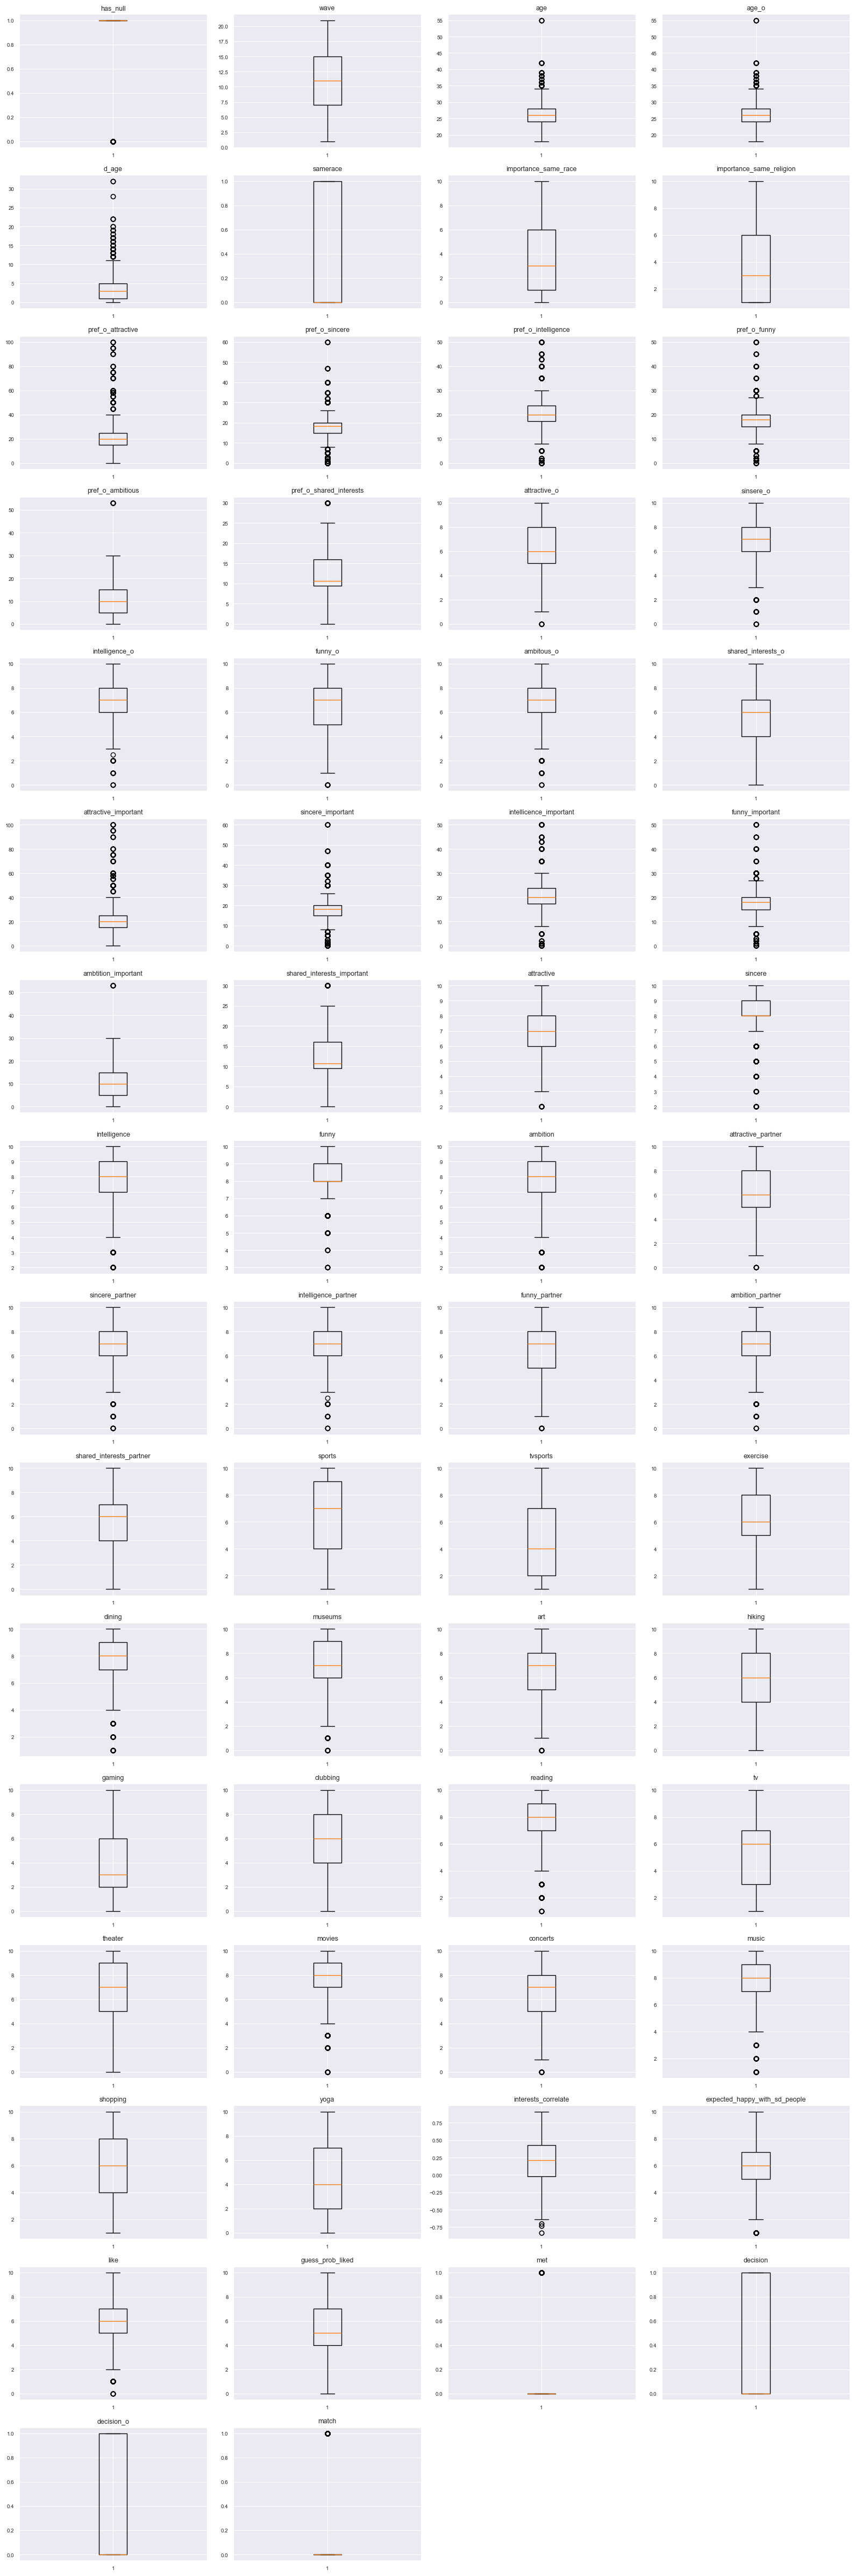

In [63]:
# построим бокспоты (ящики с усами) для всех числовых переменных для выявления экстримальных значений
n = len(num_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].boxplot(df_clean[col].dropna(), vert=True)
    axes[i].set_title(col, fontsize=9)
    axes[i].tick_params(labelsize=7)

# убрать пустые оси
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Заметим, что в опросе используются разные шкалы, поэтому числовые колонки напрямую несопоставимы по диапазону:

**Шкала 1–10** — самооценки, оценки партнёра, интересы и важность:
- самооценки: `attractive`, `sincere`, `intelligence`, `funny`, `ambition`;
- оценки, которые партнёр поставил респонденту: `attractive_o`, `sinsere_o`, `intelligence_o`, `funny_o`, `ambitous_o`, `shared_interests_o`;
- оценки, которые респондент поставил партнёру: `attractive_partner`, `sincere_partner`, `intelligence_partner`, `funny_partner`, `ambition_partner`, `shared_interests_partner`;
- `like`, `guess_prob_liked` (оценка шансов на «да» по шкале 1–10, а не вероятность), `expected_happy_with_sd_people`;
- важность совпадения: `importance_same_race`, `importance_same_religion`;
- интересы/активности: `sports`, `tvsports`, `exercise`, `dining`, `museums`, `art`, `hiking`, `gaming`, `clubbing`, `reading`, `tv`, `theater`, `movies`, `concerts`, `music`, `shopping`, `yoga`.

**Шкала 0–100** — важность критериев при выборе партнёра (в сумме по блоку дают 100):
- предпочтения к партнёру: `pref_o_attractive`, `pref_o_sincere`, `pref_o_intelligence`, `pref_o_funny`, `pref_o_ambitious`, `pref_o_shared_interests`;
- важность при выборе: `attractive_important`, `sincere_important`, `intellicence_important`, `funny_important`, `ambtition_important`, `shared_interests_important`.

По описанию эксперимента в волнах 6–9 важность каждого критерия оценивали по шкале 1–10, а не распределяли 100 баллов. В этой версии данных веса этих волн тоже дают в сумме 100, то есть пересчитаны, и напрямую сравнивать их с другими волнами нельзя.

Отдельно стоят: возраст (`age`, `age_o`), разность возрастов (`d_age`), бинарные признаки (`has_null`, `samerace`, `met`, `decision`, `decision_o`, `match`), волна (`wave`, 1–21) и корреляция интересов (`interests_correlate`, −1…1).

In [64]:
# создадим ф-ю для расчёта жёстких выбросов 
def heavy_outliers_pct(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 3 * IQR
    upper_bound = Q3 + 3 * IQR
    mask = (df[column] < lower_bound) | (df[column] > upper_bound)
    return mask.sum() / df.shape[0] * 100

# считаем по всем числовым колонкам
outliers = pd.Series(
    {col: heavy_outliers_pct(df_clean, col) for col in num_cols}
).sort_values(ascending=False)

print(outliers[outliers > 0].round(3))

match                     16.472
has_null                  12.509
met                        4.190
attractive_important       2.435
pref_o_attractive          2.423
sincere                    1.838
sincere_important          1.182
pref_o_sincere             1.170
pref_o_intelligence        0.943
intellicence_important     0.943
funny_important            0.836
pref_o_funny               0.836
age_o                      0.310
age                        0.310
d_age                      0.310
funny                      0.227
movies                     0.215
pref_o_ambitious           0.119
ambtition_important        0.119
dtype: float64

In [65]:
cols_outliers = outliers[outliers > 1].index.tolist()  # колонки, где жёстких выбросов больше 1%
print(cols_outliers)

['match', 'has_null', 'met', 'attractive_important', 'pref_o_attractive', 'sincere', 'sincere_important', 'pref_o_sincere']

,count,mean,std,min,25%,50%,75%,max
match,8378.0,0.165,0.371,0.0,0.0,0.0,0.0,1.0


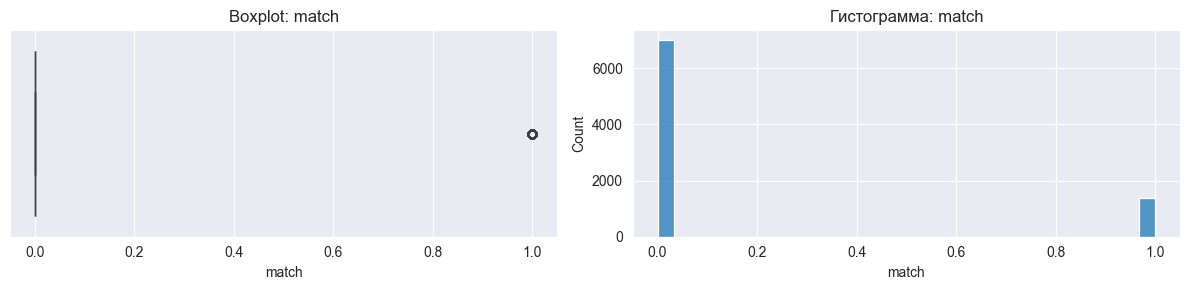

,count,mean,std,min,25%,50%,75%,max
has_null,8378.0,0.875,0.331,0.0,1.0,1.0,1.0,1.0


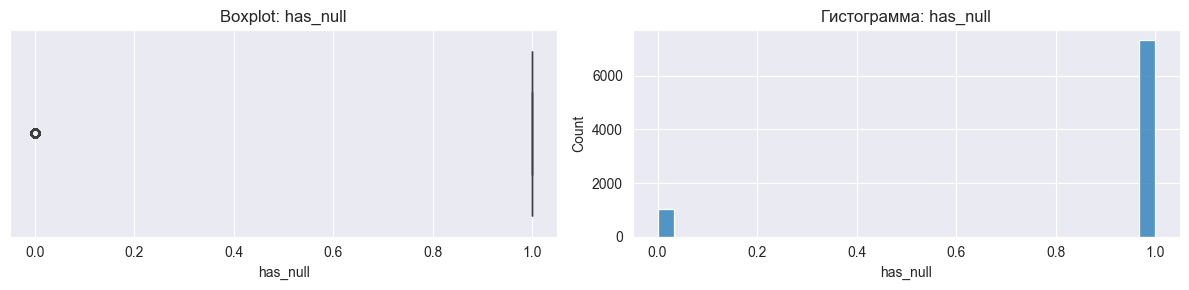

,count,mean,std,min,25%,50%,75%,max
met,7995.0,0.044,0.205,0.0,0.0,0.0,0.0,1.0


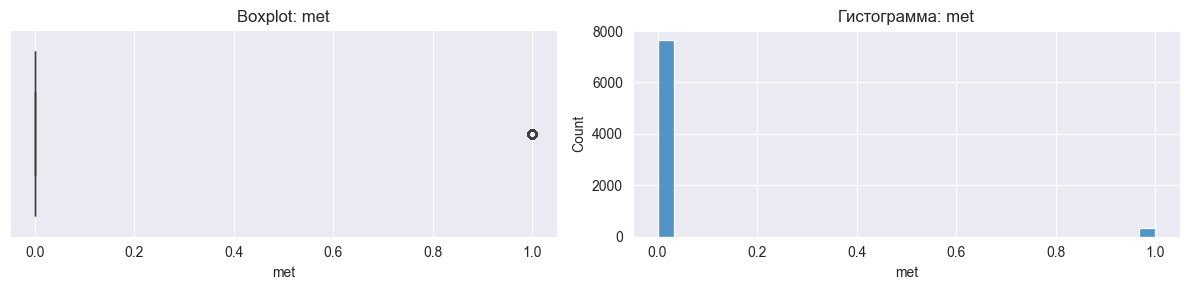

,count,mean,std,min,25%,50%,75%,max
attractive_important,8299.0,22.515,12.588,0.0,15.0,20.0,25.0,100.0


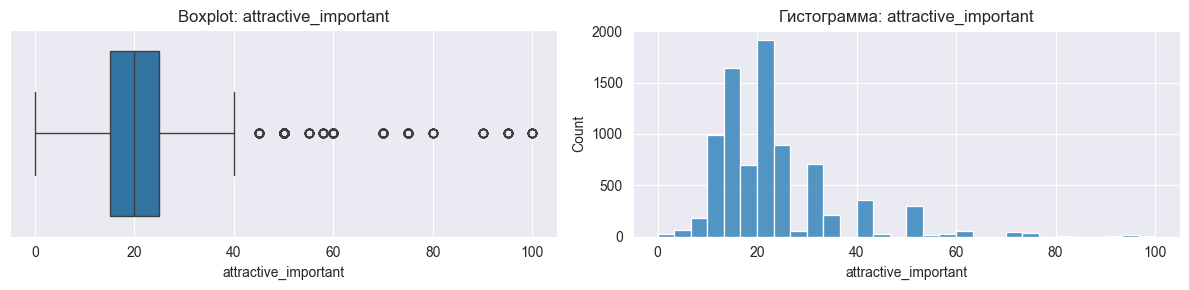

,count,mean,std,min,25%,50%,75%,max
pref_o_attractive,8289.0,22.495,12.57,0.0,15.0,20.0,25.0,100.0


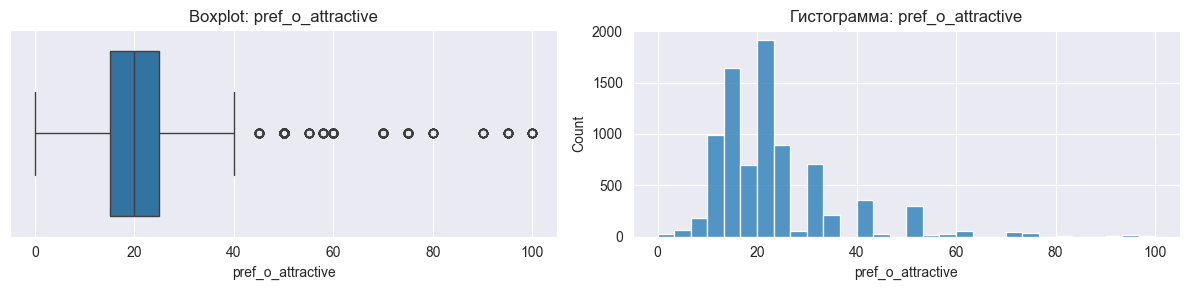

,count,mean,std,min,25%,50%,75%,max
sincere,8273.0,8.295,1.407,2.0,8.0,8.0,9.0,10.0


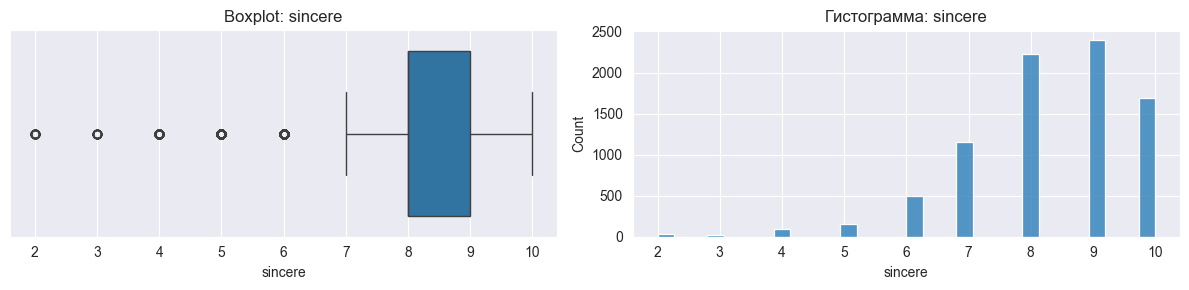

,count,mean,std,min,25%,50%,75%,max
sincere_important,8299.0,17.396,7.047,0.0,15.0,18.18,20.0,60.0


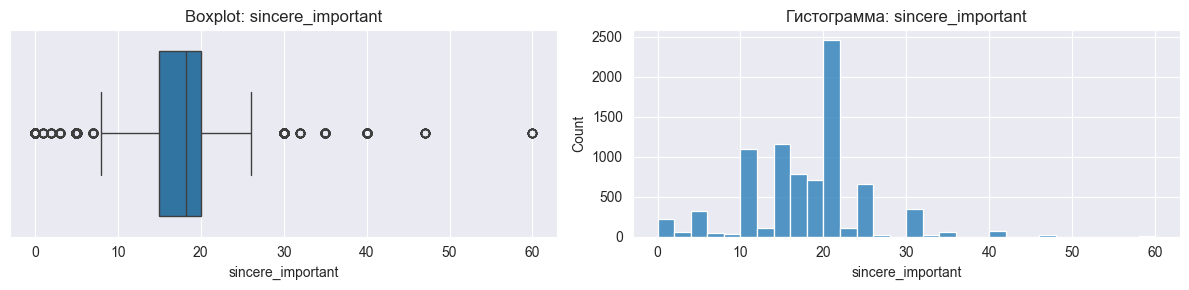

,count,mean,std,min,25%,50%,75%,max
pref_o_sincere,8289.0,17.397,7.044,0.0,15.0,18.37,20.0,60.0


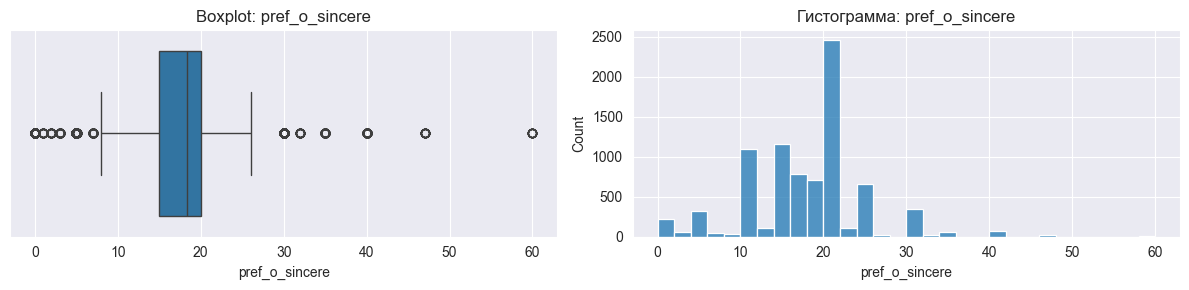

In [66]:
def heavy_outliers_desc(df, column):
    display(df[column].describe().to_frame().T.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 3))

    sns.boxplot(x=df[column], ax=axes[0])
    axes[0].set_title(f"Boxplot: {column}")

    sns.histplot(df[column].dropna(), bins=30, kde=False, ax=axes[1])
    axes[1].set_title(f"Гистограмма: {column}")

    plt.tight_layout()
    plt.show()


for col in cols_outliers:
    heavy_outliers_desc(df_clean, col)

После ограничения значений сверху (см. выше) значений выше шкал не осталось. Экстремальные по IQR значения — реальные, но относительно редкие ответы респондентов (например, большие веса отдельных предпочтений), поэтому их оставляем без изменений. Нули на шкалах 1–10 и коды `met` описаны выше.

In [67]:
# для категориальных признаков сделаем сводную таблицу
summary = pd.DataFrame({
    "n_unique": [df_clean[c].nunique() for c in cat_cols],
    "n_nan": [df_clean[c].isna().sum() for c in cat_cols],
    "examples": [df_clean[c].dropna().unique()[:5].tolist() for c in cat_cols],
}, index=cat_cols)

display(summary.sort_values("n_unique", ascending=False))

,n_unique,n_nan,examples
field,219,63,"[law, economics, 'masters in public administra..."
race,5,63,"['asian/pacific islander/asian-american', euro..."
race_o,5,73,"[european/caucasian-american, 'asian/pacific i..."
d_d_age,4,198,"[[4-6], [0-1], [2-3], [7-37]]"
d_funny,3,0,"[[6-8], [9-10], [0-5]]"
d_gaming,3,0,"[[0-5], [6-8], [9-10]]"
d_funny_partner,3,0,"[[6-8], [0-5], [9-10]]"
d_ambition_partner,3,0,"[[6-8], [0-5], [9-10]]"
d_shared_interests_partner,3,0,"[[0-5], [6-8], [9-10]]"
d_sports,3,0,"[[9-10], [0-5], [6-8]]"


In [68]:
df_clean['field'].unique() # рассмотрим самую многочисленную группу

array(['law', 'economics', "'masters in public administration'",
       "'masters of social work&education'", 'finance', 'business',
       "'political science'", 'money', "'operations research'",
       "'tc [health ed]'", 'psychology', "'social work'",
       "'speech language pathology'", "'speech languahe pathology'",
       "'educational psychology'", "'applied maths/econs'", 'mathematics',
       'statistics', "'organizational psychology'",
       "'mechanical engineering'", 'finanace', 'finance&economics',
       "'undergrad - gs'", "'mathematical finance'", 'medicine', 'mba',
       nan, "'german literature'", "'business & international affairs'",
       "'mfa creative writing'", 'engineering',
       "'electrical engineering'", 'classics',
       "'operations research [seas]'", 'chemistry', 'journalism',
       "'elementary/childhood education [ma]'", 'microbiology',
       "'masters of social work'", 'communications', 'marketing',
       "'international educational developmen

In [69]:
df_clean[df_clean['field'] == "'masters in public administration'"].head(5)

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,d_expected_happy_with_sd_people,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
70,1,1,female,25.0,27.0,2.0,[2-3],european/caucasian-american,european/caucasian-american,1,1.0,1.0,[0-1],[0-1],'masters in public administration',35.0,20.0,20.0,20.0,0.0,5.0,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],8.0,7.0,6.0,6.0,6.0,5.0,[6-8],[6-8],[6-8],[6-8],[6-8],[0-5],9.09,18.18,27.27,18.18,18.18,9.09,[0-15],[16-20],[21-100],[16-20],[16-20],[0-15],7.0,4.0,8.0,8.0,8.0,[6-8],[0-5],[6-8],[6-8],[6-8],5.0,8.0,7.0,4.0,7.0,5.0,[0-5],[6-8],[6-8],[0-5],[6-8],[0-5],2.0,2.0,1.0,10.0,9.0,9.0,3.0,2.0,10.0,8.0,10.0,9.0,9.0,6.0,6.0,8.0,6.0,[0-5],[0-5],[0-5],[9-10],[9-10],[9-10],[0-5],[0-5],[9-10],[6-8],[9-10],[9-10],[9-10],[6-8],[6-8],[6-8],[6-8],-0.03,[-1-0],6.0,[5-6],4.0,5.0,[0-5],[5-6],0.0,1,0,0
71,1,1,female,25.0,22.0,3.0,[2-3],european/caucasian-american,european/caucasian-american,1,1.0,1.0,[0-1],[0-1],'masters in public administration',60.0,0.0,0.0,40.0,0.0,0.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],8.0,8.0,10.0,7.0,6.0,5.0,[6-8],[6-8],[9-10],[6-8],[6-8],[0-5],9.09,18.18,27.27,18.18,18.18,9.09,[0-15],[16-20],[21-100],[16-20],[16-20],[0-15],7.0,4.0,8.0,8.0,8.0,[6-8],[0-5],[6-8],[6-8],[6-8],8.0,7.0,7.0,9.0,6.0,7.0,[6-8],[6-8],[6-8],[9-10],[6-8],[6-8],2.0,2.0,1.0,10.0,9.0,9.0,3.0,2.0,10.0,8.0,10.0,9.0,9.0,6.0,6.0,8.0,6.0,[0-5],[0-5],[0-5],[9-10],[9-10],[9-10],[0-5],[0-5],[9-10],[6-8],[9-10],[9-10],[9-10],[6-8],[6-8],[6-8],[6-8],-0.11,[-1-0],6.0,[5-6],8.0,7.0,[6-8],[7-10],0.0,1,1,1
72,1,1,female,25.0,22.0,3.0,[2-3],european/caucasian-american,'asian/pacific islander/asian-american',0,1.0,1.0,[0-1],[0-1],'masters in public administration',19.0,18.0,19.0,18.0,14.0,12.0,[16-20],[16-20],[16-20],[16-20],[0-15],[0-15],10.0,10.0,10.0,10.0,10.0,10.0,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],9.09,18.18,27.27,18.18,18.18,9.09,[0-15],[16-20],[21-100],[16-20],[16-20],[0-15],7.0,4.0,8.0,8.0,8.0,[6-8],[0-5],[6-8],[6-8],[6-8],5.0,8.0,8.0,6.0,7.0,7.0,[0-5],[6-8],[6-8],[6-8],[6-8],[6-8],2.0,2.0,1.0,10.0,9.0,9.0,3.0,2.0,10.0,8.0,10.0,9.0,9.0,6.0,6.0,8.0,6.0,[0-5],[0-5],[0-5],[9-10],[9-10],[9-10],[0-5],[0-5],[9-10],[6-8],[9-10],[9-10],[9-10],[6-8],[6-8],[6-8],[6-8],0.42,[0.33-1],6.0,[5-6],5.0,5.0,[0-5],[5-6],0.0,1,1,1
73,1,1,female,25.0,23.0,2.0,[2-3],european/caucasian-american,european/caucasian-american,1,1.0,1.0,[0-1],[0-1],'masters in public administration',30.0,5.0,15.0,40.0,5.0,5.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],8.0,8.0,8.0,8.

В колонке специальности (field) выявлены двойные ковычки в некоторых местах - уберём их.

In [70]:
df_clean["field"] = df_clean["field"].str.strip("'")

In [71]:
df_clean['field'].unique()

array(['law', 'economics', 'masters in public administration',
       'masters of social work&education', 'finance', 'business',
       'political science', 'money', 'operations research',
       'tc [health ed]', 'psychology', 'social work',
       'speech language pathology', 'speech languahe pathology',
       'educational psychology', 'applied maths/econs', 'mathematics',
       'statistics', 'organizational psychology',
       'mechanical engineering', 'finanace', 'finance&economics',
       'undergrad - gs', 'mathematical finance', 'medicine', 'mba', nan,
       'german literature', 'business & international affairs',
       'mfa creative writing', 'engineering', 'electrical engineering',
       'classics', 'operations research [seas]', 'chemistry',
       'journalism', 'elementary/childhood education [ma]',
       'microbiology', 'masters of social work', 'communications',
       'marketing', 'international educational development',
       'education administration', 'business [

In [72]:
# Создадим колонку с укрупнёнными направлениями


def map_field_to_group(field):
    if pd.isna(field):
        return "unknown"
    f = field.lower()

    # 1. Бизнес / финансы / экономика (проверяем раньше "international")
    if re.search(r"business|mba|finance|finanace|econ|money|marketing|management", f):
        return "business_finance_economics"
    # 2. Медицина / здоровье (раньше общих "science")
    if re.search(r"medicine|health|biomedical|microbiology|pathology|nursing|epidemiolog|physiolog|nutrition", f):
        return "medicine_health"
    # 3. Естественные науки (новое!)
    if re.search(r"biology|chemistry|physics|ecology|genetic|neuroscience|biochem|climate|environment|marine|geophys|conservation|(?<!political )(?<!computer )science", f):  # political / computer science — в п. 6 и п. 4
        return "natural_sciences"
    # 4. IT / инженерия / математика / статистика
    if re.search(r"computer|engineering|math|statistic|operations research|financial math|applied maths", f):
        return "stem_engineering_math"
    # 5. Образование (до humanities, чтобы "art education" → education)
    if re.search(r"education|teaching|childhood|tesol|curriculum", f):
        return "education"
    # 6. Социальные науки / психология / право / политика
    if re.search(r"psychology|social work|sociology|political science|law|public administration|international|anthropology|human rights|urban planning", f):
        return "social_sciences_law"
    # 7. Гуманитарные / искусства / языки
    if re.search(r"literature|german|polish|english|classics|philosophy|religion|history|art|film|journalism|communications|creative writing|mfa|theater|theatre|writing|japanese|french|american studies", f):
        return "humanities_arts"
    return "other"

df_clean["field_group"] = df_clean["field"].apply(map_field_to_group)

# проверка
print(df_clean["field_group"].value_counts(dropna=False))

field_group
social_sciences_law           2334
business_finance_economics    1933
humanities_arts                852
stem_engineering_math          842
natural_sciences               784
education                      613
medicine_health                562
other                          395
unknown                         63
Name: count, dtype: int64

In [73]:
cat_cols.append('field_group')
cat_cols

['gender',
 'd_d_age',
 'race',
 'race_o',
 'd_importance_same_race',
 'd_importance_same_religion',
 'field',
 'd_pref_o_attractive',
 'd_pref_o_sincere',
 'd_pref_o_intelligence',
 'd_pref_o_funny',
 'd_pref_o_ambitious',
 'd_pref_o_shared_interests',
 'd_attractive_o',
 'd_sinsere_o',
 'd_intelligence_o',
 'd_funny_o',
 'd_ambitous_o',
 'd_shared_interests_o',
 'd_attractive_important',
 'd_sincere_important',
 'd_intellicence_important',
 'd_funny_important',
 'd_ambtition_important',
 'd_shared_interests_important',
 'd_attractive',
 'd_sincere',
 'd_intelligence',
 'd_funny',
 'd_ambition',
 'd_attractive_partner',
 'd_sincere_partner',
 'd_intelligence_partner',
 'd_funny_partner',
 'd_ambition_partner',
 'd_shared_interests_partner',
 'd_sports',
 'd_tvsports',
 'd_exercise',
 'd_dining',
 'd_museums',
 'd_art',
 'd_hiking',
 'd_gaming',
 'd_clubbing',
 'd_reading',
 'd_tv',
 'd_theater',
 'd_movies',
 'd_concerts',
 'd_music',
 'd_shopping',
 'd_yoga',
 'd_interests_correlate'

In [74]:
df_clean['field_group'].describe(include='all')

count                    8378
unique                      9
top       social_sciences_law
freq                     2334
Name: field_group, dtype: object

In [75]:
df_clean['race'].unique()

array(["'asian/pacific islander/asian-american'",
       'european/caucasian-american', 'other',
       "'latino/hispanic american'", "'black/african american'", nan],
      dtype=object)

In [76]:
df_clean['race_o'].unique()

array(['european/caucasian-american',
       "'asian/pacific islander/asian-american'",
       "'latino/hispanic american'", 'other', "'black/african american'",
       nan], dtype=object)

In [77]:
# Аналогично уберём дыойные ковычки в колонках с расами
df_clean["race"] = df_clean["race"].str.strip("'")
df_clean["race_o"] = df_clean["race_o"].str.strip("'")

In [78]:
df_clean['race'].unique()

array(['asian/pacific islander/asian-american',
       'european/caucasian-american', 'other', 'latino/hispanic american',
       'black/african american', nan], dtype=object)

In [79]:
df_clean['race_o'].unique()

array(['european/caucasian-american',
       'asian/pacific islander/asian-american',
       'latino/hispanic american', 'other', 'black/african american', nan],
      dtype=object)

Категориальные признаки представлены в основном бинами d_* с упорядоченными диапазонами (обычно 3 группы: 0–5 / 6–8 / 9–10 либо 0–15 / 16–20 / 21–100), а также демографическими (gender, race, race_o) и field. Лишние одинарные кавычки в значениях field, race, race_o удалены; в остальных колонках значения соответствуют ожидаемым категориям и диапазонам; при этом в `d_*` пропуск исходного признака записан нижним бином, а `d_d_age` у строк с пропущенным возрастом заменён пропуском (см. выше). Дополнительно на основе field создана колонка field_group с укрупнёнными группами специальностей для дальнейшего анализа.

**Вывод:** В числовых колонках найдены и обработаны аномалии: значения выше шкалы 1–10 (`reading`, `gaming`, `funny_o`, `attractive_o`) ограничены 10, нестандартные коды `met` (3–8) заменены пропусками, `d_age` и `d_d_age` при пропущенном возрасте заменены пропусками, дробные значения сохранены. Нули на шкалах 1–10 оставлены как есть (возможно, это код отсутствия ответа). Остальные экстремальные значения — реальные редкие ответы. В категориальных переменных значения соответствуют ожидаемым категориям и диапазонам; лишние одинарные кавычки в `field`, `race`, `race_o` удалены, а на основе `field` создана колонка `field_group` с укрупнёнными группами специальностей.

## Анализ данных

### Распределение параметров

In [80]:
# построим распределения параметров
# Числовые: гистограмма + KDE
def plot_numeric_distributions(df, cols, ncols=4, bins=30):
    n = len(cols)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(cols):
        sns.histplot(df[col].dropna(), bins=bins, kde=True, ax=axes[i])
        axes[i].set_title(col, fontsize=9)
        axes[i].set_xlabel("")
        axes[i].tick_params(labelsize=7)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


# Категориальные: барчарт
def plot_categorical_distributions(df, cols, ncols=3, top_n=10):
    n = len(cols)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(cols):
        vc = df[col].value_counts(dropna=False).head(top_n)
        sns.barplot(x=vc.values, y=vc.index.astype(str), ax=axes[i], orient="h")
        axes[i].set_title(col, fontsize=9)
        axes[i].set_xlabel("count")
        axes[i].tick_params(labelsize=7)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


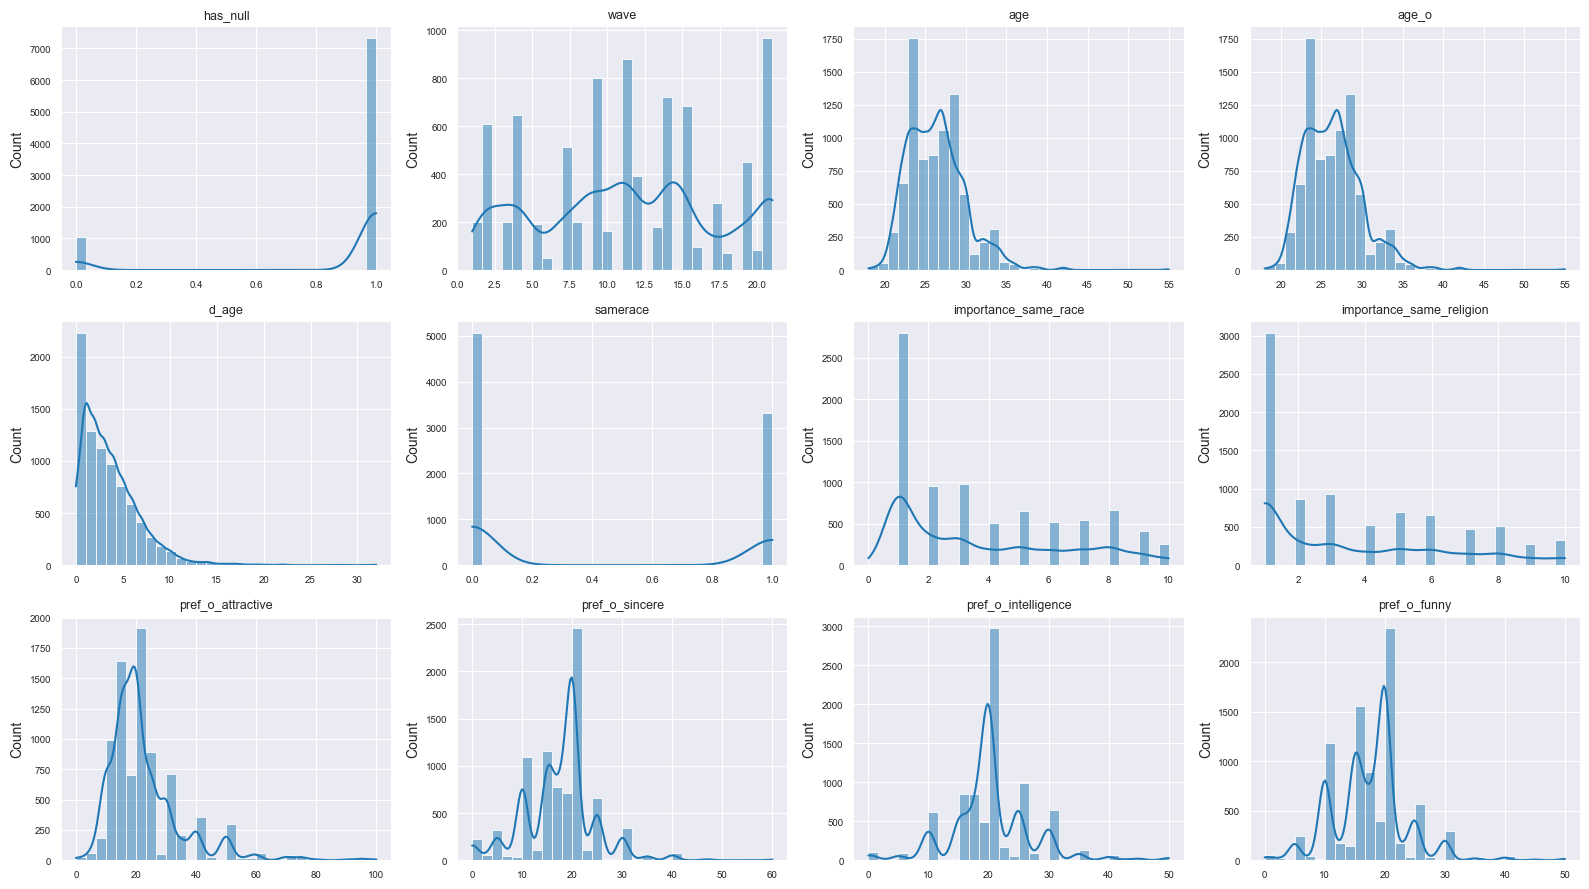

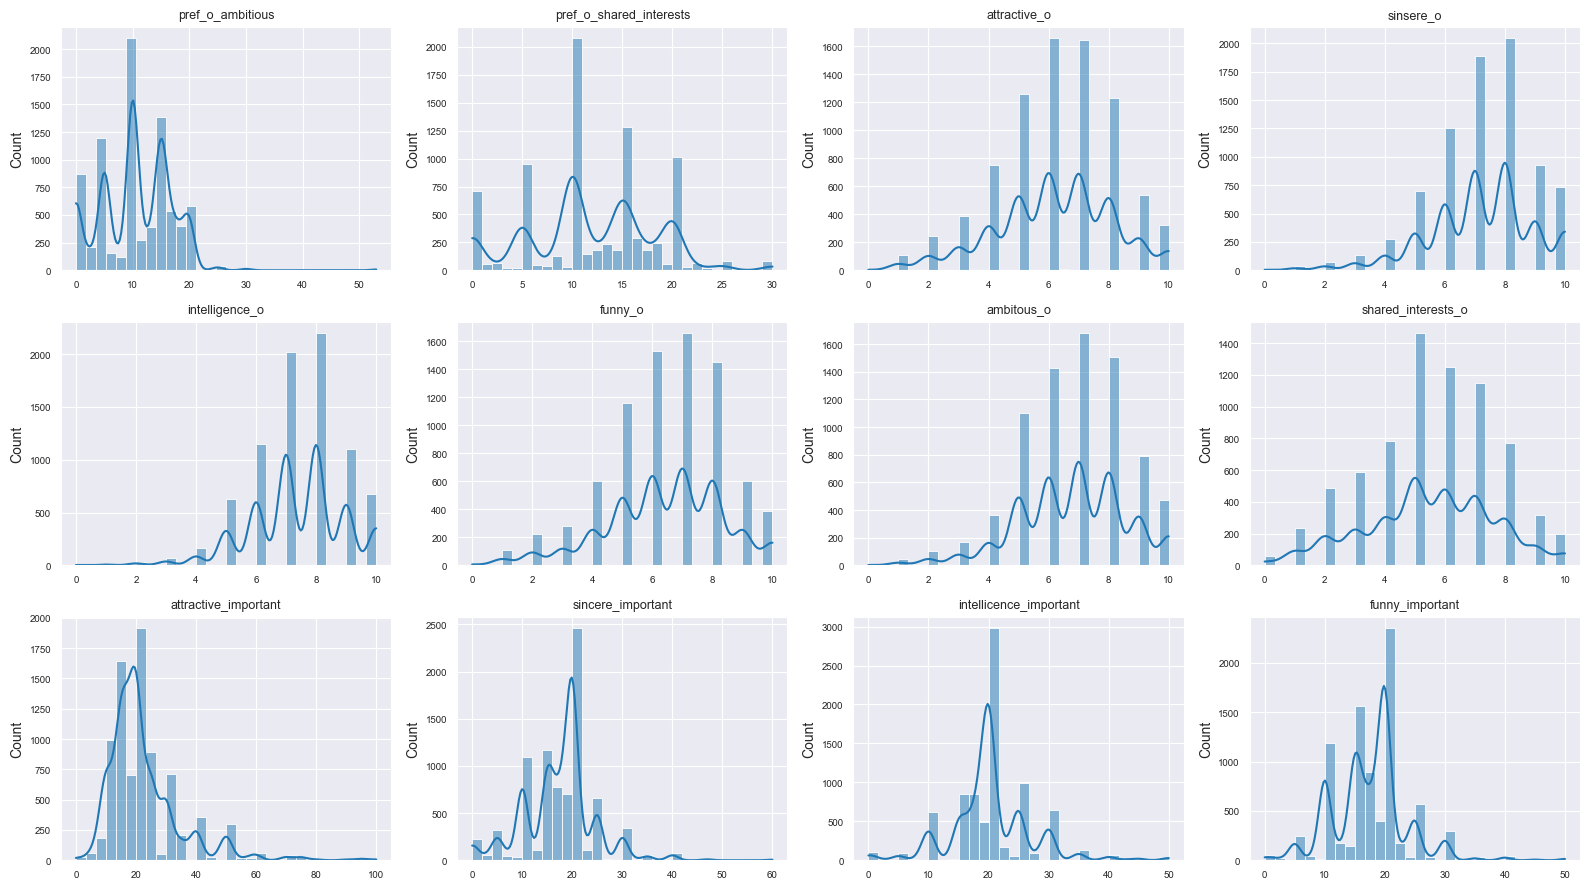

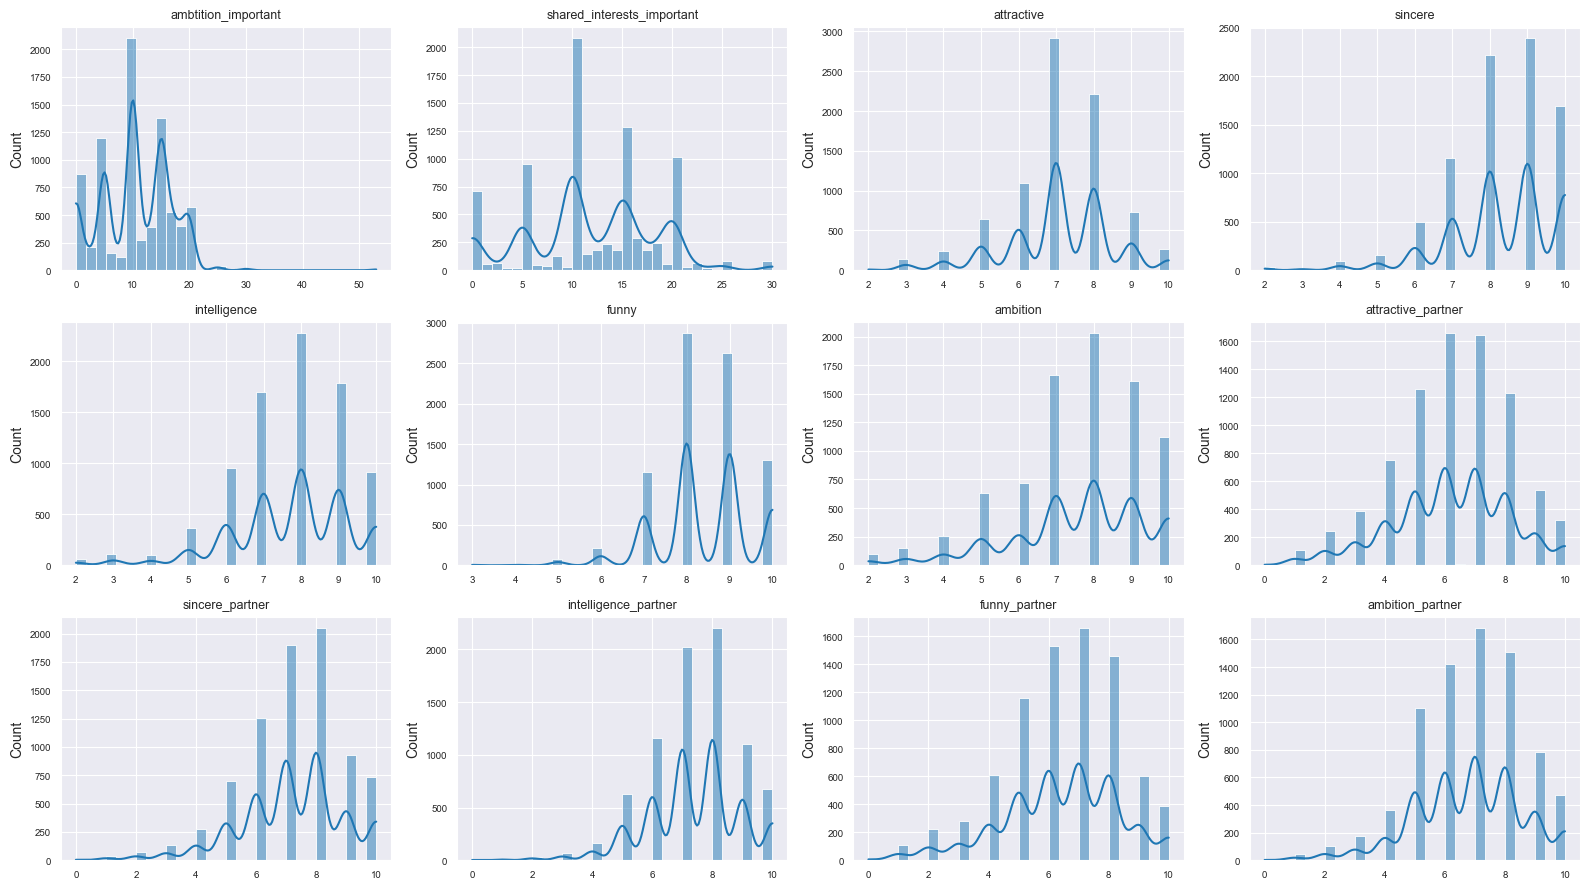

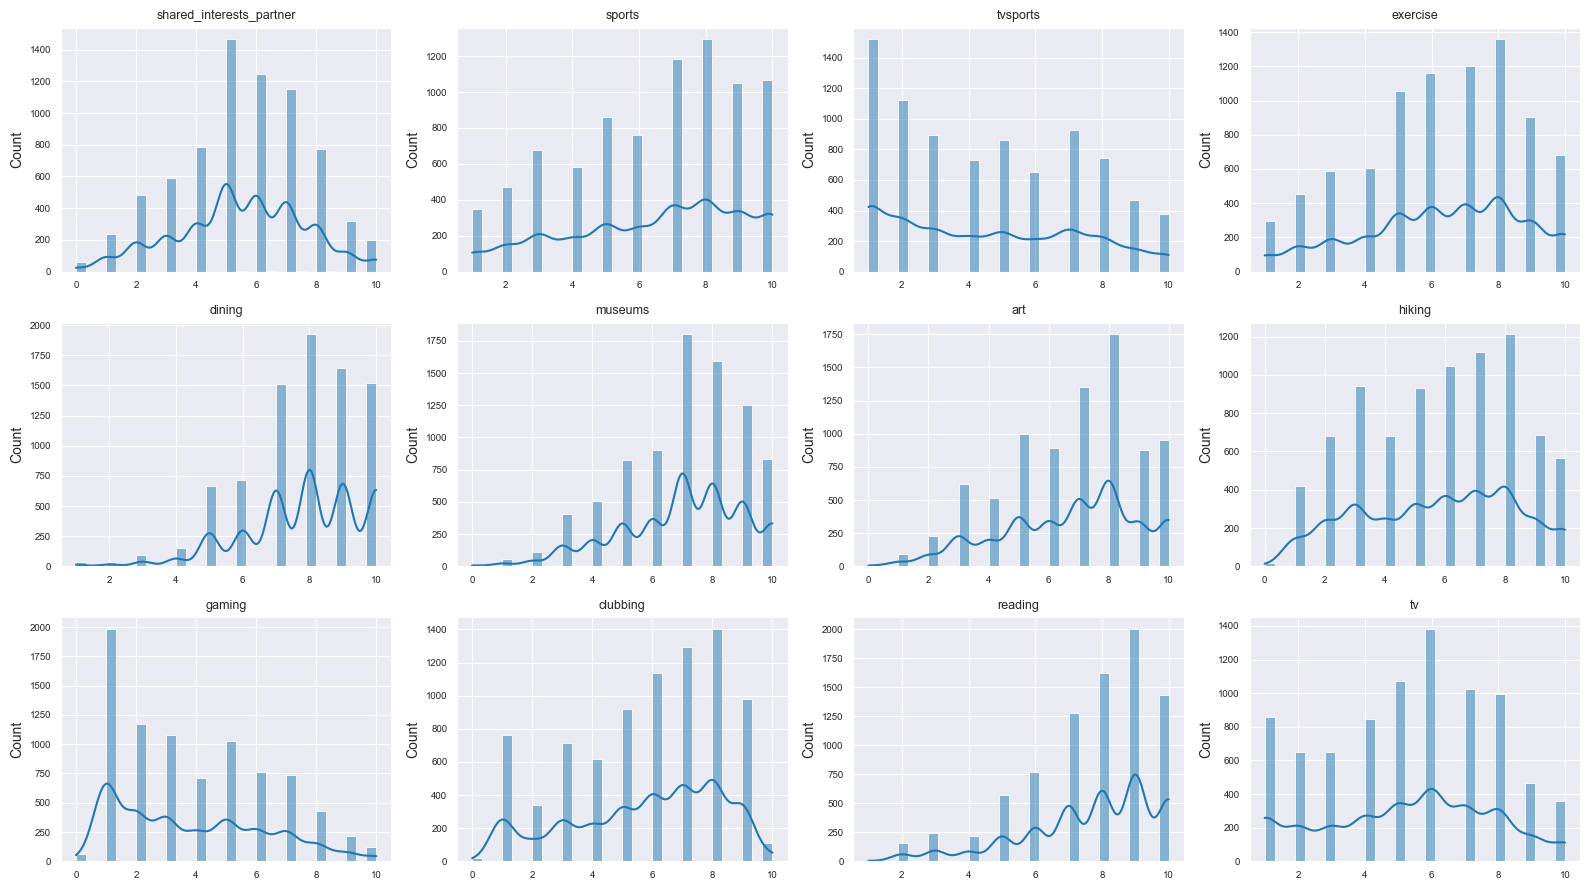

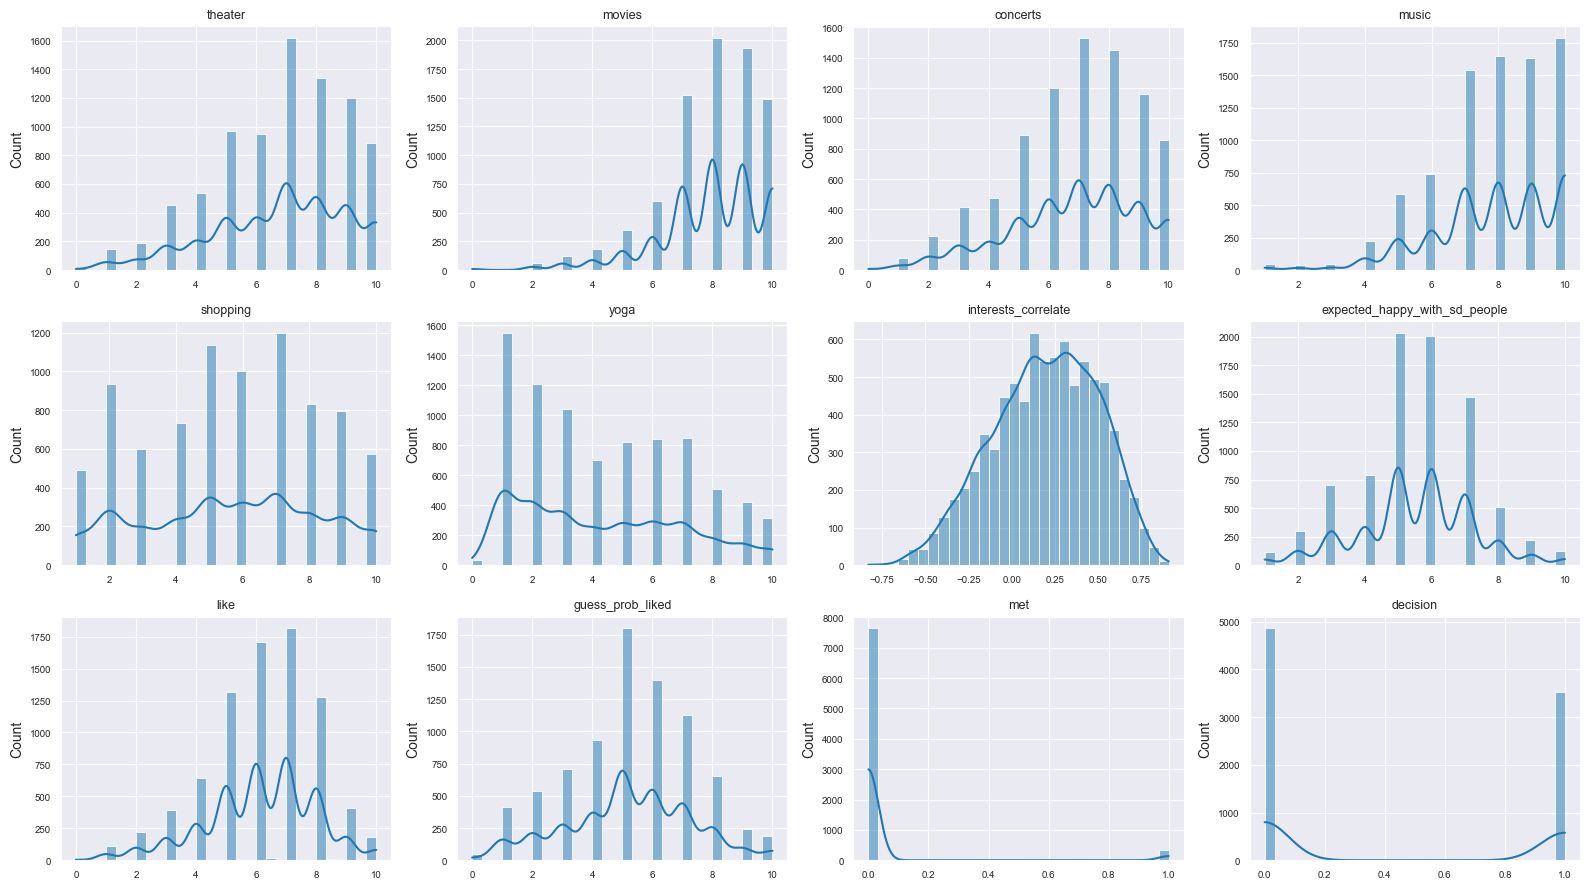

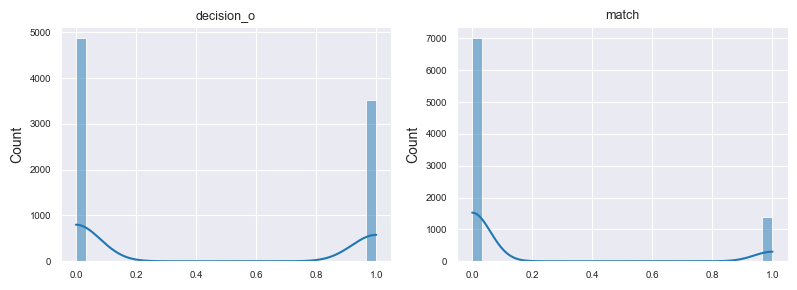

In [81]:
# числовые — порциями по 12, чтобы графики не были мелкими
for k in range(0, len(num_cols), 12):
    plot_numeric_distributions(df_clean, num_cols[k:k + 12])

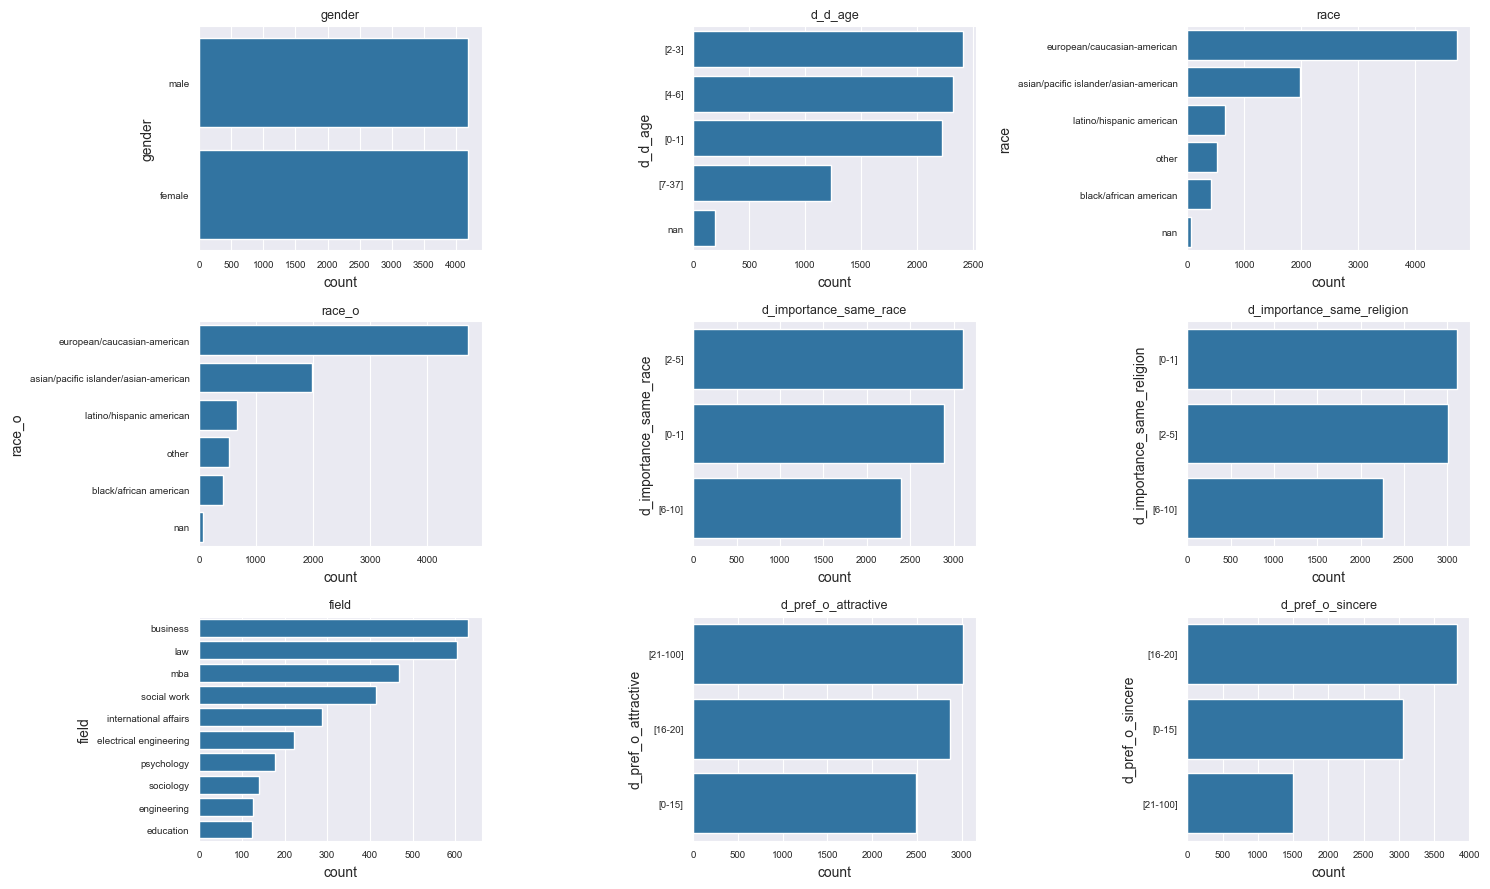

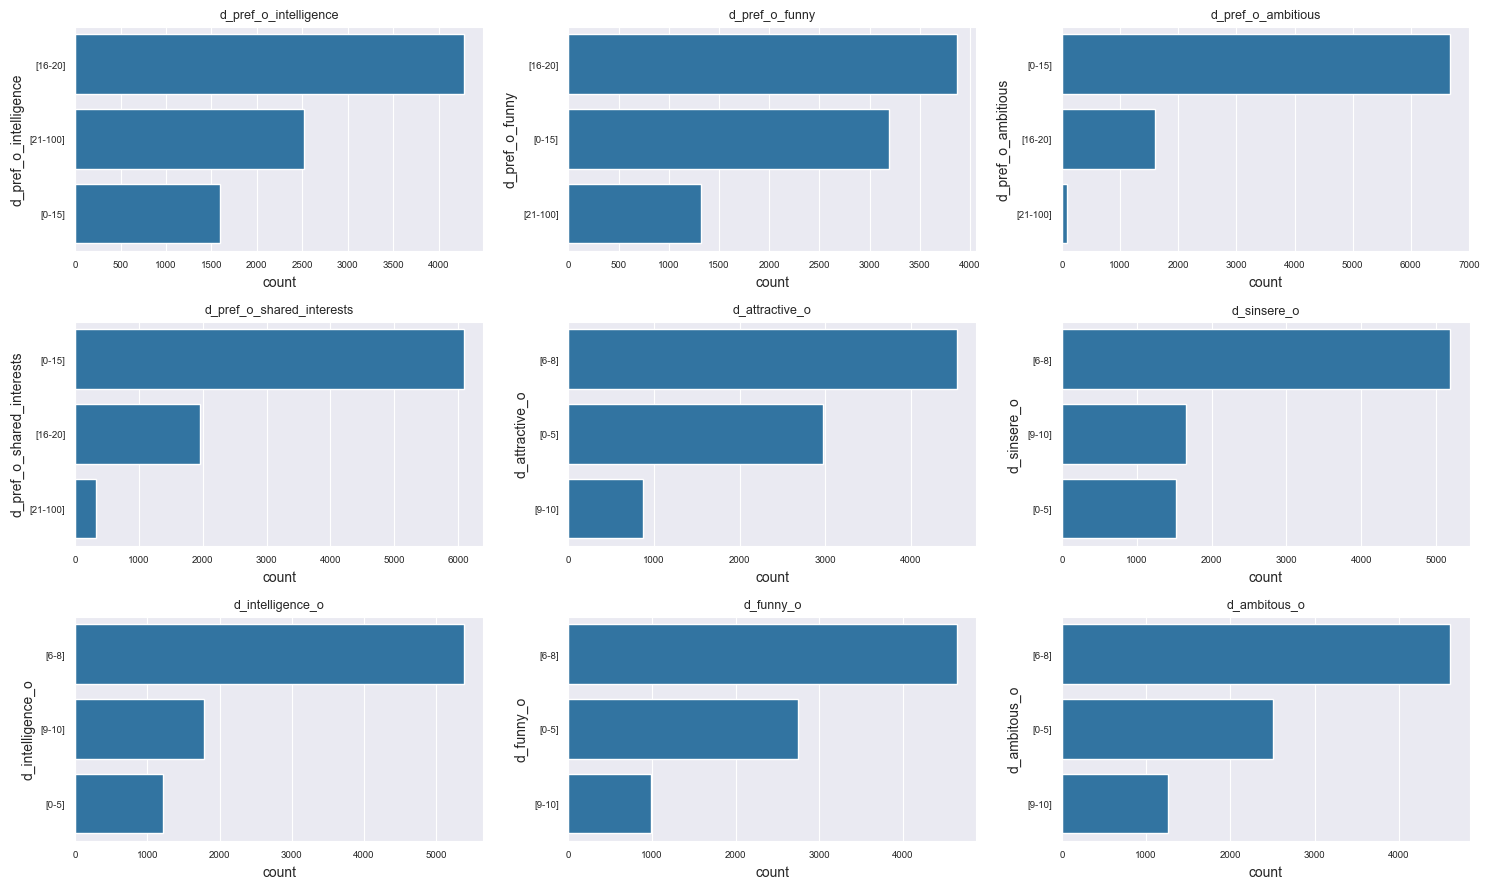

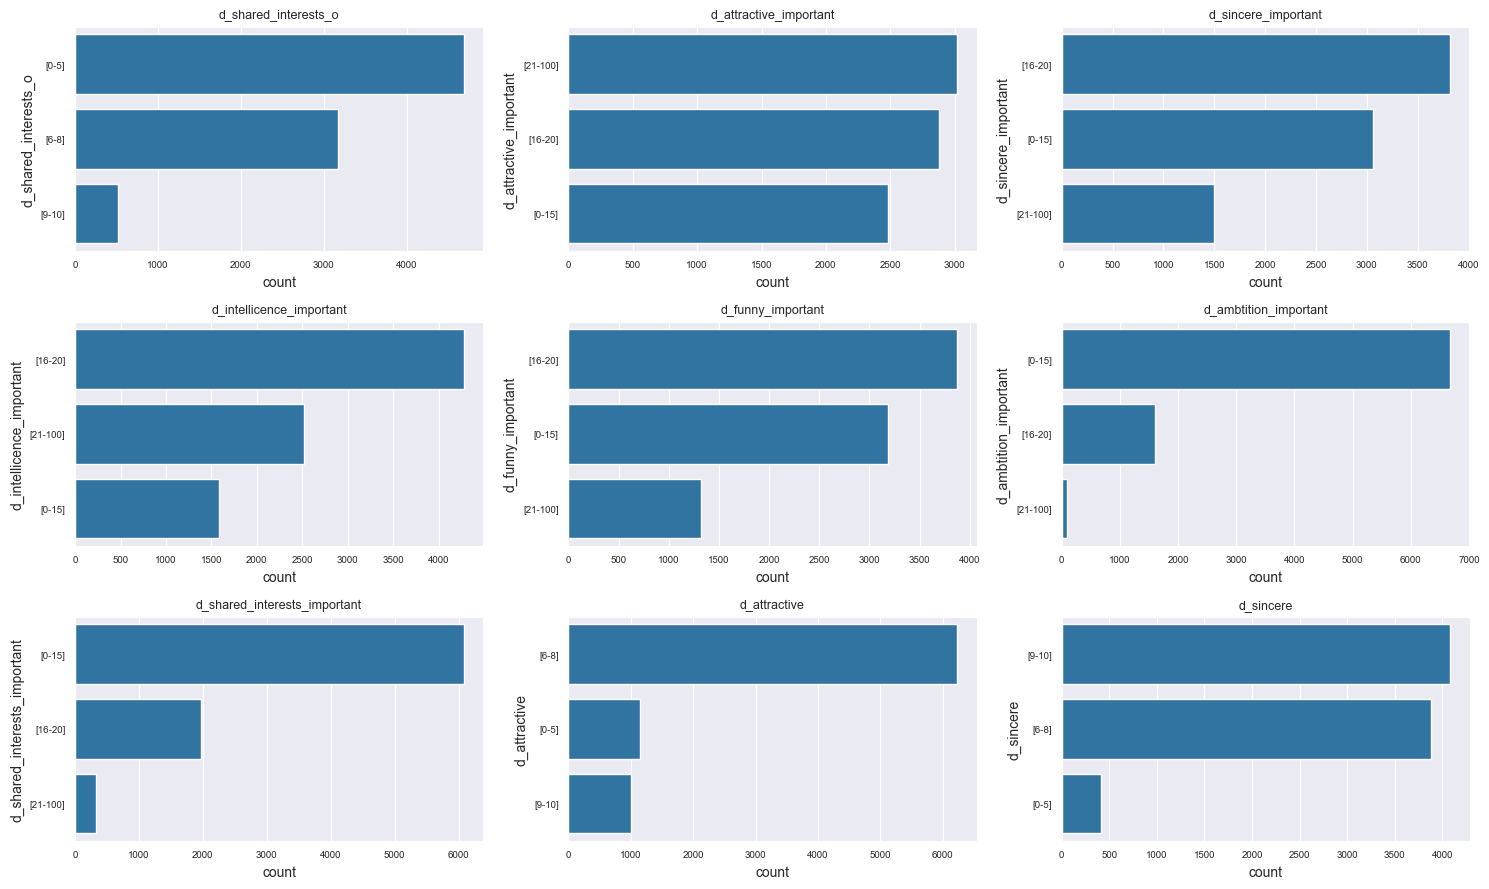

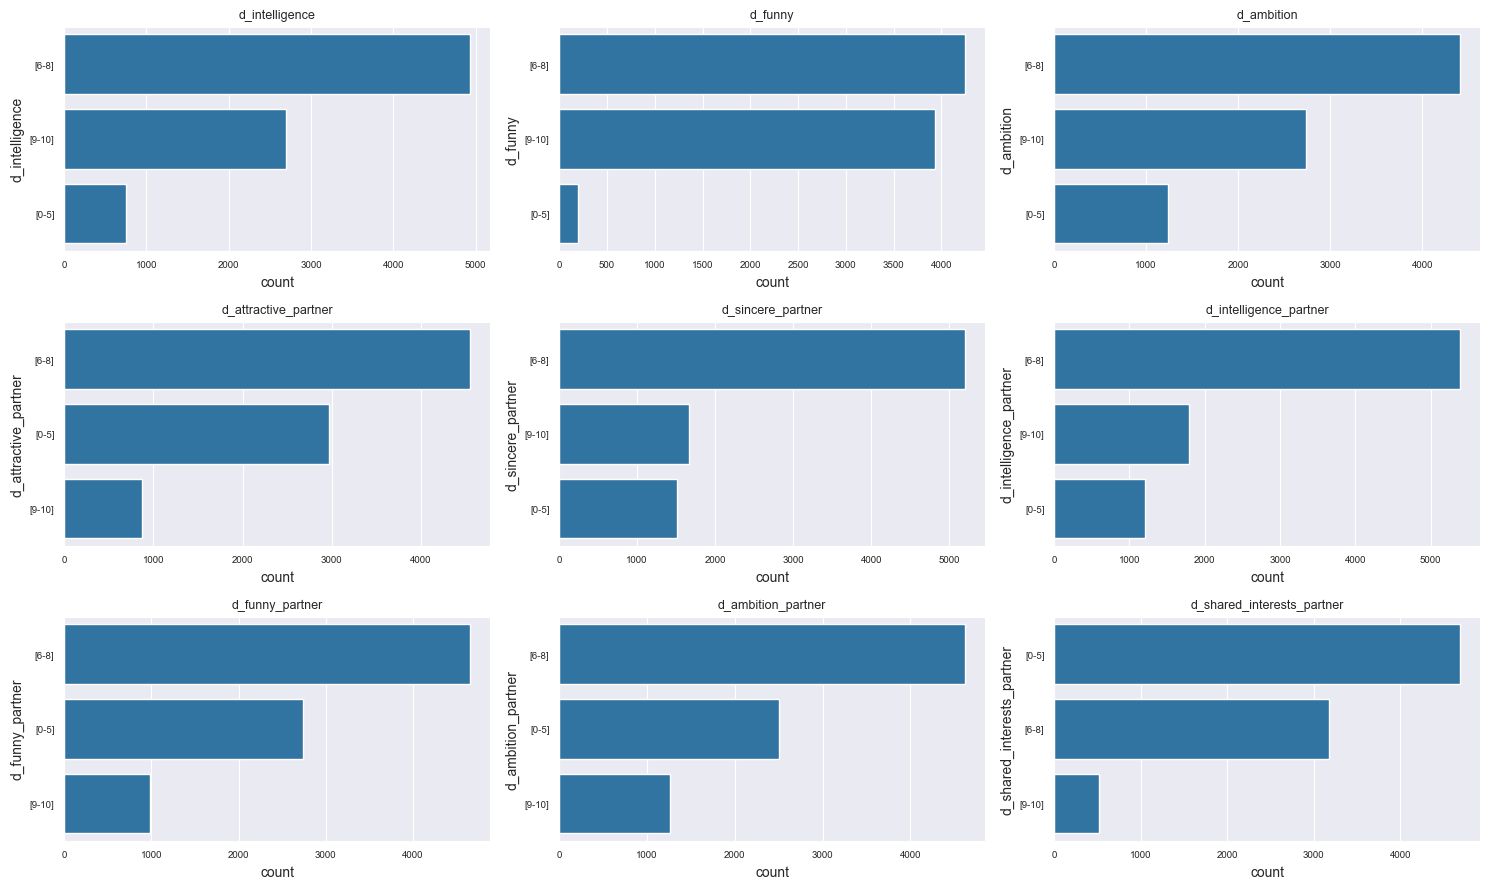

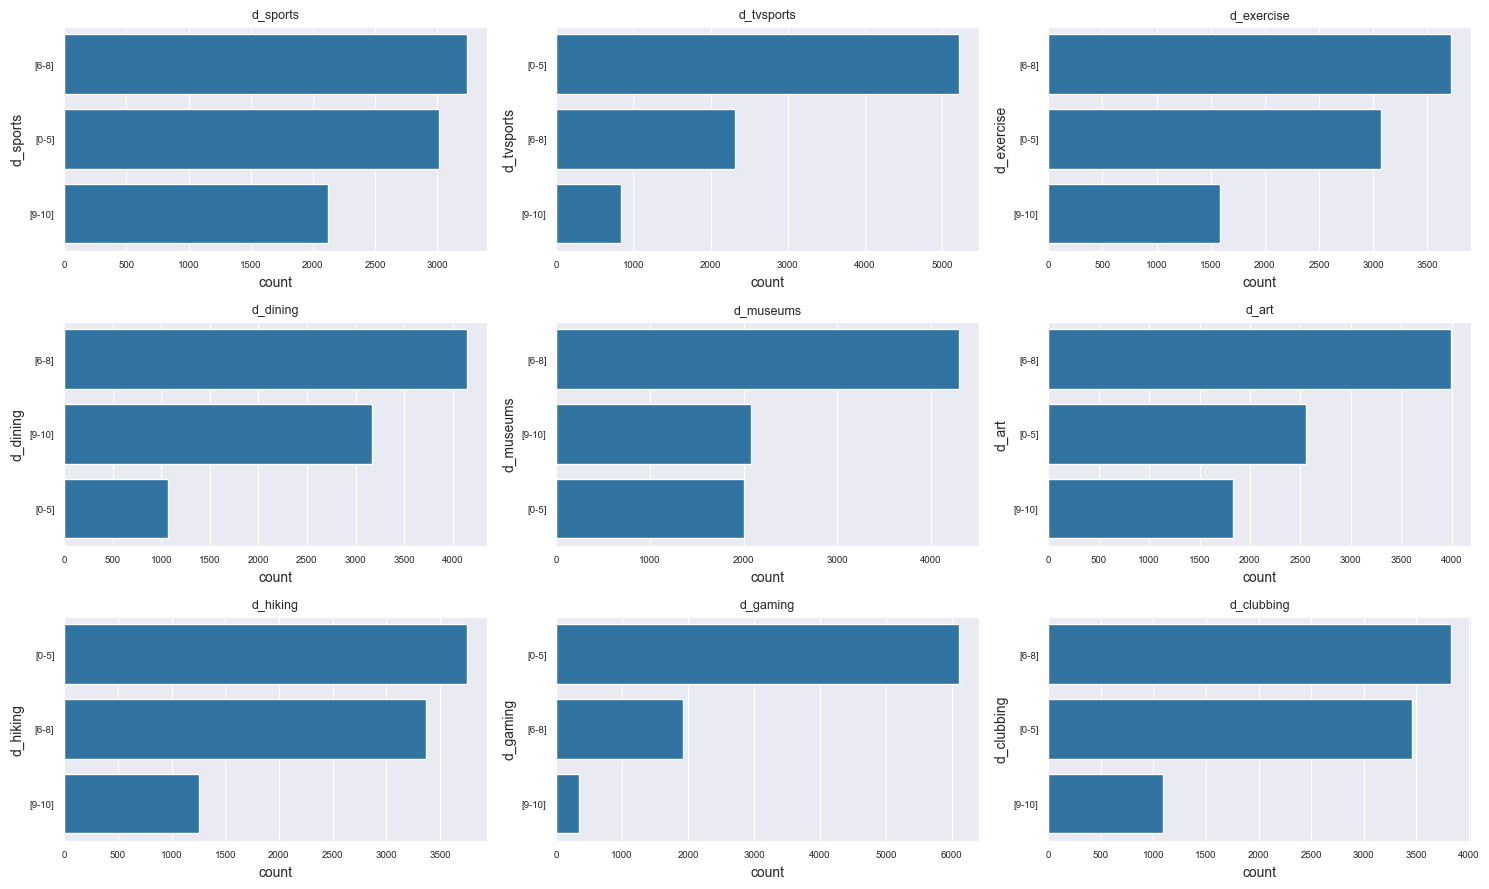

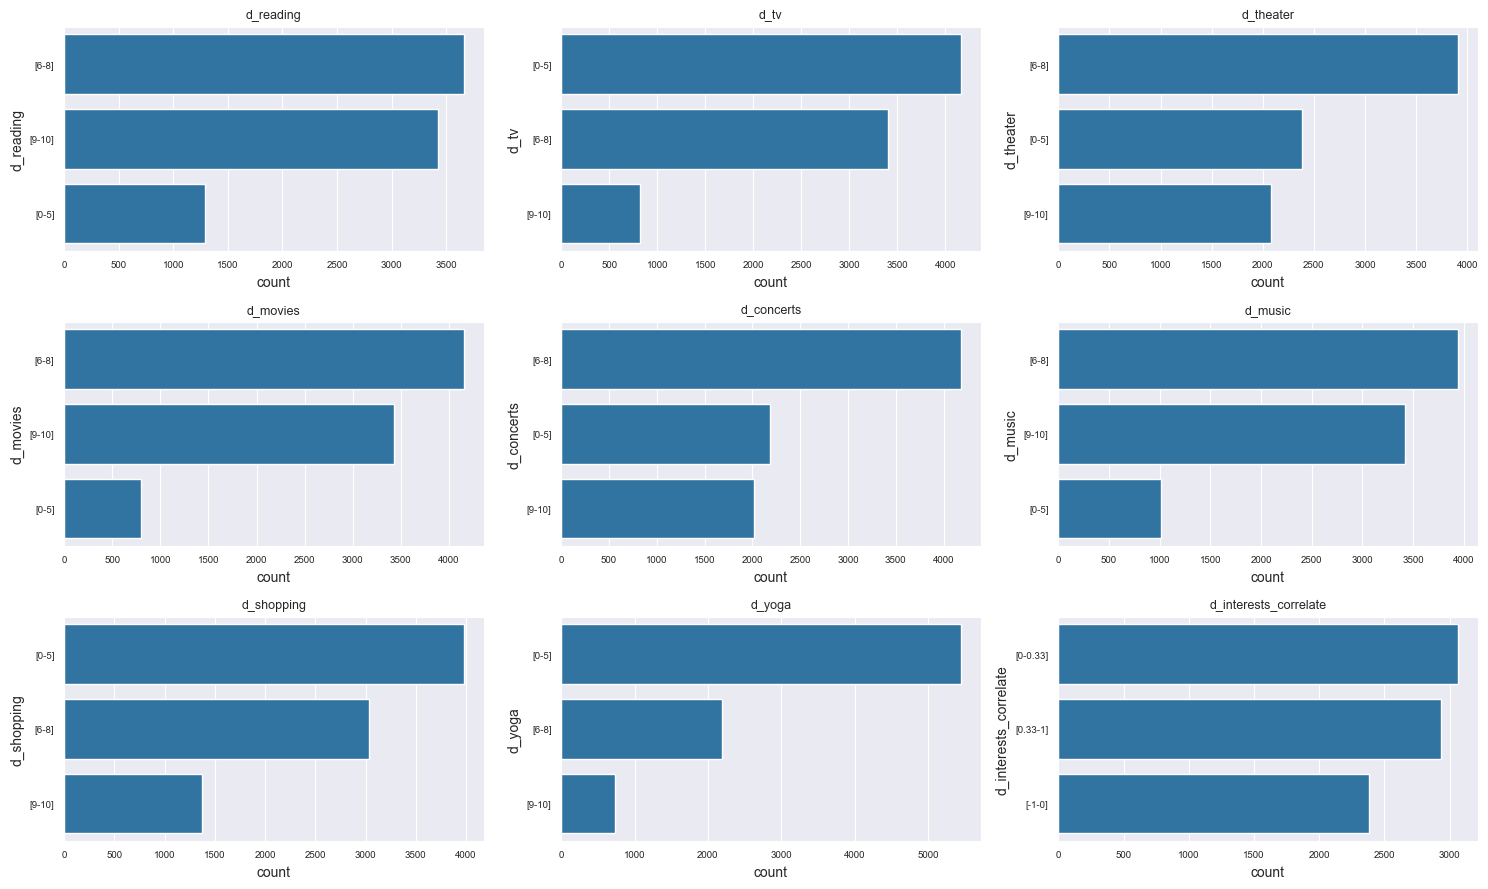

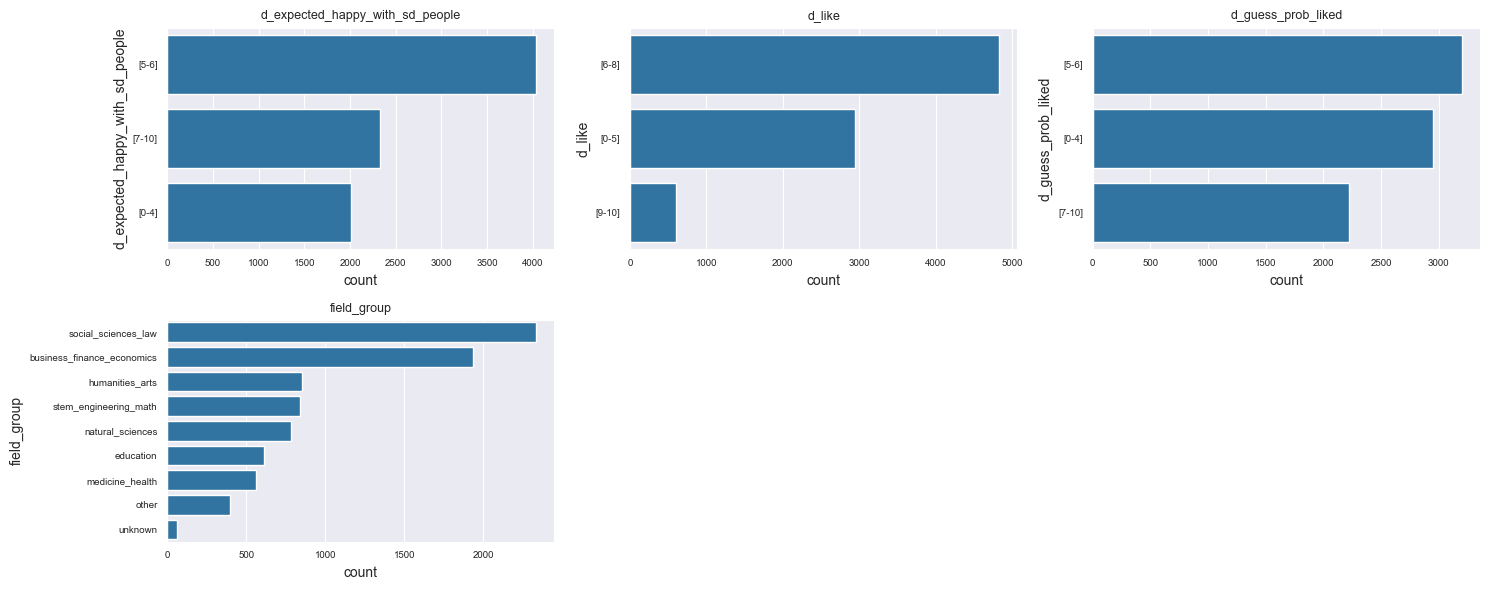

In [82]:
# категориальные — порциями по 9
for k in range(0, len(cat_cols), 9):
    plot_categorical_distributions(df_clean, cat_cols[k:k + 9])

Числовые признаки имеют преимущественно дискретный характер: веса важности 0–100 и возраст скошены вправо, а многие шкалы 1–10 (например, `sincere`, `movies`) — влево, к высоким оценкам. Бинарные показатели и разница возрастов распределены ожидаемо. Среди категориальных признаков пол представлен практически поровну, однако выражен дисбаланс по расе (доминируют европейцы/белые американцы) и специальностям (чаще всего встречаются бизнес и MBA, право и социальная работа).

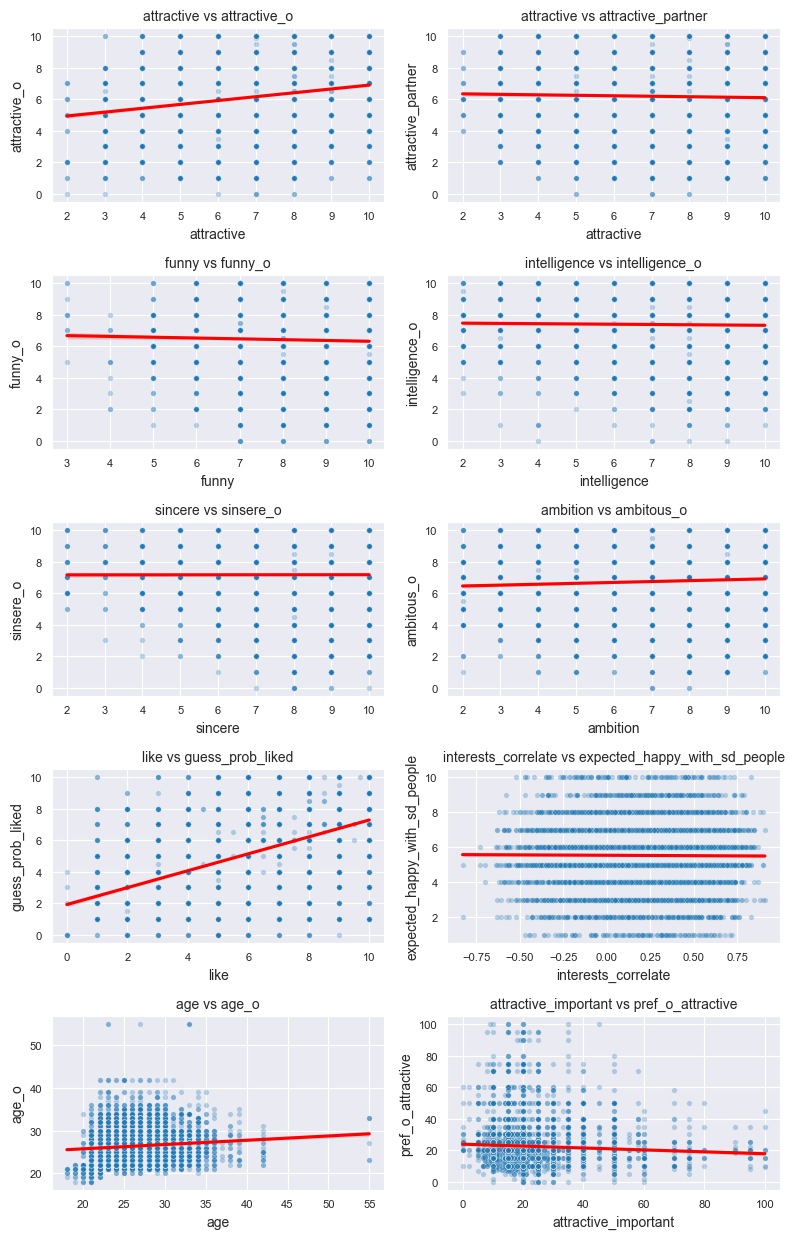

In [83]:
# рассмотрим парные распределения осмысленных пар
# выберем осмысленные пары (не все ~50×50, иначе будет каша)
pairs = [
    ("attractive", "attractive_o"),
    ("attractive", "attractive_partner"),
    ("funny", "funny_o"),
    ("intelligence", "intelligence_o"),
    ("sincere", "sinsere_o"),
    ("ambition", "ambitous_o"),
    ("like", "guess_prob_liked"),
    ("interests_correlate", "expected_happy_with_sd_people"),
    ("age", "age_o"),
    ("attractive_important", "pref_o_attractive"),
]

def plot_joint(df, pairs, ncols=2):
    n = len(pairs)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.5 * nrows))
    axes = axes.flatten()

    for i, (x, y) in enumerate(pairs):
        sns.scatterplot(data=df, x=x, y=y, alpha=0.3, s=15, ax=axes[i])
        sns.regplot(data=df, x=x, y=y, scatter=False, color="red", ax=axes[i])
        axes[i].set_title(f"{x} vs {y}", fontsize=10)
        axes[i].tick_params(labelsize=8)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_joint(df_clean, pairs)

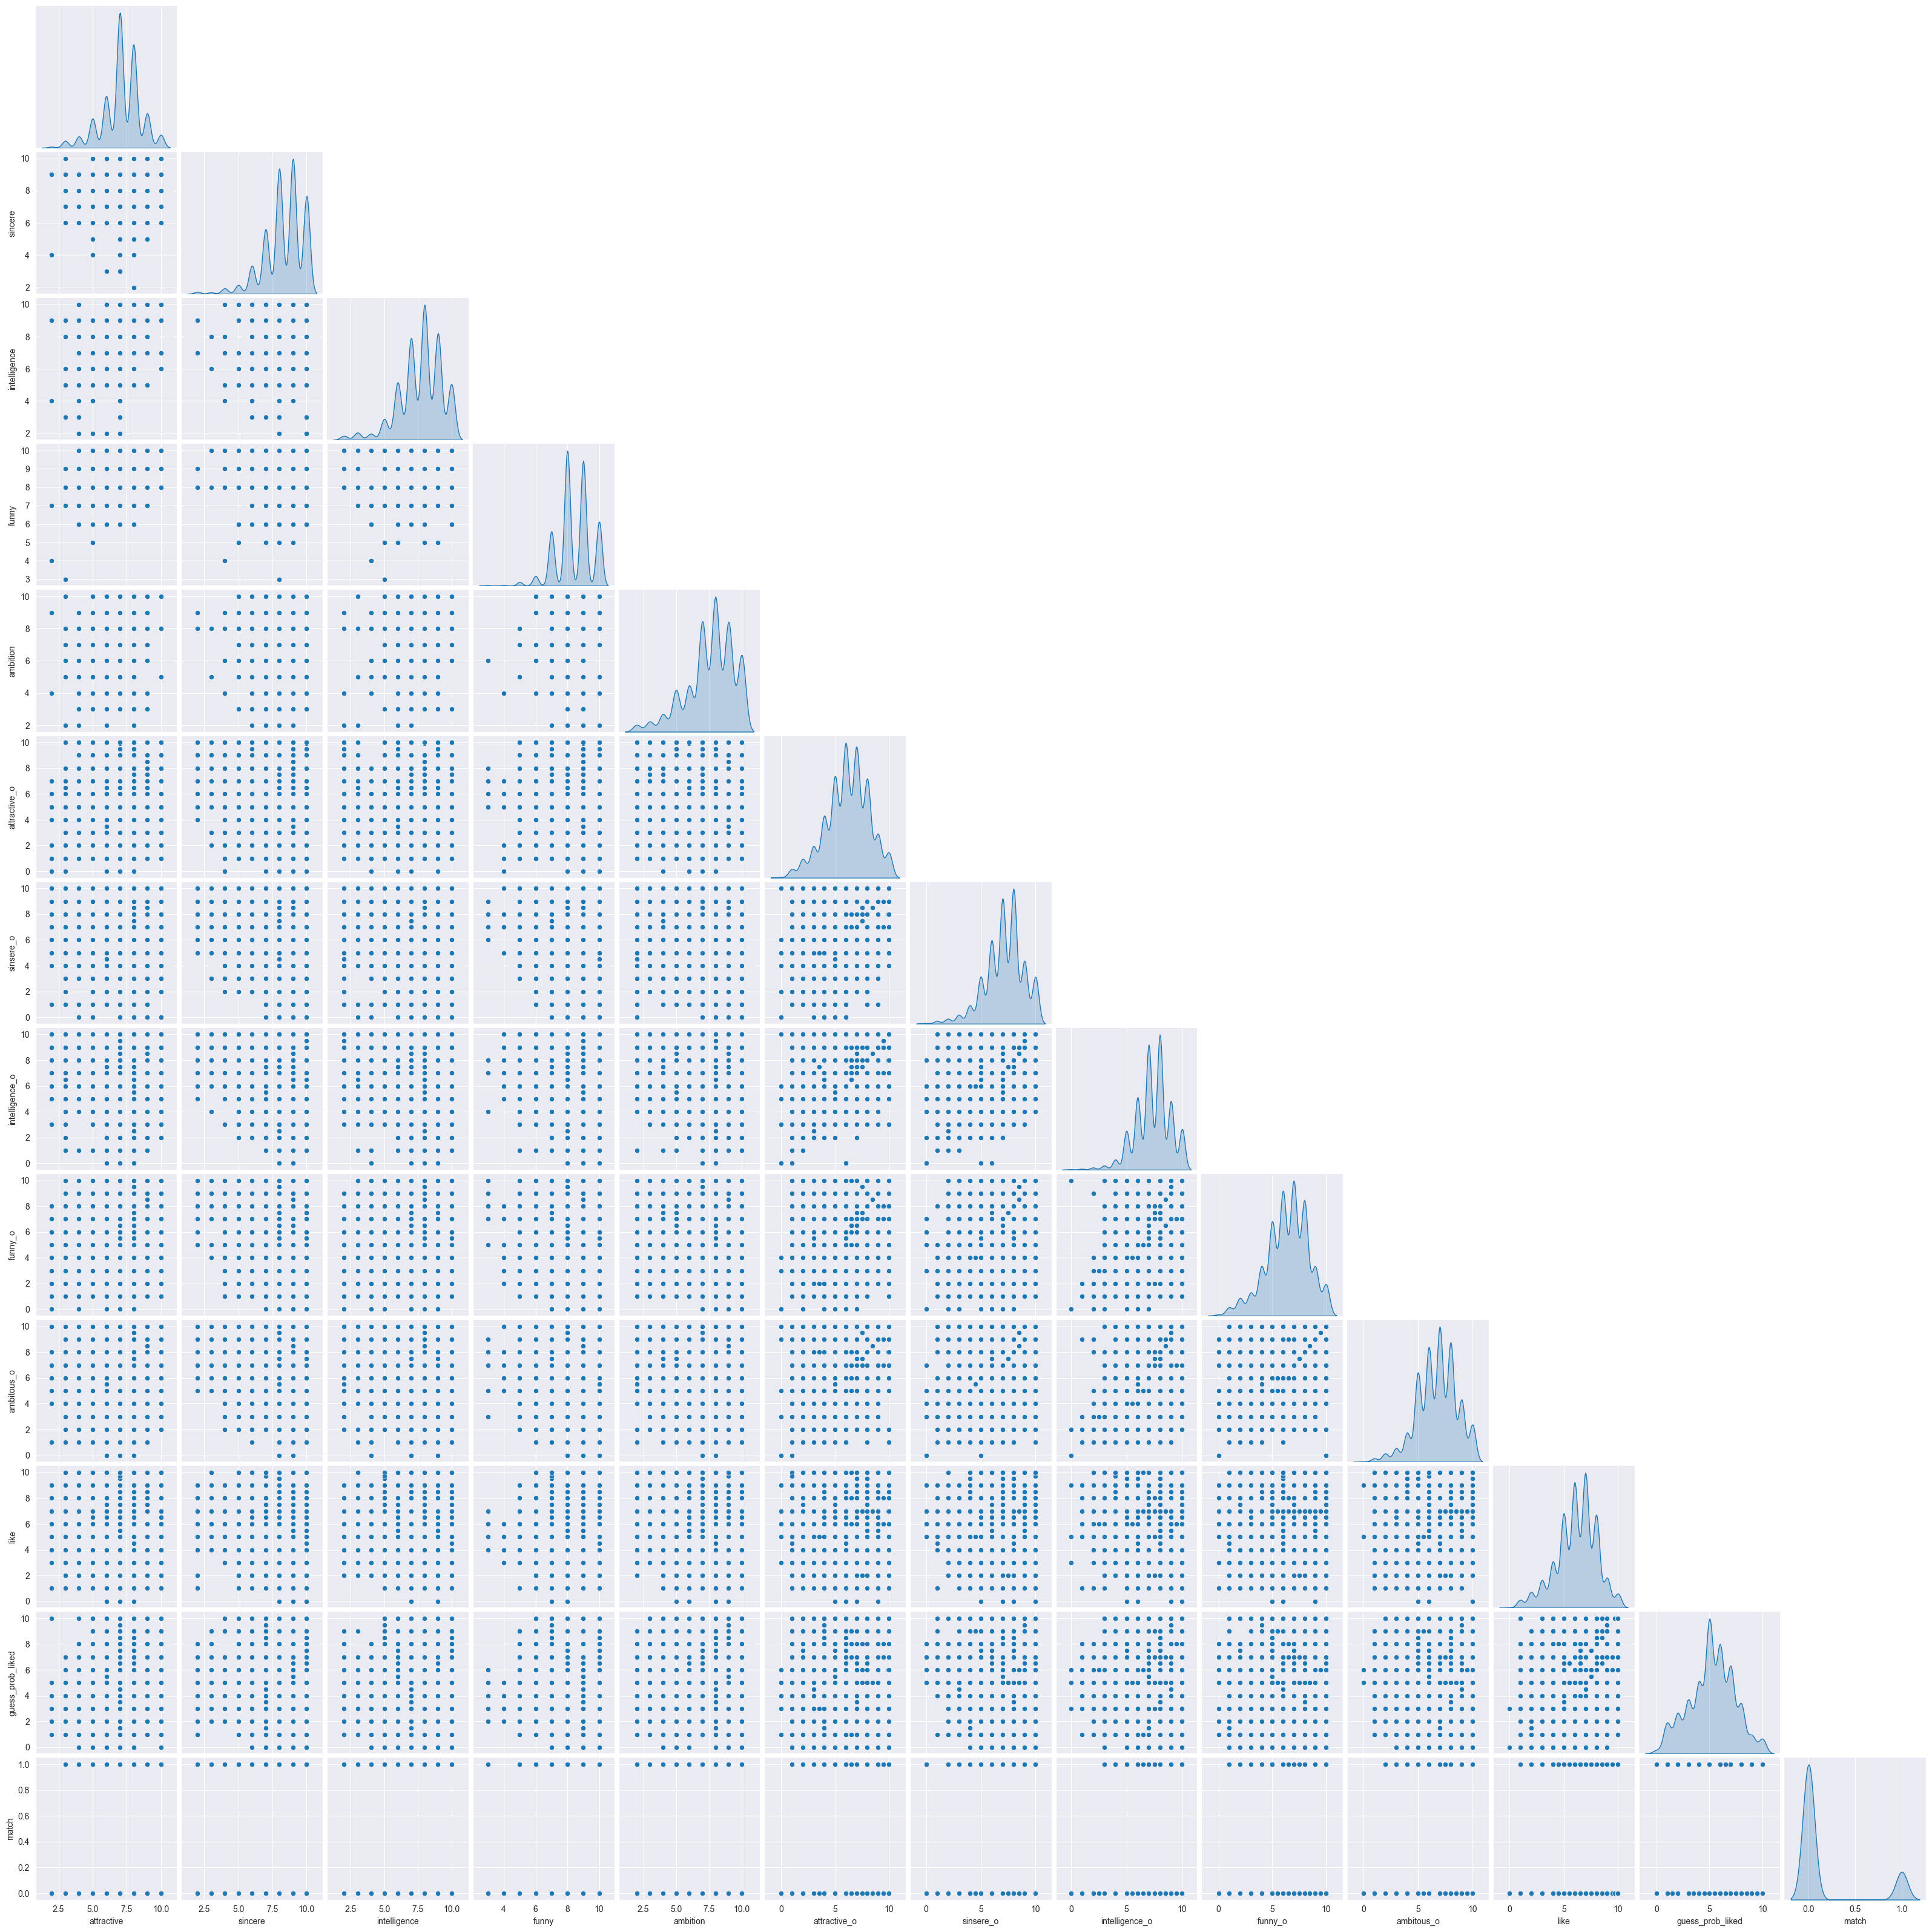

In [88]:
# посмотрим парные распределения основных параметров
subset = ["attractive", "sincere", "intelligence", "funny", "ambition",
          "attractive_o", "sinsere_o", "intelligence_o", "funny_o", "ambitous_o",
          "like", "guess_prob_liked", "match"]
sns.pairplot(df_clean[subset].dropna(), diag_kind="kde", corner=True)
plt.show()

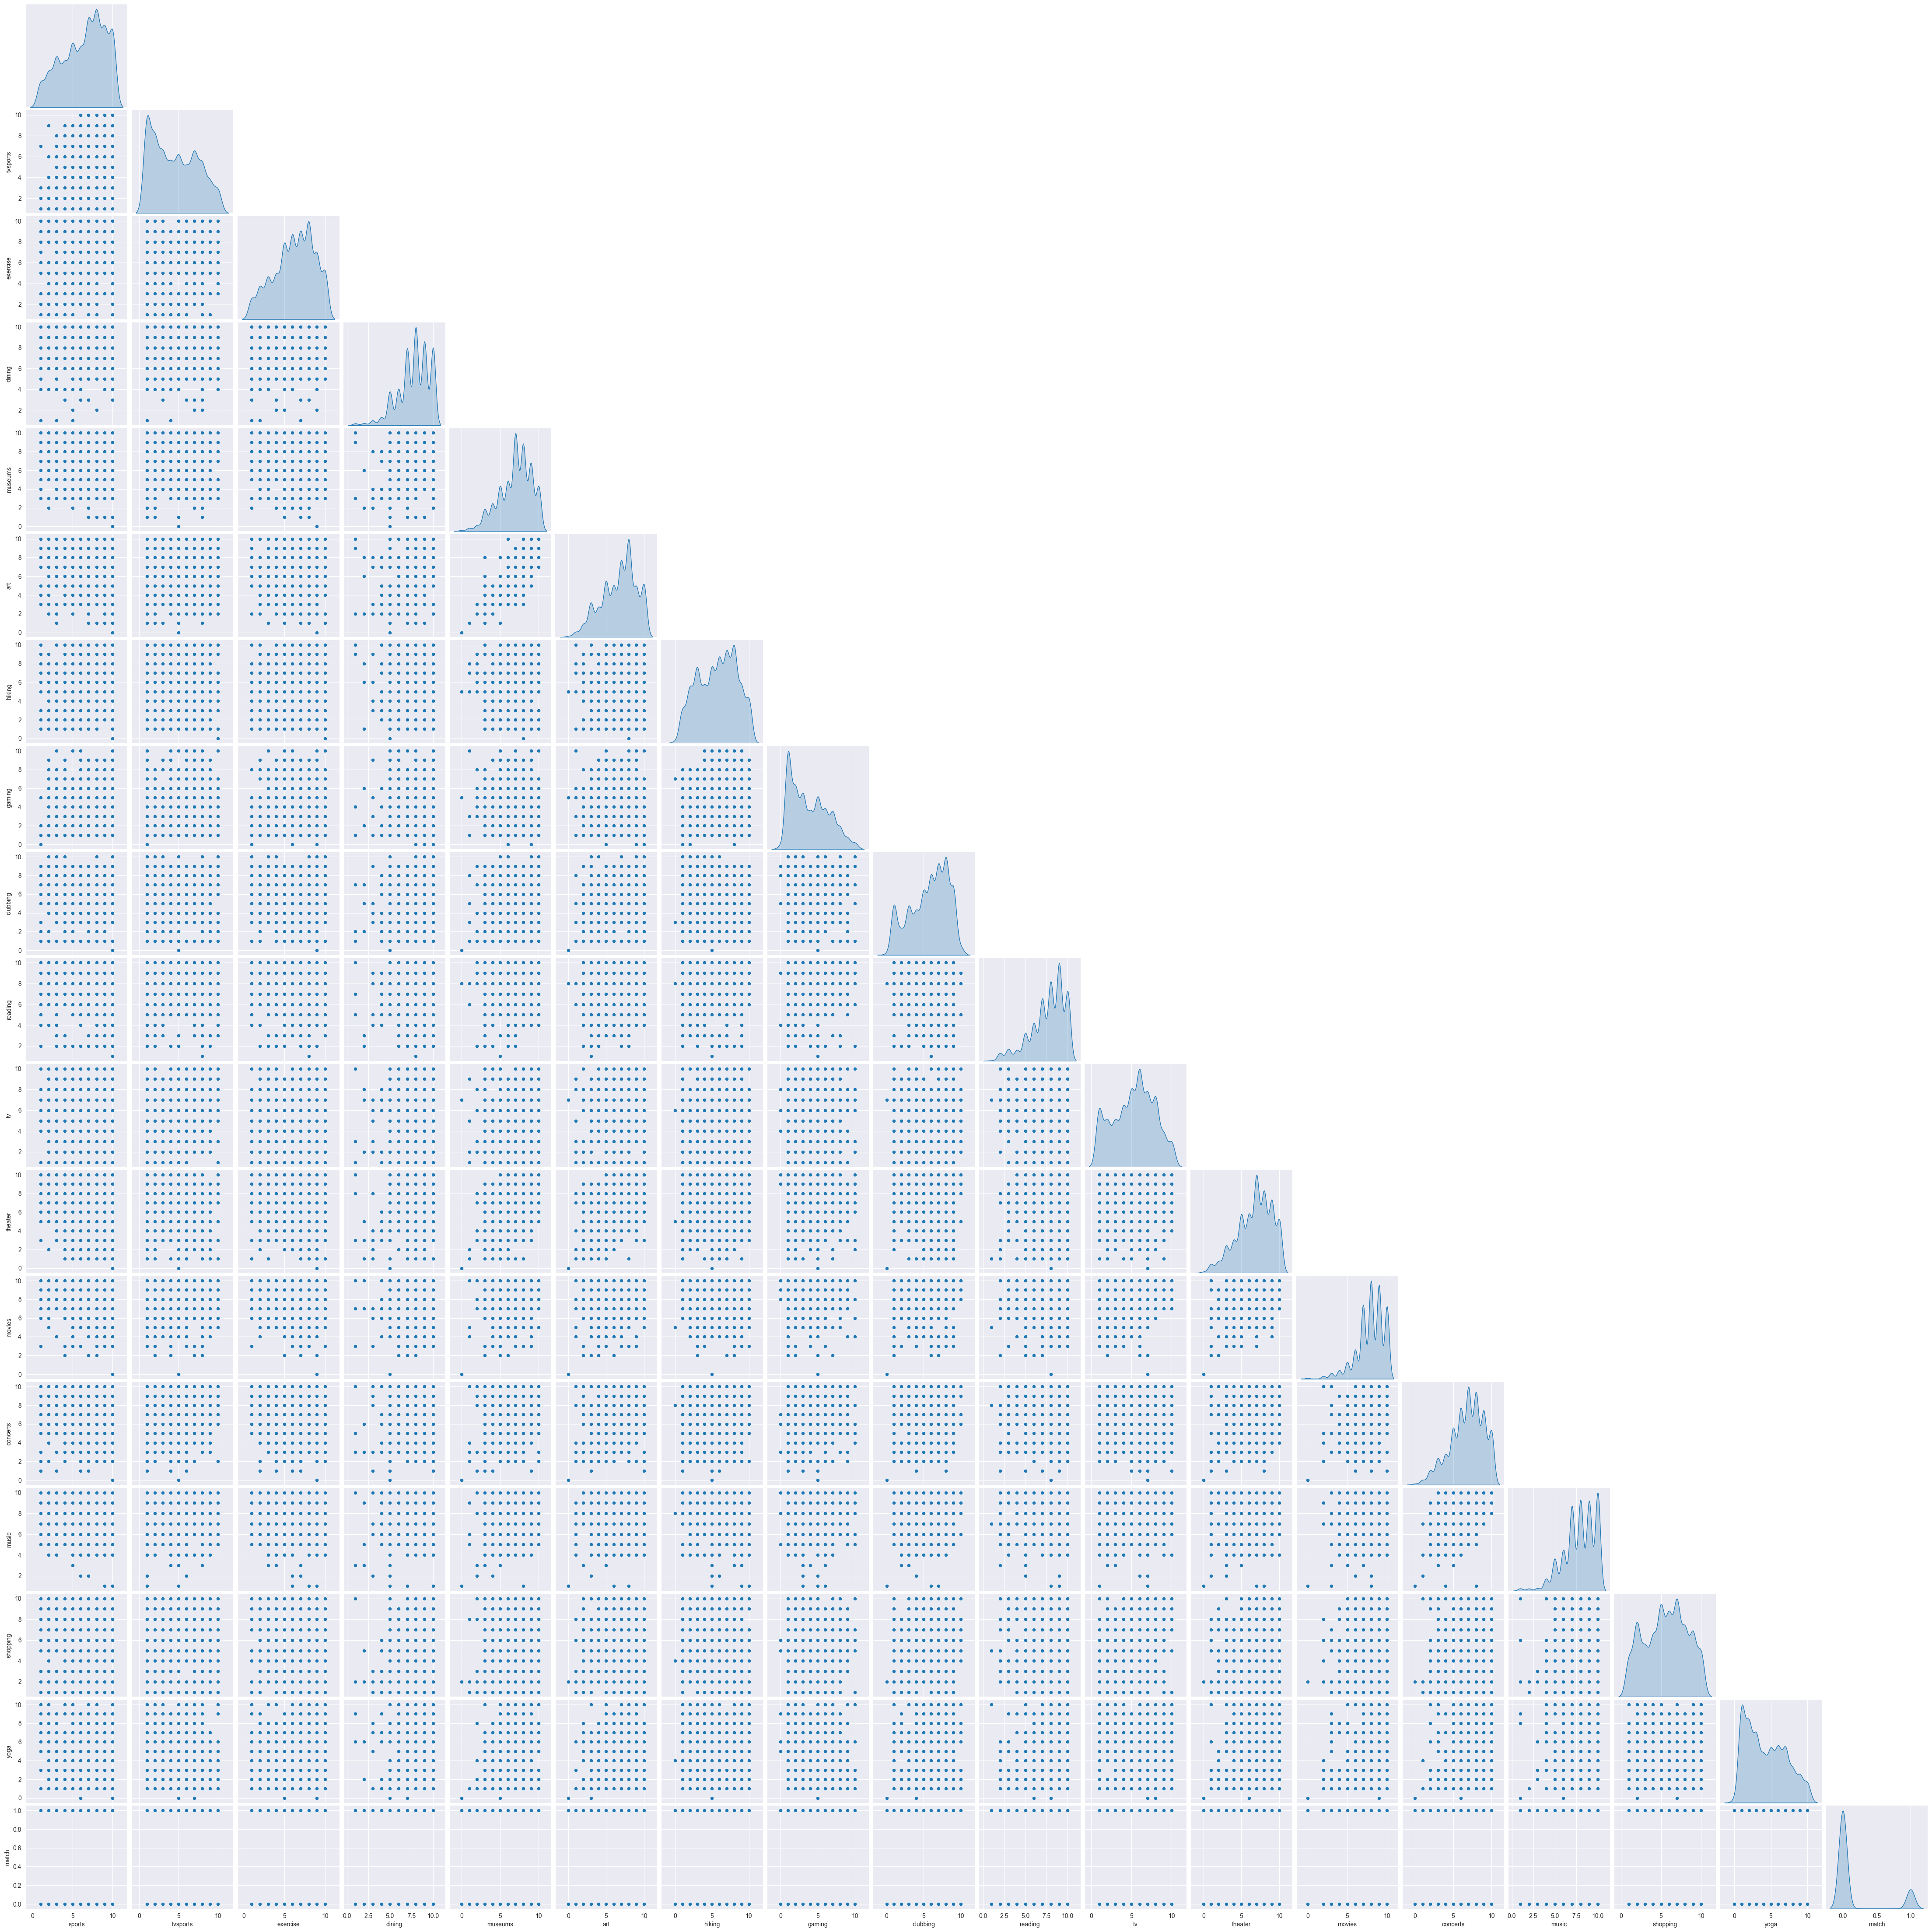

In [89]:
interests_cols = [
    "sports", "tvsports", "exercise", "dining", "museums", "art", 
    "hiking", "gaming", "clubbing", "reading", "tv", "theater", 
    "movies", "concerts", "music", "shopping", "yoga", "match"
]
sns.pairplot(df_clean[interests_cols].dropna(), diag_kind="kde", corner=True)
plt.show()

Визуальный анализ пар признаков показал, что большинство из них имеют слабую или умеренную связь, при этом заметная линейная зависимость прослеживается лишь в отдельных случаях (например, между симпатией и ожиданием взаимности). Поскольку точечные диаграммы не позволяют оценить силу и направление связей для всех переменных одновременно, перейдём к построению матрицы корреляций для комплексной количественной оценки.

Посмотрим корреляции

In [84]:
corr = df_clean[num_cols].corr(method="spearman") 

In [85]:
corr

,has_null,wave,age,age_o,d_age,samerace,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive,sincere,intelligence,funny,ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,interests_correlate,expected_happy_with_sd_people,like,guess_prob_liked,met,decision,decision_o,match
has_null,1.000000,0.515624,0.146234,0.166573,0.072788,-0.016382,-0.024854,-0.059705,-0.050398,0.018182,-0.125208,0.005589,0.067435,0.094235,-0.006586,0.002945,-0.002551,0.018174,-0.005867,0.012577,-0.040943,-0.002431,-0.107792,0.042937,0.051950,0.062201,0.043146,0.041308,0.003157,0.037424,0.058683,-0.001158,-0.007307,-0.012448,0.004652,-0.003802,0.012042,0.024902,-0.000679,0.039153,0.038402,0.040195,0.054708,0.090354,-0.018434,-0.036487,0.056091,-0.044669,-0.021826,-0.022145,-0.019820,0.024328,0.023183,0.027075,0.050621,0.025614,-0.018879,0.037673,-0.054352,-0.002146,-0.009000,-0.013011
wave,0.515624,1.000000,0.103113,0.101387,0.036124,-0.005502,-0.031203,-0.060528,0.118913,0.005201,-0.015601,0.024810,-0.146705,-0.021946,-0.022234,-0.029185,-0.037222,-0.008731,-0.028018,-0.041482,0.117101,0.005553,-0.015087,0.025124,-0.145748,-0.021626,0.038447,0.059975,0.029082,-0.030919,0.041577,-0.022105,-0.028959,-0.036616,-0.008688,-0.027478,-0.041300,0.002991,-0.033166,-0.023829,0.120655,0.083222,0.124114,0.015791,-0.019311,-0.028621,0.003186,0.000785,0.027169,0.024747,0.064339,0.060455,0.071493,0.026231,0.044952,0.065412,-0.046303,0.018454,-0.076765,-0.010912,-0.010180,-0.015530
age,0.146234,0.103113,1.000000,0.097779,0.170923,-0.010202,-0.138600,-0.063054,-0.102502,0.041238,-0.020014,-0.018681,0.091559,0.054426,-0.038445,0.006848,0.040026,-0.034964,0.034059,0.014909,0.042063,0.046241,0.035102,-0.106352,-0.086239,0.020304,0.084240,-0.013762,-0.093198,0.011347,-0.052160,0.019936,-0.009999,-0.005621,-0.013655,-0.036384,0.004599,-0.032609,-0.112401,-0.001220,0.093783,0.091522,0.067396,0.046648,-0.162021,-0.056825,0.090928,-0.219723,-0.015163,-0.034277,-0.090969,-0.082392,-0.157904,0.012422,0.093775,0.011124,0.009040,0.012347,-0.068474,0.001800,-0.032236,-0.029608
age_o,0.166573,0.101387,0.097779,1.000000,0.170923,-0.011630,-0.004378,0.037690,0.044087,0.045455,0.034064,-0.107195,-0.087210,0.020113,0.019739,-0.010460,-0.006732,-0.014099,-0.037349,0.004411,-0.102502,0.041238,-0.020014,-0.018681,0.091559,0.054426,0.004528,0.022254,0.001377,-0.001852,-0.004605,-0.038445,0.006848,0.040026,-0.034964,0.034059,0.014909,-0.011746,-0.026715,0.028811,0.028910,0.057611,0.058627,0.034260,-0.074924,-0.030367,0.018216,-0.004906,0.040754,0.028144,0.002689,0.010950,0.026808,0.040655,0.092407,-0.021470,-0.025917,-0.003066,-0.060705,-0.033763,0.001100,-0.030412
d_age,0.072788,0.036124,0.170923,0.170923,1.000000,0.057728,-0.037970,0.005402,0.006075,0.007913,-0.008243,-0.019480,-0.016406,0.029011,-0.038963,-0.006497,-0.015013,-0.027619,-0.021689,-0.013644,0.006075,0.007913,-0.008243,-0.019480,-0.016406,0.029011,0.004306,-0.032228,-0.013359,-0.027805,-0.015907,-0.038963,-0.006497,-0.015013,-0.027619,-0.021689,-0.013644,-0.026442,-0.024195,-0.006317,-0.022541,0.022387,0.027114,-0.013245,-0.080981,-0.055059,0.023290,-0.019822,0.019904,0.011276,-0.003582,0.008435,-0.027080,0.054584,0.021478,0.047060,-0.052263,-0.043904,-0.108732,-0.042342,-0.042342,-0.067670
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,.

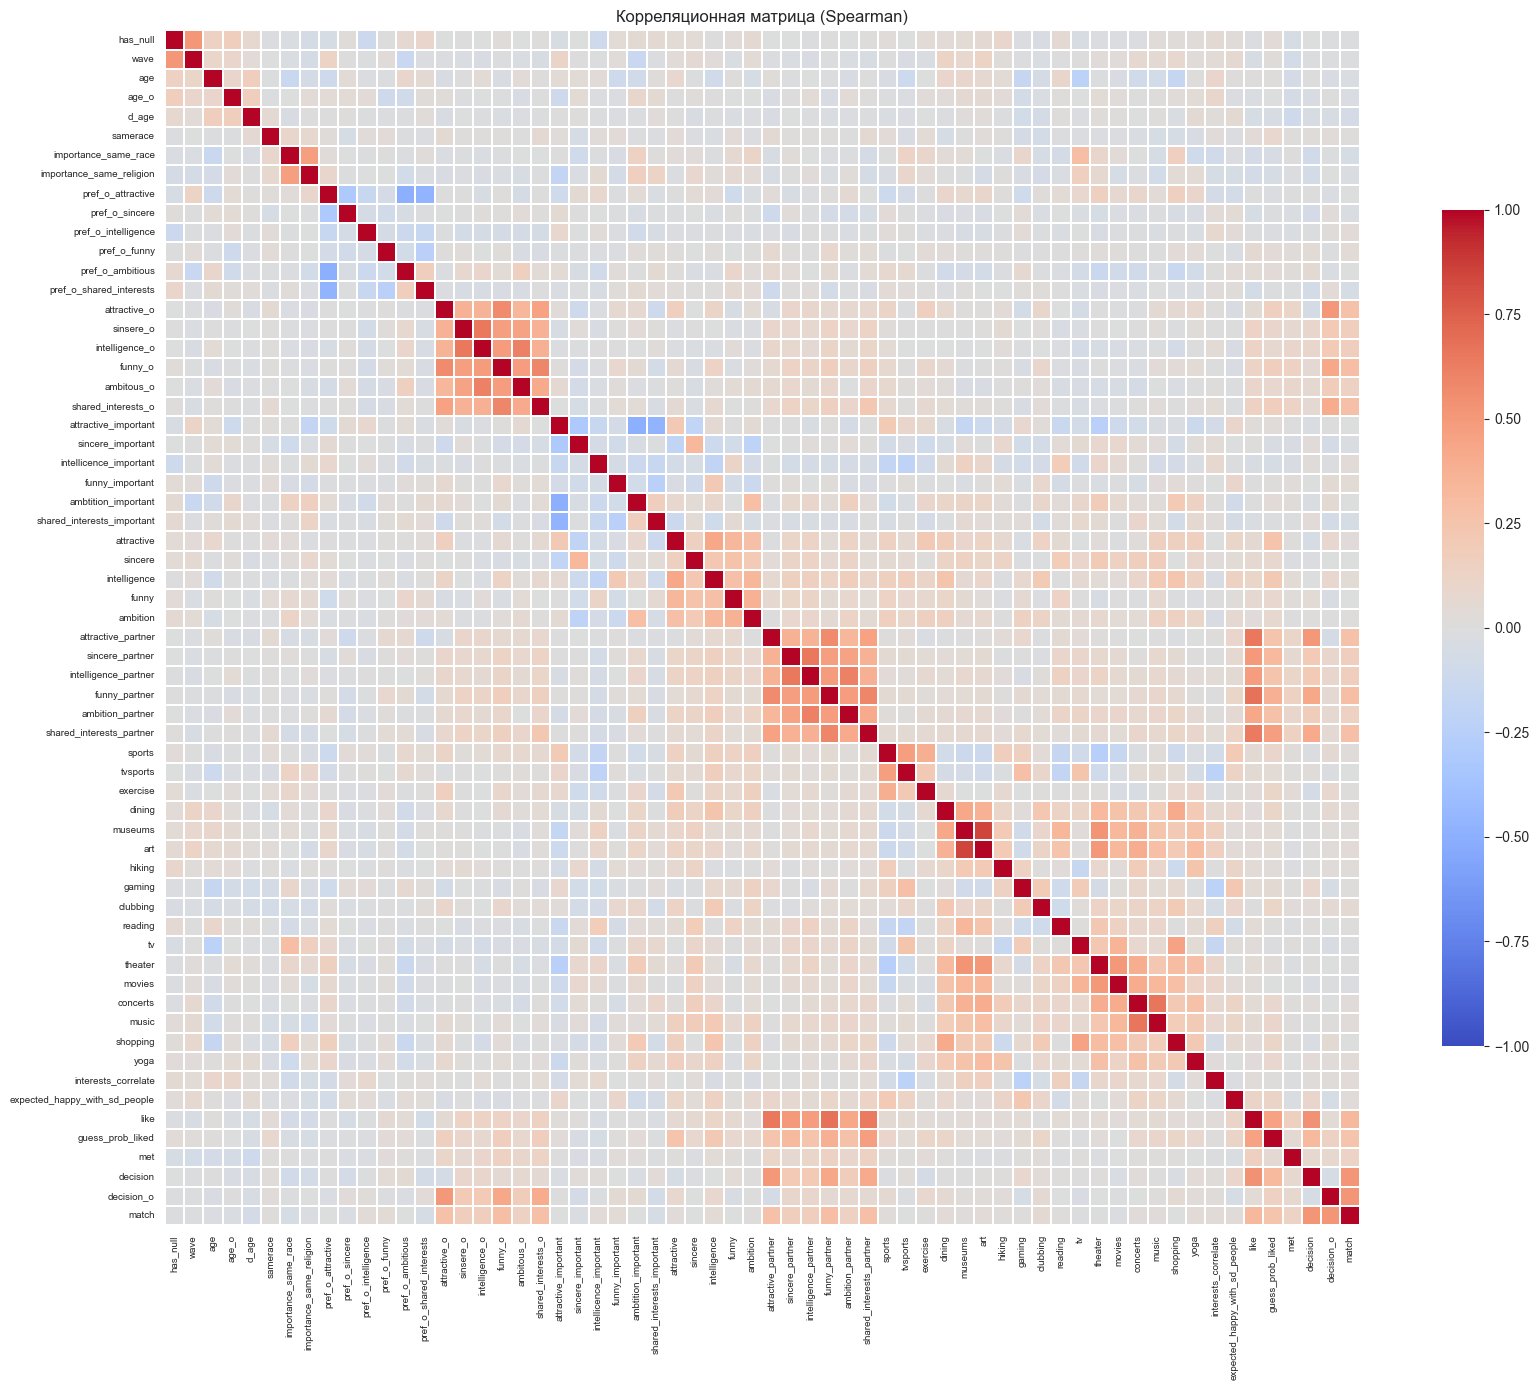

In [86]:
plt.figure(figsize=(18, 14))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.7},
    xticklabels=True, yticklabels=True,
)
plt.xticks(fontsize=7, rotation=90)
plt.yticks(fontsize=7)
plt.title("Корреляционная матрица (Spearman)", fontsize=12)
plt.tight_layout()
plt.show()

In [87]:
# рассмотрим какие признаки имеют корреляцию выше предела
corr_matrix = df_clean[num_cols].corr(method="spearman").abs()

# Оставляем только верхний треугольник 
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Находим пары с корреляцией выше порога
threshold = 0.7
high_corr = upper.stack().reset_index()
high_corr.columns = ["feature_1", "feature_2", "corr"]
high_corr = high_corr[high_corr["corr"] > threshold].sort_values("corr", ascending=False)

if high_corr.empty:
    print(f"Признаков с корреляцией выше {threshold} не найдено.")
else:
    print(f"Найдено пар с корреляцией > {threshold}: {len(high_corr)}\n")
    display(high_corr.round(3))

Найдено пар с корреляцией > 0.7: 1


,feature_1,feature_2,corr
1681,museums,art,0.848


In [90]:
# посмотрим какие признаки сильно коррелируют с зависимой переменной
corr_match = corr["match"].drop("match").sort_values(key=abs, ascending=False)
display(corr_match.head(15).round(3).to_frame("corr_with_match"))
print("доля match по met:", df_clean.groupby("met")["match"].mean().round(3).to_dict())

,corr_with_match
decision_o,0.522
decision,0.522
like,0.321
funny_o,0.289
funny_partner,0.289
shared_interests_o,0.277
shared_interests_partner,0.277
attractive_o,0.270
attractive_partner,0.270
guess_prob_liked,0.253


доля match по met: {0.0: 0.158, 1.0: 0.399}

**Вывод.**  
Анализ матрицы корреляций выявил лишь одну пару признаков с очень высокой связью (|r| > 0.7): `museums` и `art` (r = 0.85), что логично объясняется пересекающимися интересами к культурным мероприятиям. Остальные попарные корреляции слабые или умеренные. Это не исключает мультиколлинеарности между группами признаков, но сильных попарных связей нет.

При оценке связи с целевой переменной `match` наибольшие коэффициенты оказались у `decision_o` и `decision` (≈ 0.52) — это механически ожидаемо: `match` равен 1, только если оба решения равны 1. Следом идёт `like` (≈ 0.32). Среди оценок партнёра сильнее всего с `match` связаны юмор (≈ 0.29), общие интересы (≈ 0.28) и внешность (≈ 0.27). Пары `*_o` и `*_partner` дают почти одинаковые коэффициенты — следствие того, что каждая встреча записана двумя зеркальными строками. Объективные демографические показатели (возраст, раса) почти не коррелируют с исходом свидания.

Поскольку классические линейные корреляции не дают полной картины (особенно для бинарной целевой переменной), перейдём к более детальному рассмотрению `match`.

### Анализ зависимой переменной

In [91]:
df_clean['match'].value_counts()

match
0    6998
1    1380
Name: count, dtype: int64

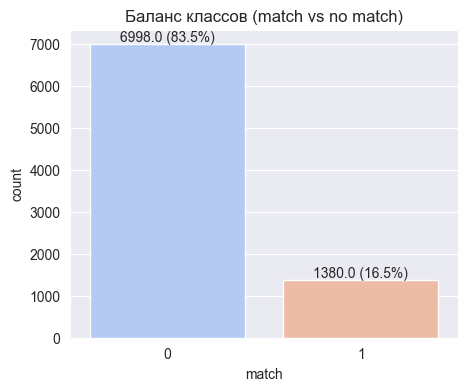

In [92]:
# Баланс классов
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df_clean, x='match', palette='coolwarm')
total = len(df_clean)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height} ({height/total:.1%})', 
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom')
plt.title('Баланс классов (match vs no match)')
plt.show()

In [93]:
# рассмотрим деление match по группам признаков
features_partner = ['attractive_o', 'sinsere_o', 'intelligence_o', 'funny_o', 'ambitous_o', 'shared_interests_o']
features_partner_gives = ['attractive_partner', 'sincere_partner', 'intelligence_partner', 'funny_partner', 'ambition_partner', 'shared_interests_partner']
features_self = ['attractive', 'sincere', 'intelligence', 'funny', 'ambition']
features_meta = ['guess_prob_liked', 'met', 'interests_correlate', 'expected_happy_with_sd_people']
features_demo = ['age', 'age_o', 'd_age', 'importance_same_race', 'importance_same_religion']

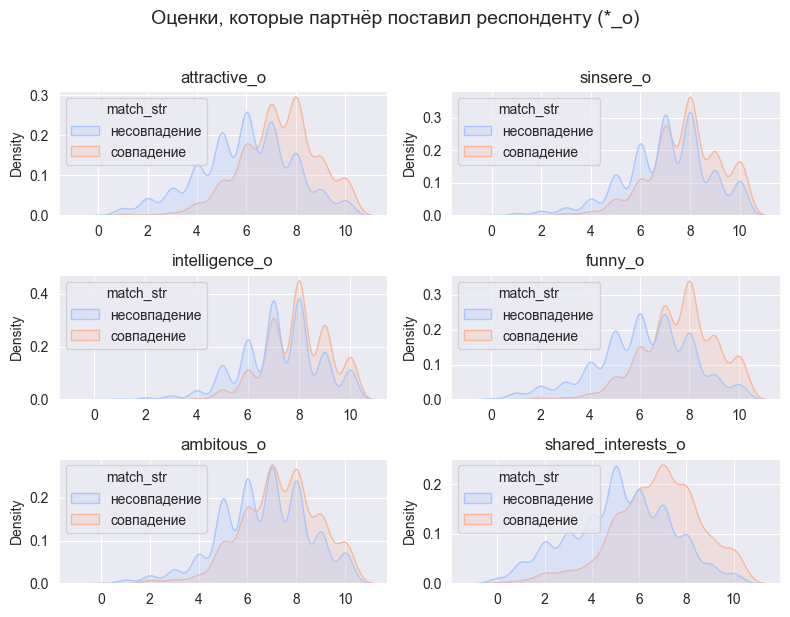

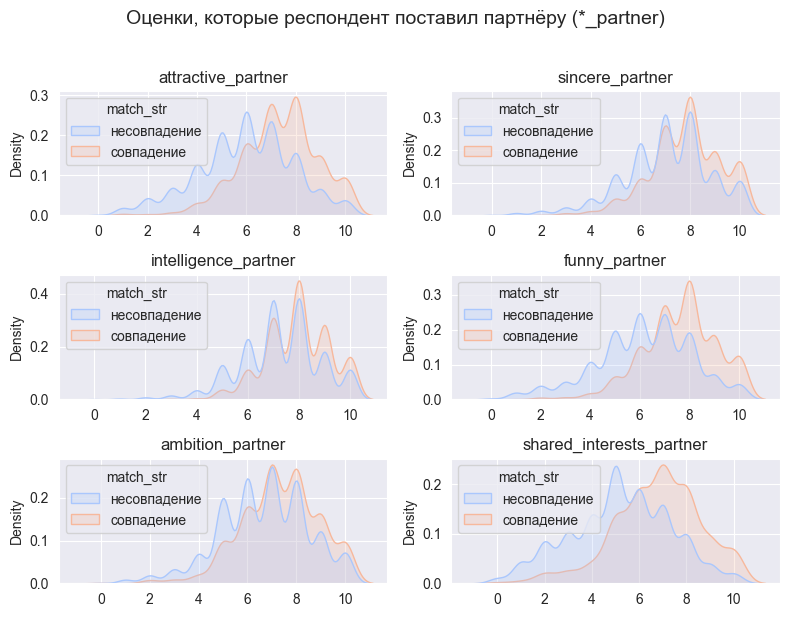

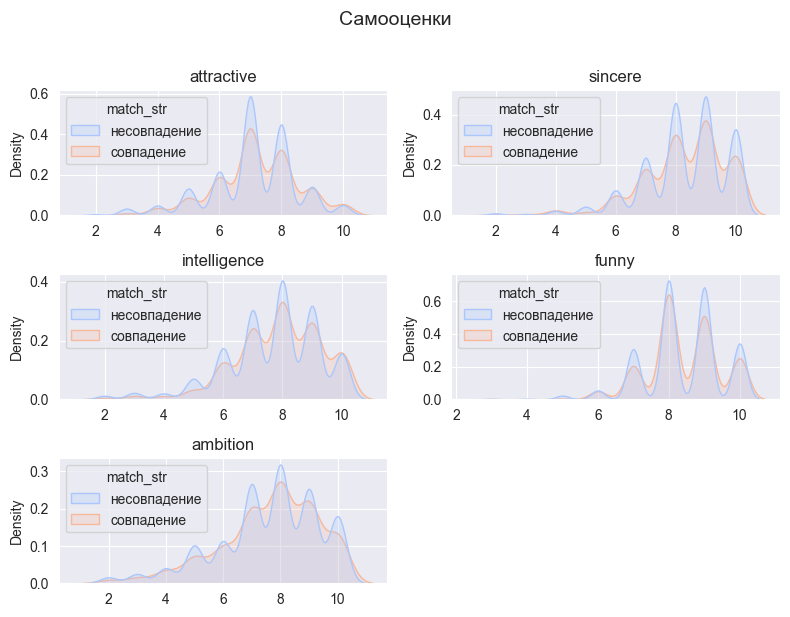

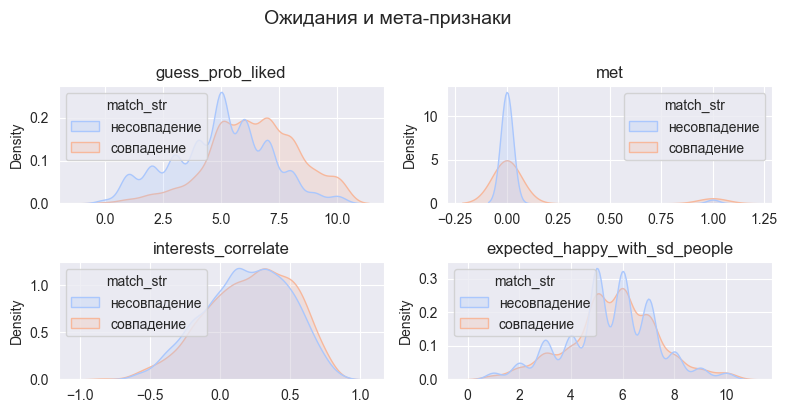

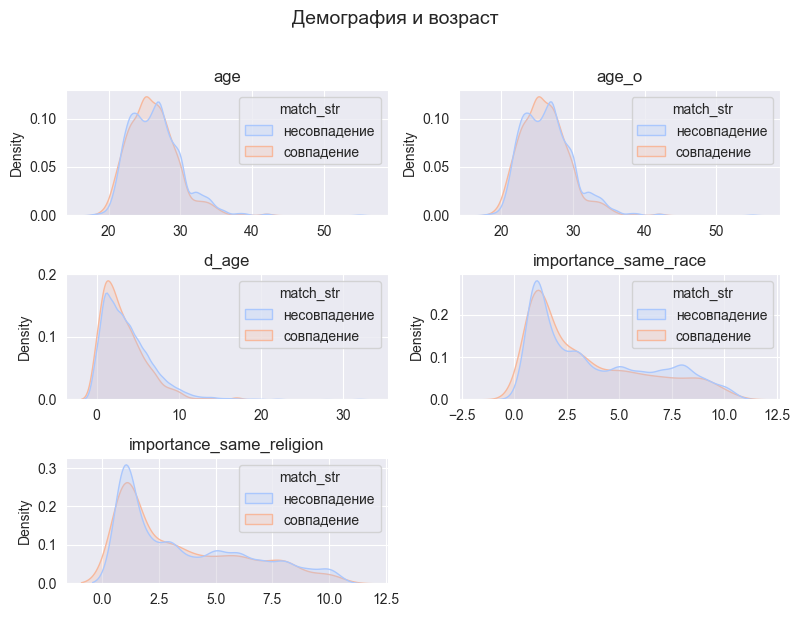

In [94]:
df_clean['match_str'] = df_clean['match'].map({0: 'несовпадение', 1: 'совпадение'})

def plot_kde_features(df, features, ncols=2, title=""):
    n = len(features)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2 * nrows))
    axes = axes.flatten()
    
    for i, feat in enumerate(features):
        sns.kdeplot(data=df, x=feat, hue='match_str', fill=True, common_norm=False, ax=axes[i], palette='coolwarm')
        axes[i].set_title(feat)
        axes[i].set_xlabel('')
        
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    fig.suptitle(title, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# Вызовы для всех групп
plot_kde_features(df_clean, features_partner, title="Оценки, которые партнёр поставил респонденту (*_o)")
plot_kde_features(df_clean, features_partner_gives, title="Оценки, которые респондент поставил партнёру (*_partner)")
plot_kde_features(df_clean, features_self, title="Самооценки")
plot_kde_features(df_clean, features_meta, title="Ожидания и мета-признаки")
plot_kde_features(df_clean, features_demo, title="Демография и возраст")

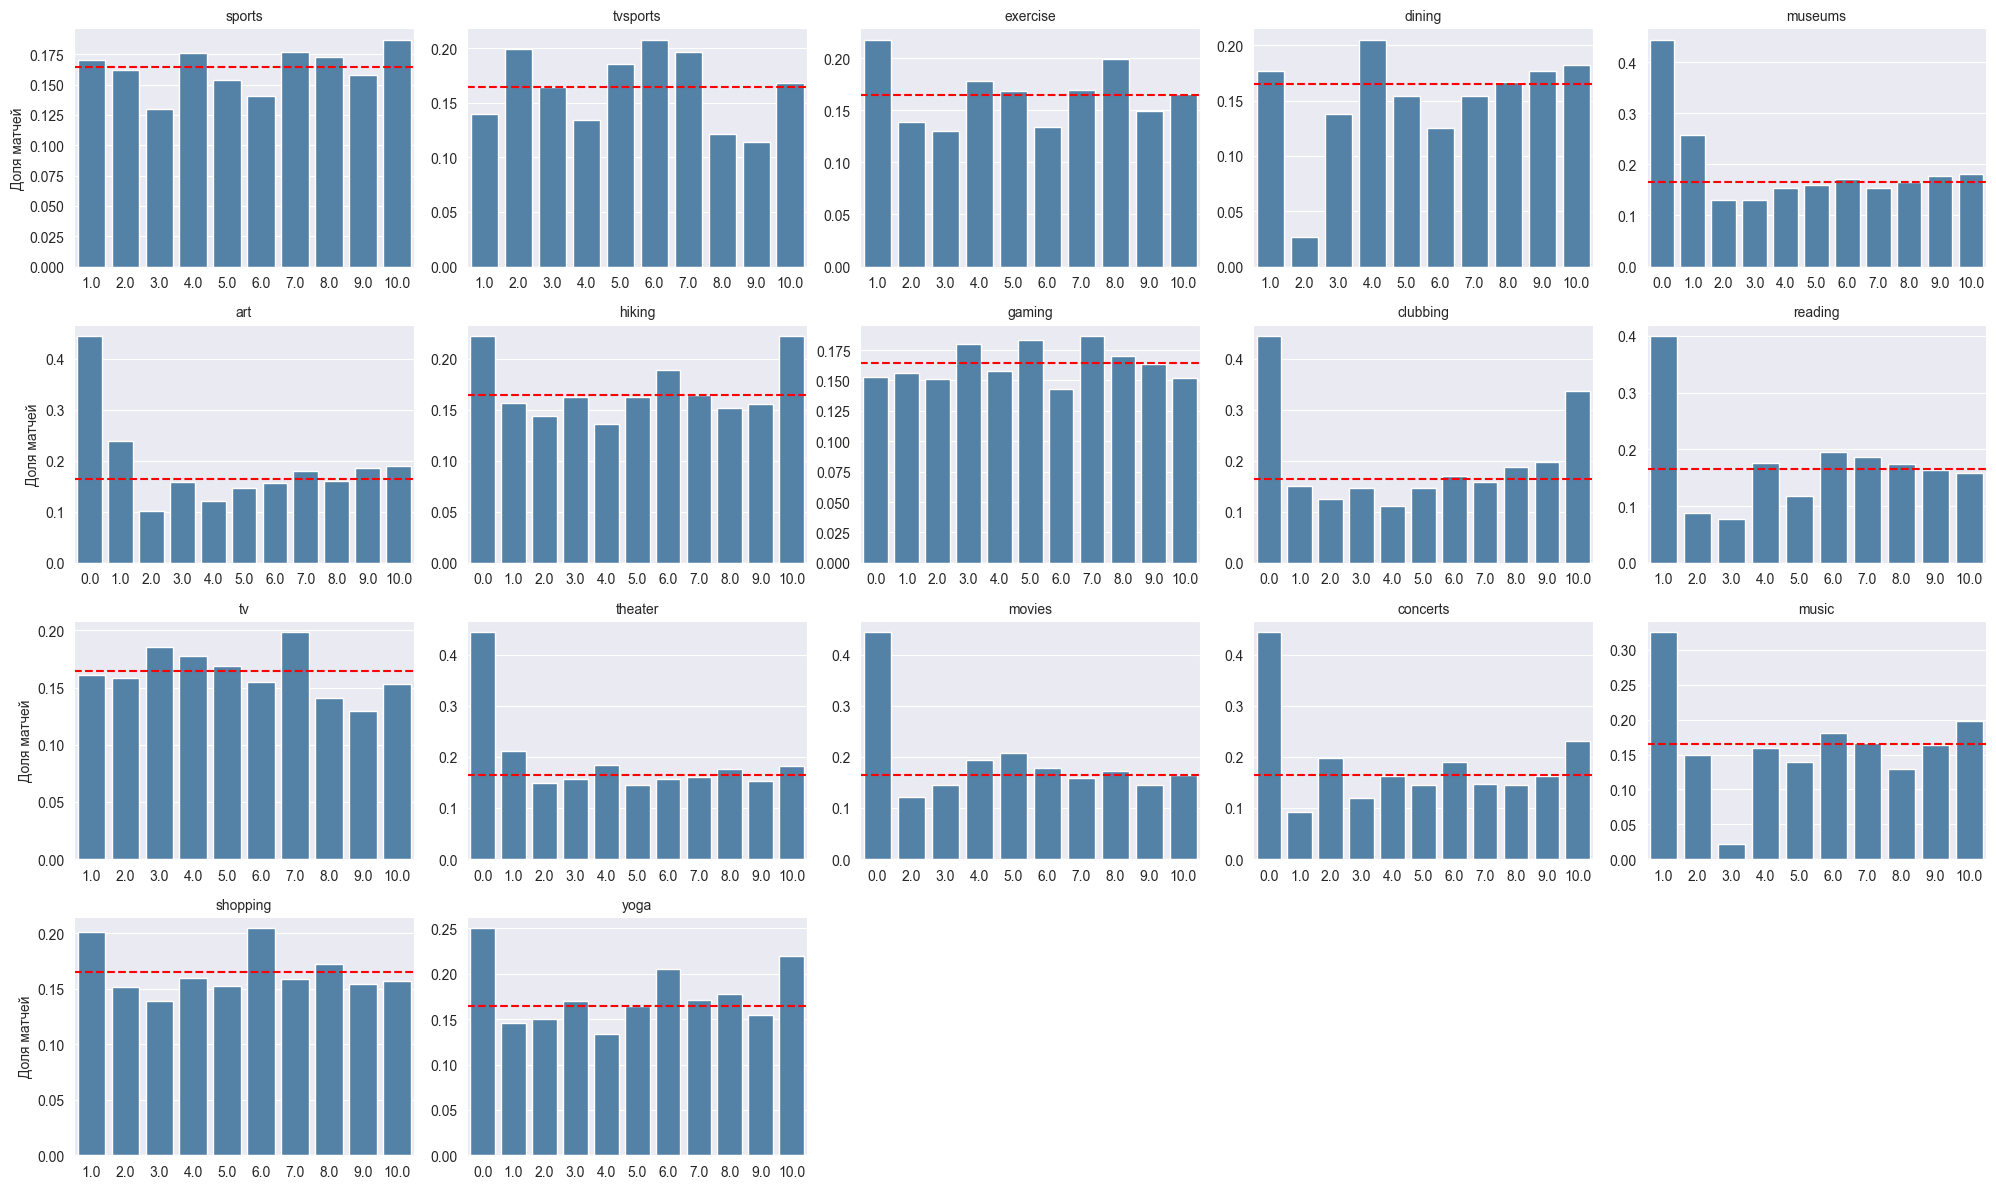

In [95]:
# доля матчей в зависимости от категории
features_interest = ['sports', 'tvsports', 'exercise', 'dining', 'museums', 
                     'art', 'hiking', 'gaming', 'clubbing', 'reading', 
                     'tv', 'theater', 'movies', 'concerts', 'music', 'shopping', 'yoga']

fig, axes = plt.subplots(4, 5, figsize=(20, 12))
axes = axes.flatten()

for i, feat in enumerate(features_interest):
    match_rate = df_clean.groupby(feat)['match'].mean().reset_index()
    sns.barplot(data=match_rate, x=feat, y='match', color='steelblue', ax=axes[i])
    axes[i].set_title(feat, fontsize=10)
    axes[i].set_ylabel('Доля матчей' if i % 5 == 0 else '')
    axes[i].set_xlabel('')
    axes[i].axhline(df_clean['match'].mean(), color='red', linestyle='--')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Отдельно рассмотрим распределение для полов

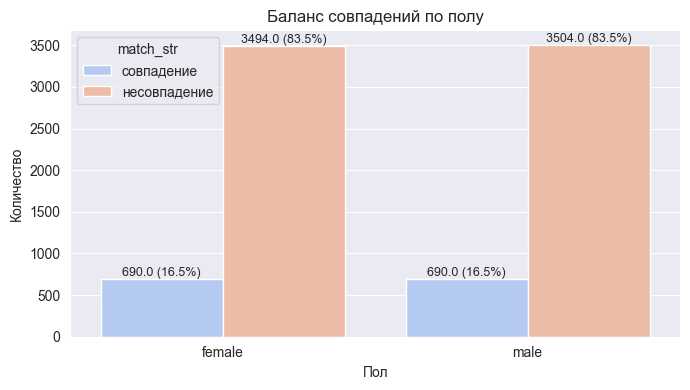

        decision  match
gender                 
female     0.365  0.165
male       0.474  0.165

In [96]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(
    data=df_clean,
    x='gender',
    hue='match_str',
    hue_order=['совпадение', 'несовпадение'], palette='coolwarm'
)

# подписи процентов
total_per_gender = df_clean.groupby('gender').size()
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        gender = ax.get_xticklabels()[round(p.get_x() + p.get_width() / 2)].get_text()  # round: столбцы hue смещены от тика
        ax.annotate(f'{h} ({h / total_per_gender[gender]:.1%})',
                    (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=9)

plt.title('Баланс совпадений по полу')
plt.xlabel('Пол')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()

# Доля match у женских и мужских строк одинакова по построению: каждая встреча записана двумя строками,
# по одной от каждого участника. Различие видно в индивидуальных решениях
print(df_clean.groupby('gender')[['decision', 'match']].mean().round(3))

**Вывод по распределениям признаков в разрезе `match`**

Целевая переменная несбалансирована: совпадение встречается примерно в 16,5% случаев. Анализ распределений показал, что `match` заметно связан как с оценками, которые респондент поставил партнёру (особенно внешность и чувство юмора), так и с оценками партнёра: при высоких оценках с обеих сторон доля матчей заметно выше. При этом самооценки респондента почти не различаются между группами. Демографические признаки (возраст, разница в возрасте) и корреляция интересов (`interests_correlate`) не показывают заметной связи с исходом свидания (статистически это не проверялось). Факт знакомства (`met`) с матчем связан: среди тех, кто встречался раньше, совпадений около 40% против 16% у остальных, но таких встреч немного (около 4%). Анализ интересов к хобби не выявил устойчивых закономерностей: для большинства активностей доля матчей слабо зависит от уровня интереса, а наблюдаемые колебания (например, пики при отдельных значениях в `gaming`, `yoga`, `art`) носят разрозненный характер и не образуют общего тренда. Доля совпадений у женщин и мужчин одинакова (по 16,5%, по 690 матчей с каждой стороны), но это следствие устройства данных, а не вывод: каждая встреча записана двумя строками — от каждого участника, поэтому каждый матч попадает и в женскую, и в мужскую строку. Различие есть в индивидуальных решениях: женщины говорят «да» в 36,5% встреч, мужчины — в 47,4%. Таким образом, с взаимной симпатией связаны прежде всего высокие взаимные оценки партнёров, а не самооценка или формальные характеристики.

Таким образом, следующим шагом проанализируем взаимную симпатию.

### Анализ взаимности и симпатии

Хотя первичный анализ в разрезе целевой переменной match выявил ключевые паттерны, для более глубокого понимания механизма возникновения совпадений необходимо рассмотреть саму природу взаимной и односторонней симпатии. Перейдём к детальному анализу взаимных оценок, роли общих интересов и того, насколько точно участники угадывают отношение к себе со стороны партнёра.

Целевая переменная `match` - бинарный признак, показывающий, возникло ли **взаимное совпадение**: `1`, если оба участника свидания (респондент и его партнёр) поставили друг другу `decision = 1` («да, хочу встретиться ещё»), и `0` - если хотя бы один из них сказал «нет».

In [97]:
# Создаём категории для типа симпатии
def get_interest_type(row):
    if row['decision'] == 1 and row['decision_o'] == 1: return 'Взаимная'
    elif row['decision'] == 1 and row['decision_o'] == 0: return 'Односторонняя (я)'
    elif row['decision'] == 0 and row['decision_o'] == 1: return 'Односторонняя (партнёр)'
    else: return 'Нет симпатии'

df_clean['interest_type'] = df_clean.apply(get_interest_type, axis=1)
order = ['Нет симпатии', 'Односторонняя (партнёр)', 'Односторонняя (я)', 'Взаимная']

Рассмотрим распределения взаимных оценок для взаимных и невзаимных случаев

In [98]:
describe_cols(['attractive_o', 'sinsere_o', 'intelligence_o', 'funny_o', 'ambitous_o',
    'attractive_partner', 'sincere_partner', 'intelligence_partner', 
    'funny_partner', 'ambition_partner'])

,описание
столбец,
attractive_o,оценка партнёром моей привлекательности
sinsere_o,оценка партнёром моей искренности
intelligence_o,оценка партнёром моего интеллекта
funny_o,оценка партнёром моего юмора
ambitous_o,оценка партнёром моей амбициозности
attractive_partner,моя оценка привлекательности партнёра
sincere_partner,моя оценка искренности партнёра
intelligence_partner,моя оценка интеллекта партнёра
funny_partner,моя оценка юмора партнёра


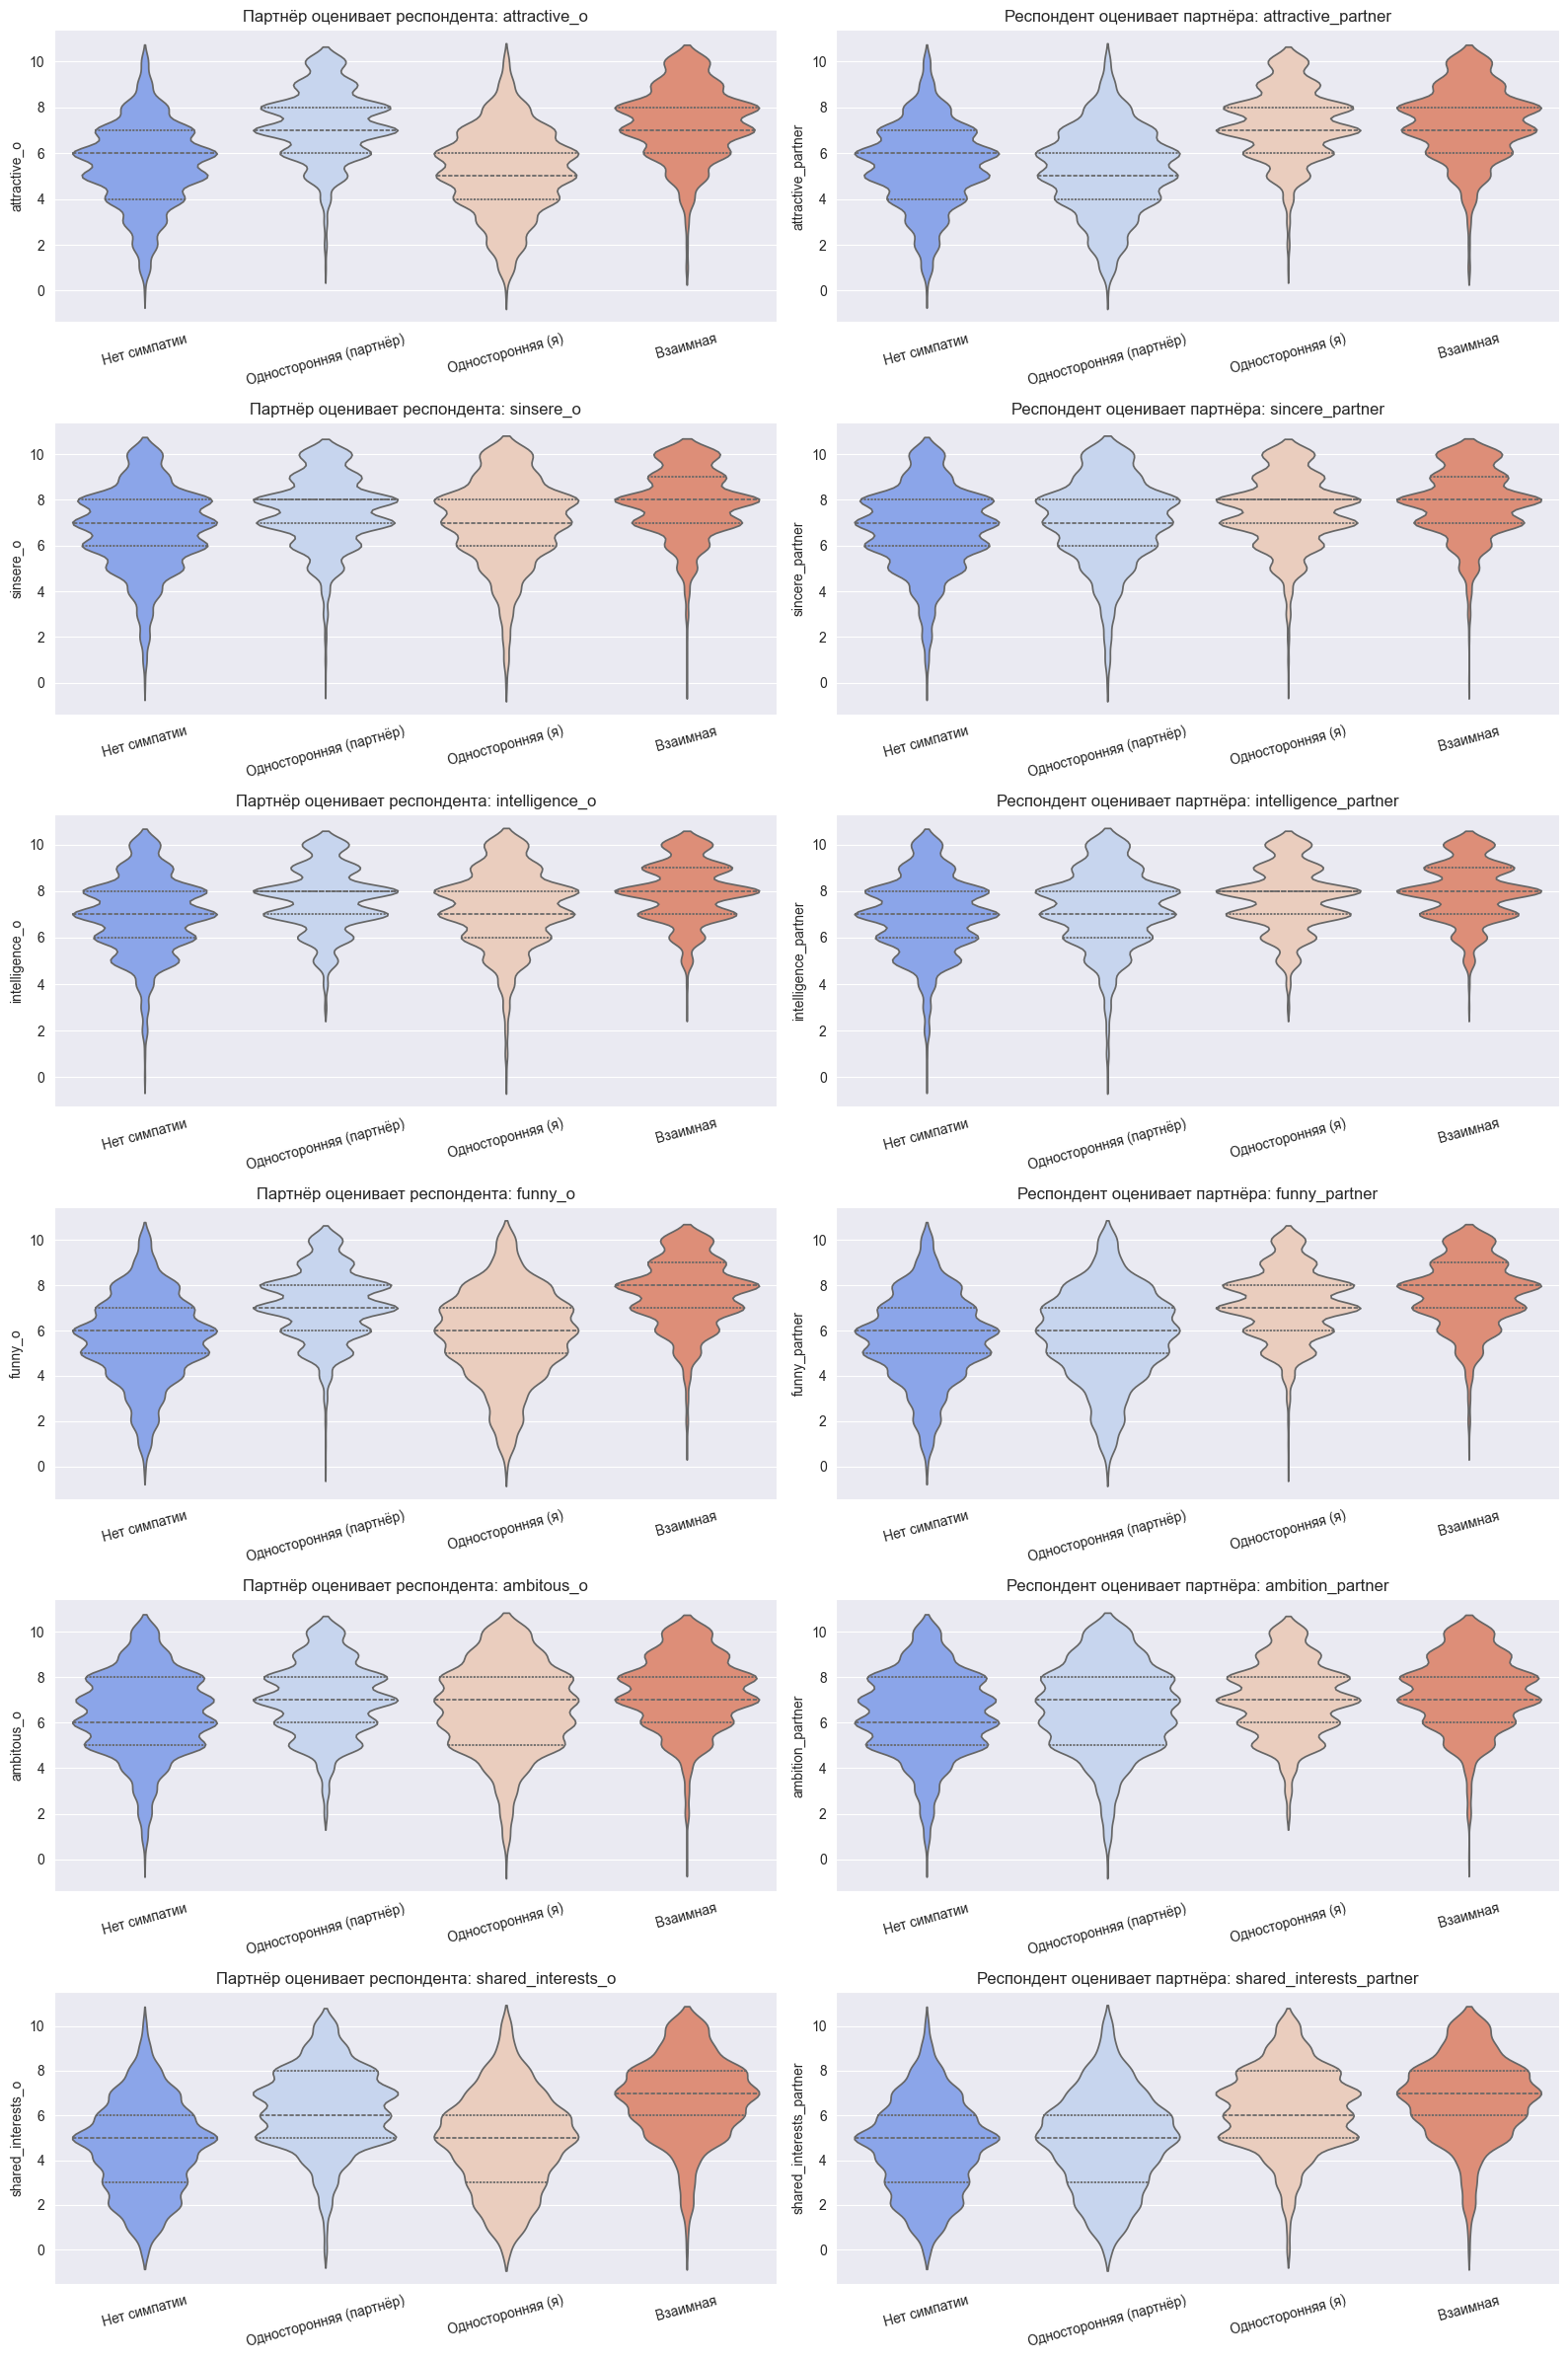

In [99]:
# Объединяем в пары для удобства: (как партнёр оценил респондента, как респондент оценил партнёра)
pairs = [
    ('attractive_o', 'attractive_partner'),
    ('sinsere_o', 'sincere_partner'),
    ('intelligence_o', 'intelligence_partner'),
    ('funny_o', 'funny_partner'),
    ('ambitous_o', 'ambition_partner'),
    ('shared_interests_o', 'shared_interests_partner'),
]

fig, axes = plt.subplots(6, 2, figsize=(16, 24))

for i, (col_o, col_partner) in enumerate(pairs):
    # Слева — как партнёр оценивает респондента 
    sns.violinplot(data=df_clean, x='interest_type', y=col_o, order=order, palette='coolwarm', inner='quart', ax=axes[i, 0])
    axes[i, 0].set_title(f'Партнёр оценивает респондента: {col_o}')
    axes[i, 0].set_xlabel('')
    axes[i, 0].tick_params(axis='x', rotation=15)
    
    # Справа — как респондент оценивает партнёра
    sns.violinplot(data=df_clean, x='interest_type', y=col_partner, order=order, palette='coolwarm', inner='quart', ax=axes[i, 1])
    axes[i, 1].set_title(f'Респондент оценивает партнёра: {col_partner}')
    axes[i, 1].set_xlabel('')
    axes[i, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [100]:
order = ['Нет симпатии', 'Односторонняя (партнёр)', 'Односторонняя (я)', 'Взаимная']

# Все 12 оценок: по 6 с каждой стороны
cols_to_summarize = [
    'attractive_o', 'sinsere_o', 'intelligence_o', 'funny_o', 'ambitous_o', 'shared_interests_o',
    'attractive_partner', 'sincere_partner', 'intelligence_partner', 
    'funny_partner', 'ambition_partner', 'shared_interests_partner'
]

# Средние значения по типам симпатии
pivot_mean = df_clean.groupby('interest_type')[cols_to_summarize].mean().reindex(order).round(2)

# Медианы (менее чувствительны к выбросам)
pivot_median = df_clean.groupby('interest_type')[cols_to_summarize].median().reindex(order).round(2)

# Количество наблюдений в каждой группе
pivot_count = df_clean.groupby('interest_type').size().reindex(order).to_frame('Количество')

print("Средние значения оценок по типам симпатии")
display(pivot_mean)

print("\nМедианные значения оценок по типам симпатии")
display(pivot_median)

print("\nКоличество наблюдений")
display(pivot_count)

Средние значения оценок по типам симпатии

,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner
interest_type,,,,,,,,,,,,
Нет симпатии,5.48,6.71,6.95,5.63,6.38,4.60,5.48,6.71,6.95,5.63,6.38,4.60
Односторонняя (партнёр),7.26,7.46,7.63,7.16,7.04,6.27,5.23,7.03,7.23,5.78,6.63,4.86
Односторонняя (я),5.23,7.03,7.23,5.78,6.63,4.86,7.26,7.46,7.63,7.16,7.04,6.27
Взаимная,7.32,7.81,7.95,7.60,7.33,6.75,7.32,7.81,7.95,7.60,7.33,6.75



Медианные значения оценок по типам симпатии

,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner
interest_type,,,,,,,,,,,,
Нет симпатии,6.0,7.0,7.0,6.0,6.0,5.0,6.0,7.0,7.0,6.0,6.0,5.0
Односторонняя (партнёр),7.0,8.0,8.0,7.0,7.0,6.0,5.0,7.0,7.0,6.0,7.0,5.0
Односторонняя (я),5.0,7.0,7.0,6.0,7.0,5.0,7.0,8.0,8.0,7.0,7.0,6.0
Взаимная,7.0,8.0,8.0,8.0,7.0,7.0,7.0,8.0,8.0,8.0,7.0,7.0



Количество наблюдений

,Количество
interest_type,
Нет симпатии,2725
Односторонняя (партнёр),2135
Односторонняя (я),2138
Взаимная,1380


Анализ выявил чёткую асимметрию: при односторонней симпатии одна сторона ставит высокие баллы, а другая — низкие. Это одна и та же картина, увиденная с двух сторон: каждая встреча записана двумя строками, поэтому категории «Односторонняя (я)» и «Односторонняя (партнёр)» зеркальны (средняя `attractive_o` в одной совпадает со средней `attractive_partner` в другой: 7,26 и 7,26, 5,23 и 5,23), а их размеры (2135 и 2138) — это по сути одни и те же встречи. Взаимная симпатия связана с высокими оценками с обеих сторон: средние 6,8–8,0, медианы 7–8. В группе «Нет симпатии» оценки обеих сторон держатся на уровне 4,6–7,0. Сильнее всего группы различаются по внешности, юмору и общим интересам: например, средняя оценка внешности — 5,5 против 7,3, юмора — 5,6 против 7,6, общих интересов — 4,6 против 6,8. Амбициозность различается слабее (6,4 против 7,3, медианы 6–7), но говорить, что она не влияет на исход, рано.

Рассмотрим роль общих интересов через корреляцию интересов `interests_correlate`. Колонки `d_*` для этого не подходят: это бины интереса самого респондента, а не разности между участниками (проверка ниже).

In [101]:
ru('interests_correlate')

'корреляция интересов'

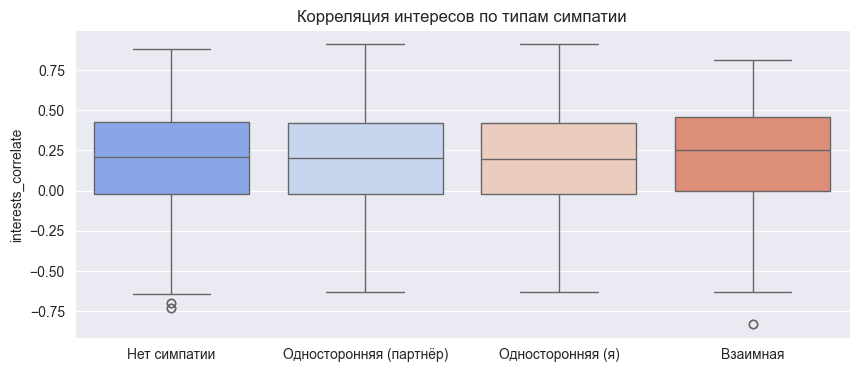

In [102]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_clean, x='interest_type', y='interests_correlate', order=order, palette='coolwarm')
plt.title('Корреляция интересов по типам симпатии')
plt.xlabel('')
plt.show()

In [103]:
pivot_corr = df_clean.groupby('interest_type')['interests_correlate'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).reindex(order).round(3)

pivot_corr.columns = ['Количество', 'Среднее', 'Медиана', 'Ст. отклонение', 'Минимум', 'Максимум']
display(pivot_corr)

,Количество,Среднее,Медиана,Ст. отклонение,Минимум,Максимум
interest_type,,,,,,
Нет симпатии,2671,0.189,0.210,0.310,-0.73,0.88
Односторонняя (партнёр),2098,0.193,0.205,0.298,-0.63,0.91
Односторонняя (я),2101,0.193,0.200,0.298,-0.63,0.91
Взаимная,1350,0.217,0.250,0.307,-0.83,0.81


In [104]:
# d_* — не разности между участниками, а бины исходного признака самого респондента.
# Проверка: бин определяется уровнем исходной колонки самого респондента, а пропуски исходной колонки попадают в нижний бин
for col in ['art', 'music', 'gaming', 'attractive_partner']:
    print(f"\n{col}: диапазон значений внутри бинов d_{col}")
    display(df.groupby('d_' + col)[col].agg(['count', 'min', 'max']))
    print(f"бин d_{col} у строк с пропуском в {col}:", df.loc[df[col].isna(), 'd_' + col].value_counts().to_dict())

both = df['age'].notna() & df['age_o'].notna()
print("\nd_age = |age − age_o| во всех строках с известными возрастами:",
      (df.loc[both, 'd_age'] == (df.loc[both, 'age'] - df.loc[both, 'age_o']).abs()).all())


art: диапазон значений внутри бинов d_art

,count,min,max
d_art,,,
[0-5],2474,0.0,5.0
[6-8],3994,6.0,8.0
[9-10],1831,9.0,10.0


бин d_art у строк с пропуском в art: {'[0-5]': 79}

music: диапазон значений внутри бинов d_music

,count,min,max
d_music,,,
[0-5],936,1.0,5.0
[6-8],3941,6.0,8.0
[9-10],3422,9.0,10.0


бин d_music у строк с пропуском в music: {'[0-5]': 79}

gaming: диапазон значений внутри бинов d_gaming

,count,min,max
d_gaming,,,
[0-5],6030,0.0,5.0
[6-8],1924,6.0,8.0
[9-10],345,9.0,14.0


бин d_gaming у строк с пропуском в gaming: {'[0-5]': 79}

attractive_partner: диапазон значений внутри бинов d_attractive_partner

,count,min,max
d_attractive_partner,,,
[0-5],2761,0.0,5.0
[6-8],4545,6.0,8.0
[9-10],870,8.5,10.0


бин d_attractive_partner у строк с пропуском в attractive_partner: {'[0-5]': 202}

d_age = |age − age_o| во всех строках с известными возрастами: True

Средняя корреляция интересов у взаимных пар немного выше, чем в остальных группах (0,217 против 0,189–0,193), медиана тоже выше (0,25 против 0,20–0,21); статистическая значимость различия не оценивалась. Колонки `d_*` оказались бинами признака самого респондента: бин определяется уровнем исходной колонки (значения выше 10 и полубаллы попадают в соседний бин: 14 в `gaming` и 8,5 в `attractive_partner` — в `[9-10]`), а пропуски попадают в нижний бин. Поэтому судить по ним о различиях в хобби между партнёрами нельзя — для этого нужно по восстановленным парам посчитать разницу интересов по каждой активности.

In [105]:
ru('like')

'насколько понравился партнёр (шкала 1–10)'

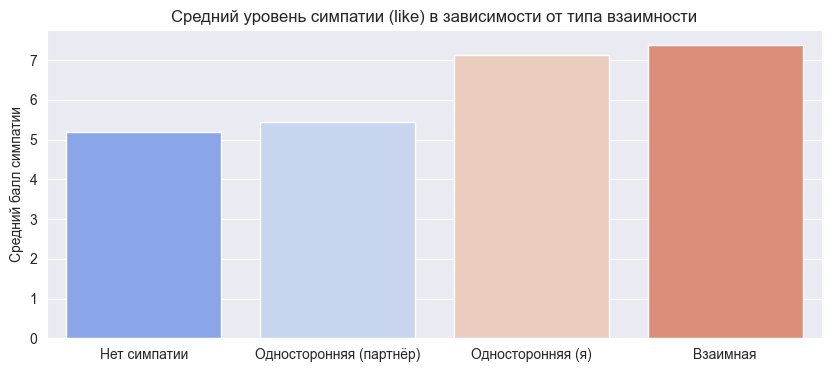

In [106]:
# Сравнение односторонней и взаимной симпатии
plt.figure(figsize=(10, 4))
# Смотрим на среднюю симпатию к партнёру
sns.barplot(data=df_clean, x='interest_type', y='like', order=order, palette='coolwarm', errorbar=None)
plt.title('Средний уровень симпатии (like) в зависимости от типа взаимности')
plt.xlabel('')
plt.ylabel('Средний балл симпатии')
plt.show()

Сравнение односторонней и взаимной симпатии. Уровень симпатии (like) чётко отражает исход: самый низкий он при отсутствии симпатии (5,2), а самый высокий при взаимной (7,4). При односторонней симпатии со стороны партнёра уровень like остаётся низким (5,5), а при собственной («Односторонняя (я)») — высокий (7,1): like связан прежде всего с собственным решением респондента, а не с решением партнёра.

In [107]:
ru('guess_prob_liked')

'насколько вероятным я считаю «да» от партнёра (шкала 1–10)'

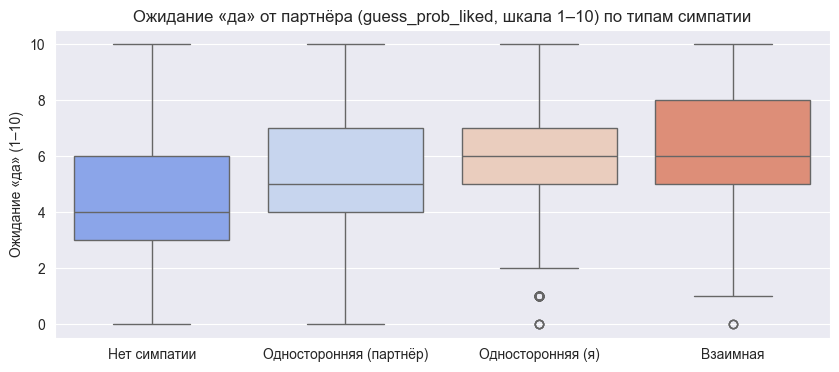

,доля «да» партнёра,доля собственных «да»,n
guess_prob_liked,,,
0.0,0.31,0.14,49
1.0,0.32,0.14,415
2.0,0.37,0.16,540
3.0,0.33,0.25,708
4.0,0.37,0.32,936
5.0,0.41,0.42,1799
6.0,0.41,0.53,1403
7.0,0.49,0.58,1130
8.0,0.54,0.62,659


In [108]:
# Насколько участники угадывают интерес
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_clean, x='interest_type', y='guess_prob_liked', order=order, palette='coolwarm')
plt.title('Ожидание «да» от партнёра (guess_prob_liked, шкала 1–10) по типам симпатии')
plt.xlabel('')
plt.ylabel('Ожидание «да» (1–10)')
plt.show()

# Сравним ожидание с решением партнёра и с собственным решением
guess = df_clean['guess_prob_liked'].round()
display(df_clean.groupby(guess)[['decision_o', 'decision']].mean().round(2)
        .assign(n=df_clean.groupby(guess).size())
        .rename(columns={'decision_o': 'доля «да» партнёра', 'decision': 'доля собственных «да»'}))

Насколько участники угадывают интерес. Медианное ожидание взаимности (guess_prob_liked) минимально при отсутствии симпатии (4), а максимально (6) там, где «да» сказал сам респондент: в категориях «Односторонняя (я)» и «Взаимная». Таблица под графиком показывает то же: с ростом ожидания доля собственных «да» растёт с 14% до 68%, а доля «да» партнёра — лишь с 31% до 67%; при низких ожиданиях (0–2 балла) партнёр всё равно говорит «да» в 31–37% случаев. То есть ожидание связано с решением партнёра слабее, чем с собственным решением: участники скорее переносят на партнёра свою симпатию, чем точно считывают его отношение.

**Общий вывод по разделу:** Взаимная симпатия связана с высокими оценками с обеих сторон: в группе взаимных совпадений оба участника в среднем выше оценивают внешность, юмор, интеллект и общие интересы друг друга. При односторонней симпатии одна сторона ставит высокие баллы, другая — низкие; категории «Односторонняя (я)» и «Односторонняя (партнёр)» — это одни и те же встречи, увиденные с двух сторон, так как каждая встреча записана двумя строками. Уровень симпатии `like` связан прежде всего с собственным решением респондента, а не с решением партнёра. Корреляция интересов у взаимных пар немного выше, чем в остальных группах; значимость различия не проверялась, а о различиях в отдельных хобби по колонкам `d_*` судить нельзя — это бины интереса самого респондента. Ожидание взаимности `guess_prob_liked` сильнее связано с собственным решением респондента, чем с решением партнёра: участники скорее переносят на партнёра свою симпатию, чем точно считывают его отношение. Все выводы раздела — описательные связи, а не причинные: оценки собраны после встречи, а группы определены через решения участников.

## Построение моделей

Опираясь на предыдущие выводы (слабая связь демографии и корреляции интересов с матчем, важность взаимных оценок), можно сформулировать следующие гипотезы для проверки и построения моделей:

**Гипотеза 1. Взаимные субъективные оценки важнее самооценок.**  
С матчем связаны высокие оценки с обеих сторон (внешность, юмор, общие интересы). При этом то, насколько человек высоко оценивает *себя*, само по себе не гарантирует матч.  
*Ожидаемый результат:* признаки групп `*_o` (оценки, которые партнёр поставил респонденту) и `*_partner` (оценки, которые респондент поставил партнёру) окажутся наиболее значимыми в моделях, а самооценки — слабыми предикторами.

**Гипотеза 2. `like` и `guess_prob_liked` — late-proxy признаки, упрощающие задачу.**  
Переменная `like` (насколько партнёр понравился участнику) и `guess_prob_liked` (ожидание взаимности) собираются в той же анкете после встречи, что и оценки партнёра, но ближе всего к собственному решению участника (см. анализ `like` и `guess_prob_liked` выше). Поэтому в базовое решение они не войдут.  
*Ожидаемый результат:* метрики late-proxy модели будут выше, чем у основной; сравнение двух подходов покажет, насколько эти поля упрощают задачу.

**Гипотеза 3. Демография и корреляция интересов слабо связаны с матчем.**  
Возраст, раса и разница в возрасте слабо связаны с вероятностью матча. Общая корреляция интересов (`interests_correlate`) также не является значимым предиктором — её вклад в модель будет близок к нулю. Пол из этой гипотезы убран: доля match у мужских и женских строк одинакова по построению (см. гипотезу 7).  
*Ожидаемый результат:* низкая важность этих признаков; возможное исключение их из финальной модели без потери качества.

**Гипотеза 4. Амбициозность — вторичный фактор.**  
В отличие от внешности и юмора, амбициозность (своя и партнёра) слабо влияет на исход свидания. Мы не ожидаем, что этот признак войдёт в топ значимых.  
*Ожидаемый результат:* низкие коэффициенты важности у `ambition`, `ambitous_o`, `ambition_partner`.

**Гипотеза 5. Различия в отдельных хобби могут быть связаны с матчем.**  
В EDA это не проверено: колонки `d_*` — бины интереса самого респондента, а не разности между участниками, поэтому прежний вывод про искусство, музыку и концерты снят. Чтобы проверить гипотезу, нужно по восстановленным парам посчитать разницу интересов по каждой активности (|интерес респондента − интерес партнёра|).  
*Ожидаемый результат:* проверим вместе с парными признаками из гипотезы 8.

**Гипотеза 6. Несбалансированность классов требует особого подхода.**  
Поскольку матчи составляют около 16% наблюдений, стандартные модели могут смещаться в сторону класса «несовпадение».  
*Ожидаемый результат:* для качественного прогноза потребуется балансировка классов (`class_weight`, SMOTE и т.д.) и использование метрик вроде PR-AUC, F1-score, ROC-AUC вместо Accuracy.

**Гипотеза 7. Пол связан с индивидуальным решением, а не с долей match.**  
Одинаковая доля совпадений у мужчин и женщин (по 16,5%) получается по построению: каждая встреча записана двумя строками — от каждого участника, поэтому каждый матч попадает и в мужскую, и в женскую строку. Проверять влияние пола на `match` по строкам поэтому бессмысленно. Различие есть в решениях: женщины говорят «да» реже мужчин (см. раздел «Анализ зависимой переменной»).  
*Ожидаемый результат:* важность `gender` проверим в моделях; равенство долей match по полу само по себе ничего не доказывает.

**Гипотеза 8. Инжиниринг парных признаков улучшит модель.**  
Исходные оценки сами по себе содержат много шума; производные признаки (например, разности между самооценкой и оценкой партнёра, средние оценки пары по каждому качеству, абсолютные разницы) лучше отражают взаимную совместимость и повысят качество модели по сравнению с использованием только исходных оценок.  
*Ожидаемый результат:* сравнение на одном split покажет прирост PR-AUC у модели с engineered pair features относительно модели только на исходных оценках.